<a href="https://colab.research.google.com/github/shafi21001/fruit-freshness-edge-ai-study/blob/main/notebooks/02_dataset_quality_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd
import numpy as np

# Research root directory
ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

# Final reconciliation directory
AUDIT_DIR = ROOT / "datasets" / "audit" / "final_reconciliation"

# QC notebook output directory
QC_DIR = ROOT / "datasets" / "audit" / "quality_control"
QC_DIR.mkdir(parents=True, exist_ok=True)

# Load the retained dataset manifest (before image-quality QC)
manifest_path = AUDIT_DIR / "retained_pending_final_qc.csv"

df = pd.read_csv(manifest_path)

print("Manifest loaded successfully!")
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
print("Unique SHA-256 hashes:", df["sha256"].nunique())

display(df.head())


Mounted at /content/drive
Manifest loaded successfully!
Rows: 6911
Columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine']
Unique SHA-256 hashes: 4865


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine
0,AFruitDB,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
1,AFruitDB,IMG_20230930_172429.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1173056,f2a4aa7eb44d3d55da034eab8f9192a167ee501a433037...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
2,AFruitDB,IMG_20230930_172432.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1179042,7d142228f2983320288d16186fd406c85a8b20e3d25739...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
3,AFruitDB,IMG_20230930_172439.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1140016,1d791349b86caa51efe1adf9c62cc70459498a4c909390...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
4,AFruitDB,IMG_20230930_172444.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1178878,6054012b993e207c9eb97b82a18c454131b30674eeea6f...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True


In [ ]:
# ============================================
# STEP 2: DATASET STRUCTURE & CLASS DISTRIBUTION
# ============================================

# One row per unique image content
unique_df = df.drop_duplicates(subset="sha256").copy()

print("SOURCE RECORDS:", len(df))
print("UNIQUE IMAGE CONTENTS:", len(unique_df))
print("DUPLICATE SOURCE RECORDS:", len(df) - len(unique_df))

print("\nMissing values:")
display(df.isna().sum())

print("\nUnique fruits:")
print(sorted(unique_df["fruit"].dropna().unique()))

print("\nUnique grades:")
print(sorted(unique_df["grade"].dropna().unique()))

# Class distribution based on unique image contents
class_counts = (
    unique_df.groupby(["fruit", "grade"])
    .size()
    .reset_index(name="unique_images")
    .sort_values(["fruit", "grade"])
)

print("\nFRUIT-GRADE CLASS DISTRIBUTION (UNIQUE IMAGES)")
display(class_counts)

print("\nNumber of classes:", len(class_counts))

# Check for missing or unexpected labels
print("\nMissing fruit labels:", unique_df["fruit"].isna().sum())
print("Missing grade labels:", unique_df["grade"].isna().sum())
print("Missing hashes:", df["sha256"].isna().sum())

SOURCE RECORDS: 6911
UNIQUE IMAGE CONTENTS: 4865
DUPLICATE SOURCE RECORDS: 2046

Missing values:


,0
dataset,0
filename,0
relative_path,0
fruit,0
grade,0
file_size,0
sha256,0
duplicate_group_id,0
duplicate_group_unique_hashes,0
quarantine_reason,6911



Unique fruits:
['Apple', 'Banana', 'Burmese_grape', 'Jujube', 'Mango', 'Papayas', 'Tomatoes']

Unique grades:
['1st grade', '2nd grade', '3rd grade']

FRUIT-GRADE CLASS DISTRIBUTION (UNIQUE IMAGES)


,fruit,grade,unique_images
0,Apple,1st grade,198
1,Apple,2nd grade,172
2,Apple,3rd grade,112
3,Banana,1st grade,486
4,Banana,2nd grade,478
5,Banana,3rd grade,131
6,Burmese_grape,1st grade,616
7,Burmese_grape,2nd grade,314
8,Burmese_grape,3rd grade,330
9,Jujube,1st grade,149



Number of classes: 21

Missing fruit labels: 0
Missing grade labels: 0
Missing hashes: 0


In [ ]:
# ============================================
# STEP 3: LOCATE DATASET IMAGE FOLDERS
# ============================================

DATA_DIR = ROOT / "datasets"

print("Dataset directory exists:", DATA_DIR.exists())
print("\nFolders and files inside datasets/:")

for item in DATA_DIR.iterdir():
    if item.is_dir():
        print(f"[DIR]  {item.name}")
    else:
        print(f"[FILE] {item.name}")

print("\nSearching for likely extracted image directories...")

for p in DATA_DIR.rglob("*"):
    if p.is_dir() and p.name.lower() in [
        "afruitdb",
        "bangladeshi_fruit_grade",
        "fruits grade",
        "fruit grade"
    ]:
        print(p)

Dataset directory exists: True

Folders and files inside datasets/:
[DIR]  original
[DIR]  extracted
[DIR]  audit

Searching for likely extracted image directories...


In [ ]:
# ============================================
# STEP 4: INSPECT ORIGINAL DATASET ARCHIVES
# ============================================

import zipfile

ORIGINAL_DIR = ROOT / "datasets" / "original"

for archive_path in ORIGINAL_DIR.glob("*.zip"):

    print("\n" + "=" * 60)
    print("ARCHIVE:", archive_path.name)
    print("SIZE (MB):", round(archive_path.stat().st_size / (1024**2), 2))

    try:
        with zipfile.ZipFile(archive_path, "r") as z:
            members = z.namelist()

            image_files = [
                p for p in members
                if p.lower().endswith((
                    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
                ))
            ]

            nested_zips = [
                p for p in members
                if p.lower().endswith(".zip")
            ]

            print("Total archive entries:", len(members))
            print("Image files:", len(image_files))
            print("Nested ZIP files:", nested_zips[:10])

            print("\nFirst 10 image paths:")
            for p in image_files[:10]:
                print(" ", p)

    except Exception as e:
        print("ERROR:", repr(e))


ARCHIVE: Bangladeshi_Fruit_Grade_original.zip
SIZE (MB): 2599.94
Total archive entries: 3757
Image files: 3756
Nested ZIP files: []

First 10 image paths:
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172513.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172505.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172456.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172439.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172432.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172444.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172500.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172509.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172429.jpg
  Bangl

In [ ]:
import zipfile
from pathlib import Path

ORIGINAL_DIR = ROOT / "datasets" / "original"

bd_zip_path = ORIGINAL_DIR / "Bangladeshi_Fruit_Grade_original.zip"
af_zip_path = ORIGINAL_DIR / "AFruitDB_original.zip"

# Check Bangladeshi dataset paths
with zipfile.ZipFile(bd_zip_path, "r") as z:
    bd_members = set(z.namelist())

    bd_manifest = df[df["dataset"].str.contains("Bangladeshi", case=False, na=False)]

    bd_matches = bd_manifest["relative_path"].isin(bd_members)

    print("BANGLADESHI DATASET")
    print("Manifest rows:", len(bd_manifest))
    print("Paths matched:", bd_matches.sum())
    print("Paths missing:", (~bd_matches).sum())

# Check AFruitDB nested ZIP structure
with zipfile.ZipFile(af_zip_path, "r") as outer:
    nested_zip_path = [
        p for p in outer.namelist()
        if p.lower().endswith(".zip")
    ][0]

    print("\nAFRUITDB")
    print("Nested ZIP:", nested_zip_path)

    # Read nested ZIP metadata into memory (not extracted to Drive)
    nested_bytes = outer.read(nested_zip_path)

    from io import BytesIO

    with zipfile.ZipFile(BytesIO(nested_bytes), "r") as inner:
        af_members = set(inner.namelist())

        af_manifest = df[df["dataset"].str.contains("AFruitDB", case=False, na=False)]

        af_matches = af_manifest["relative_path"].isin(af_members)

        print("Manifest rows:", len(af_manifest))
        print("Paths matched:", af_matches.sum())
        print("Paths missing:", (~af_matches).sum())

BANGLADESHI DATASET
Manifest rows: 0
Paths matched: 0
Paths missing: 0

AFRUITDB
Nested ZIP: A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip
Manifest rows: 3161
Paths matched: 3161
Paths missing: 0


In [ ]:
print("Dataset values in manifest:")
print(df["dataset"].value_counts(dropna=False))

Dataset values in manifest:
dataset
Expanded    3750
AFruitDB    3161
Name: count, dtype: int64


In [ ]:
# Correct dataset identifier: "Expanded"

bd_manifest = df[df["dataset"] == "Expanded"]

with zipfile.ZipFile(bd_zip_path, "r") as z:
    bd_members = set(z.namelist())

    bd_matches = bd_manifest["relative_path"].isin(bd_members)

    print("BANGLADESHI / EXPANDED DATASET")
    print("Manifest rows:", len(bd_manifest))
    print("Paths matched:", bd_matches.sum())
    print("Paths missing:", (~bd_matches).sum())

    # Show a few missing paths, if any
    if (~bd_matches).sum() > 0:
        print("\nFirst missing paths:")
        print(bd_manifest.loc[~bd_matches, "relative_path"].head(10).to_list())

BANGLADESHI / EXPANDED DATASET
Manifest rows: 3750
Paths matched: 3750
Paths missing: 0


In [ ]:
import random
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import zipfile

# Reproducible sample
SEED = 20261122
SAMPLES_PER_CLASS = 3

expanded_unique = (
    df[df["dataset"] == "Expanded"]
    .drop_duplicates(subset="sha256")
    .copy()
)

expanded_unique["class_label"] = (
    expanded_unique["fruit"].astype(str)
    + " | "
    + expanded_unique["grade"].astype(str)
)

sample_df = (
    expanded_unique.groupby("class_label", group_keys=False)
    .sample(n=SAMPLES_PER_CLASS, random_state=SEED)
)

print("Sample size:", len(sample_df))
print("Number of classes:", sample_df["class_label"].nunique())
print("Samples per class:")
print(sample_df["class_label"].value_counts().sort_index())

Sample size: 63
Number of classes: 21
Samples per class:
class_label
Apple | 1st grade            3
Apple | 2nd grade            3
Apple | 3rd grade            3
Banana | 1st grade           3
Banana | 2nd grade           3
Banana | 3rd grade           3
Burmese_grape | 1st grade    3
Burmese_grape | 2nd grade    3
Burmese_grape | 3rd grade    3
Jujube | 1st grade           3
Jujube | 2nd grade           3
Jujube | 3rd grade           3
Mango | 1st grade            3
Mango | 2nd grade            3
Mango | 3rd grade            3
Papayas | 1st grade          3
Papayas | 2nd grade          3
Papayas | 3rd grade          3
Tomatoes | 1st grade         3
Tomatoes | 2nd grade         3
Tomatoes | 3rd grade         3
Name: count, dtype: int64


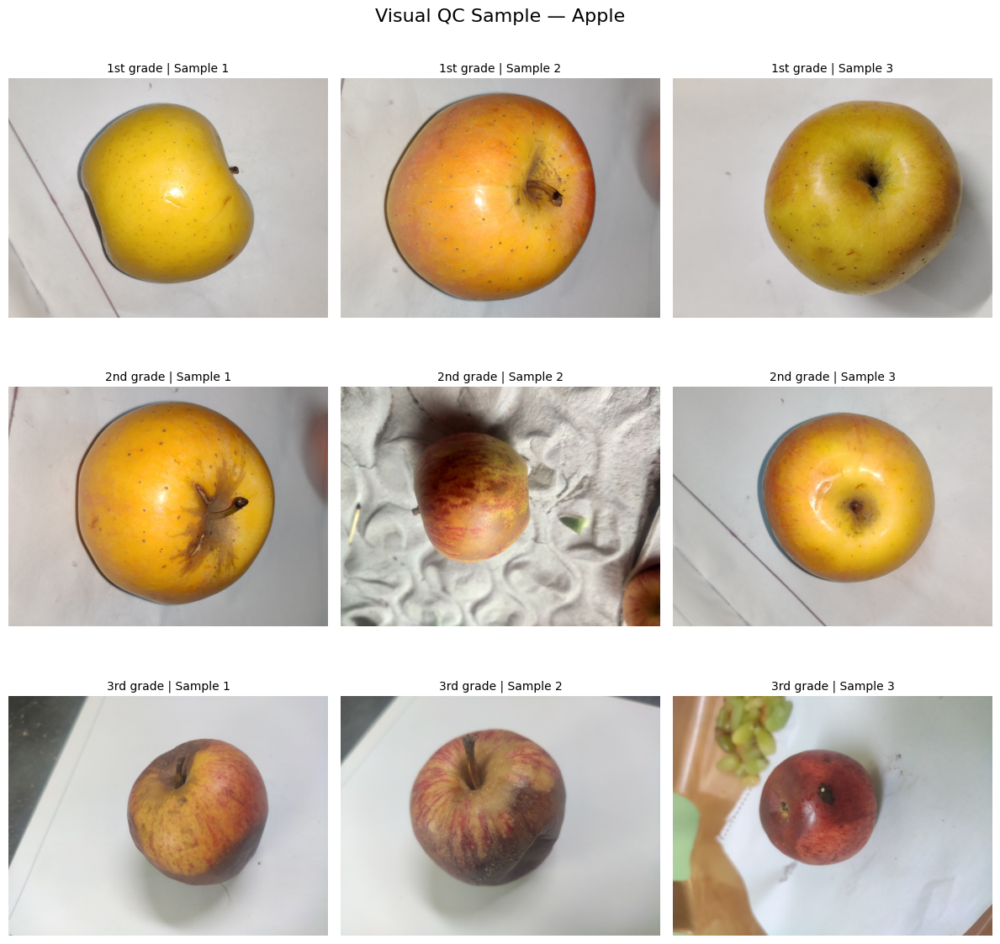

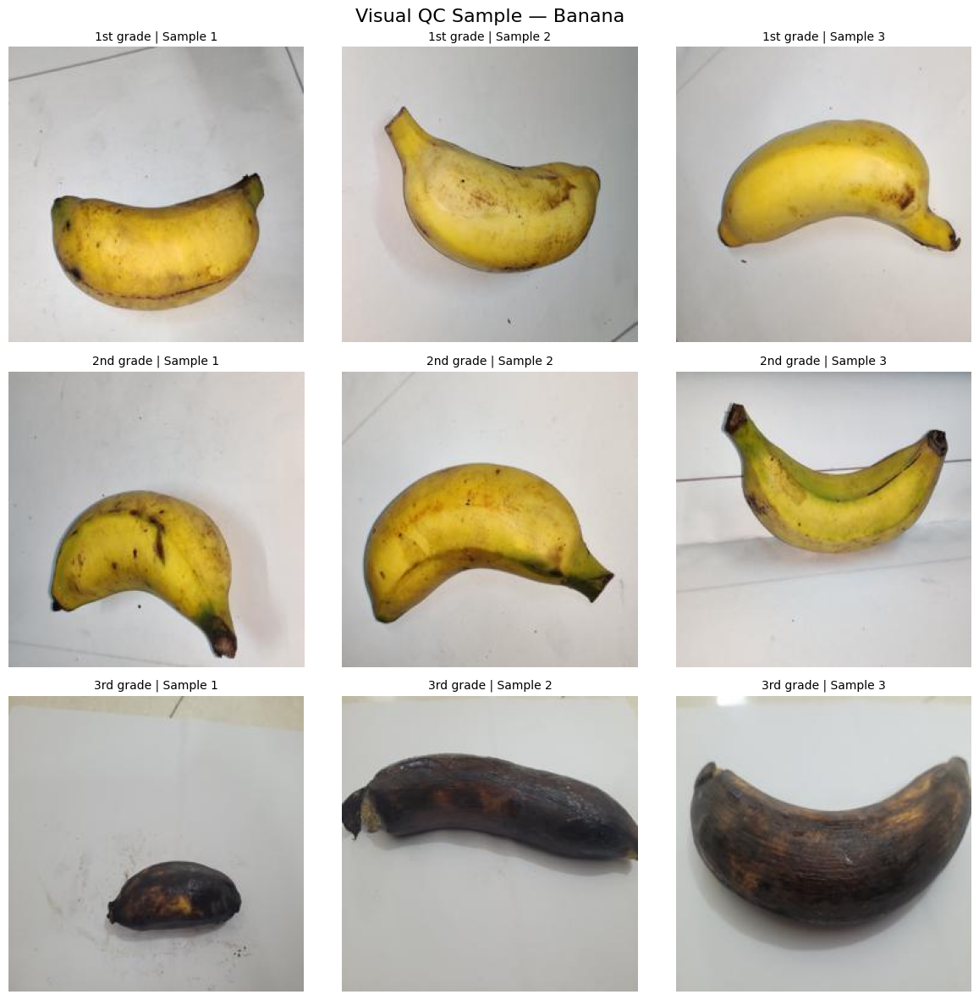

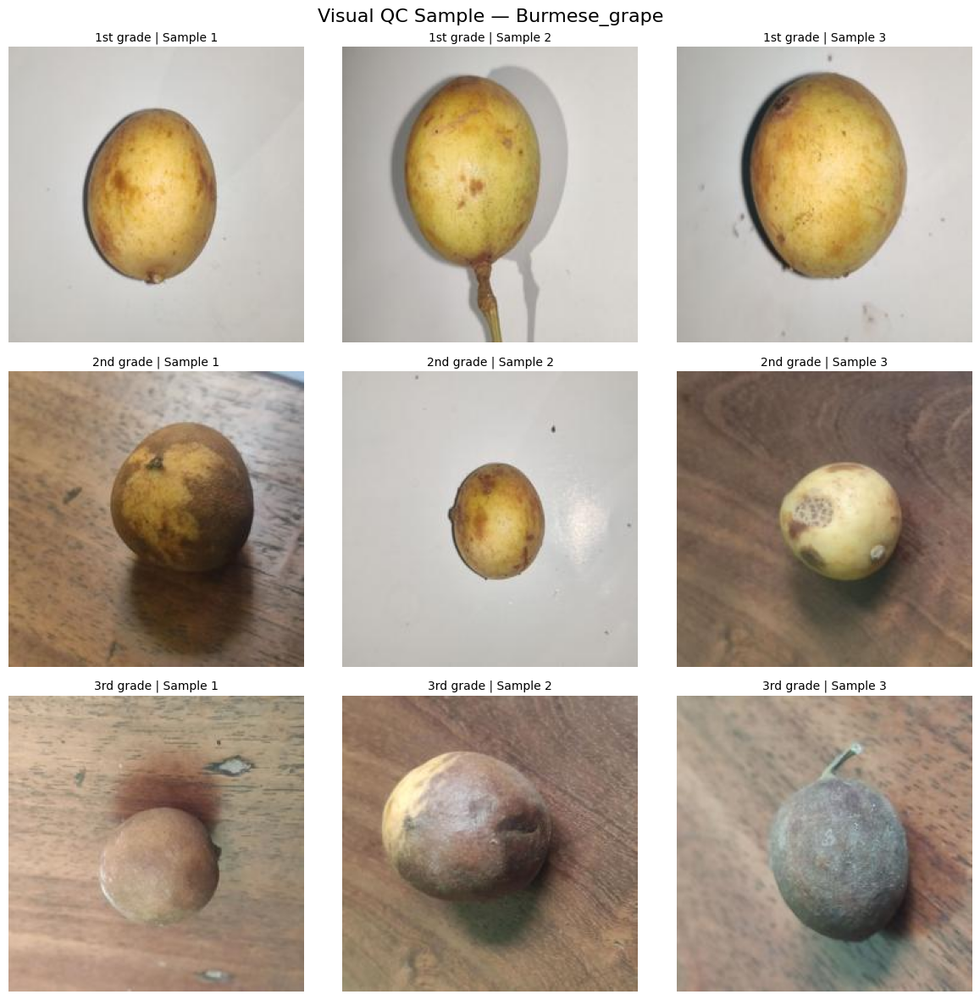

In [ ]:
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import zipfile

FRUITS_TO_REVIEW = ["Apple", "Banana", "Burmese_grape"]

grade_order = ["1st grade", "2nd grade", "3rd grade"]

with zipfile.ZipFile(bd_zip_path, "r") as archive:

    for fruit_name in FRUITS_TO_REVIEW:

        fruit_samples = sample_df[
            sample_df["fruit"] == fruit_name
        ]

        fig, axes = plt.subplots(
            3, 3,
            figsize=(12, 12)
        )

        fig.suptitle(
            f"Visual QC Sample — {fruit_name}",
            fontsize=16
        )

        for row, grade_name in enumerate(grade_order):

            grade_samples = fruit_samples[
                fruit_samples["grade"] == grade_name
            ].reset_index(drop=True)

            for col in range(3):

                ax = axes[row, col]
                ax.axis("off")

                if col >= len(grade_samples):
                    continue

                record = grade_samples.iloc[col]
                image_path = record["relative_path"]

                try:
                    image_bytes = archive.read(image_path)

                    image = Image.open(
                        BytesIO(image_bytes)
                    ).convert("RGB")

                    ax.imshow(image)

                    ax.set_title(
                        f"{grade_name} | Sample {col+1}",
                        fontsize=10
                    )

                except Exception as e:

                    ax.set_title(
                        f"IMAGE ERROR\n{str(e)[:50]}",
                        color="red"
                    )

        plt.tight_layout()
        plt.show()

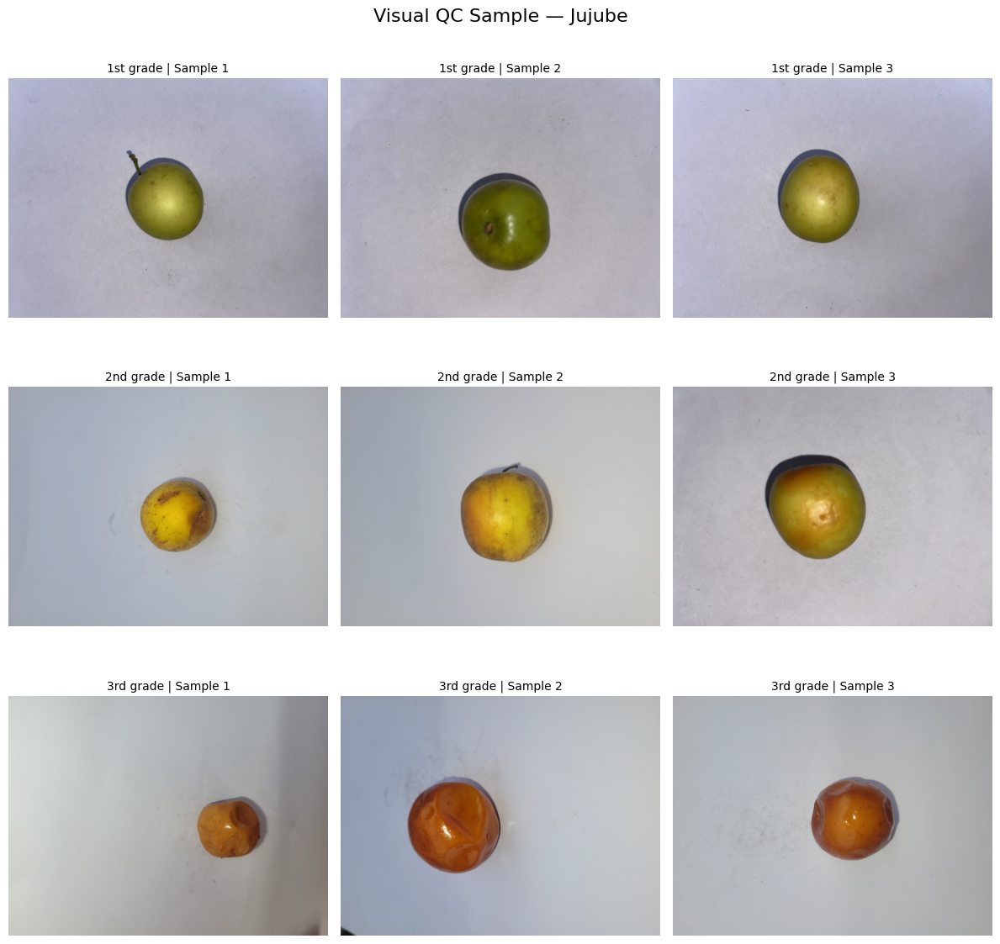

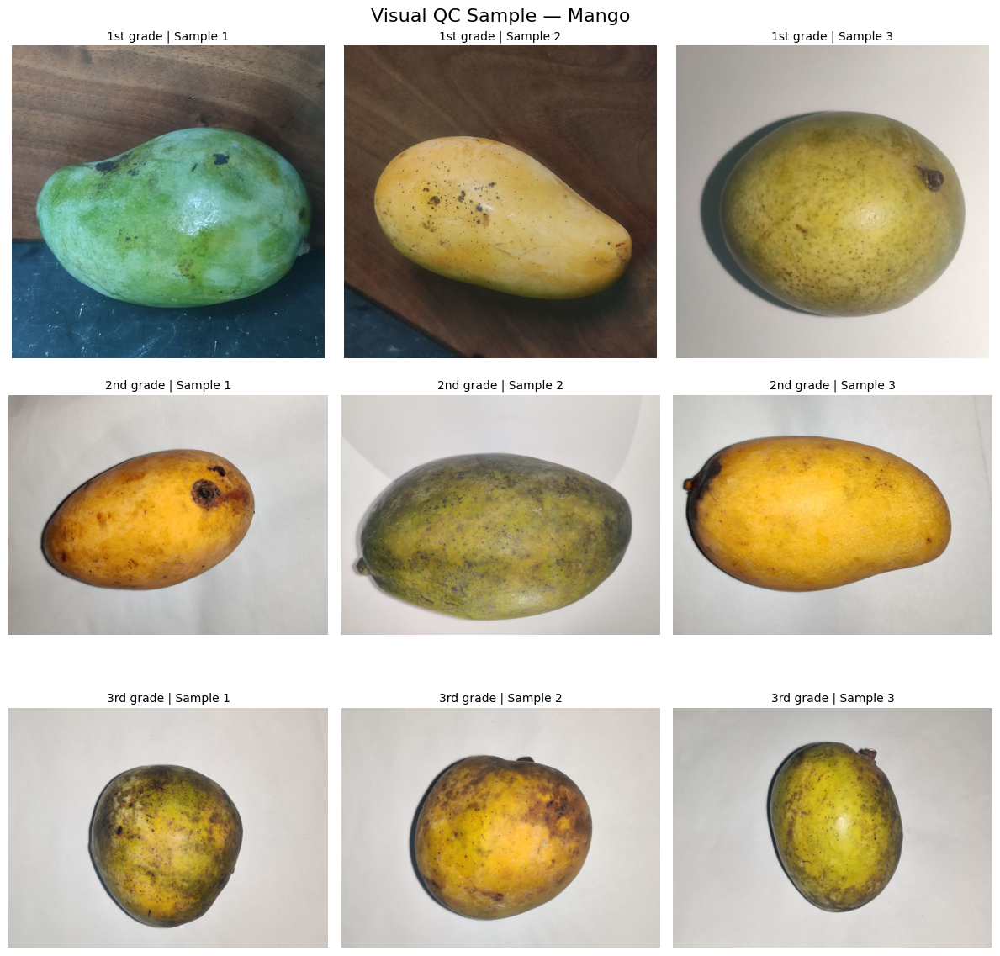

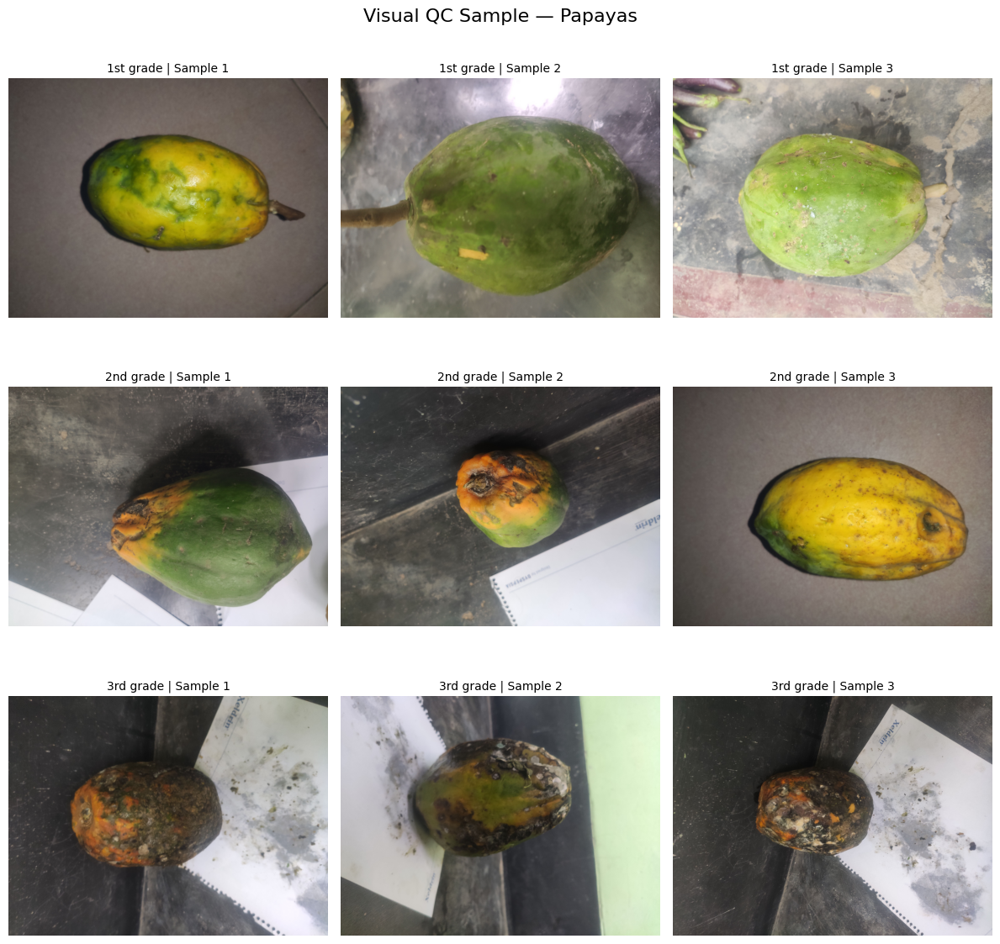

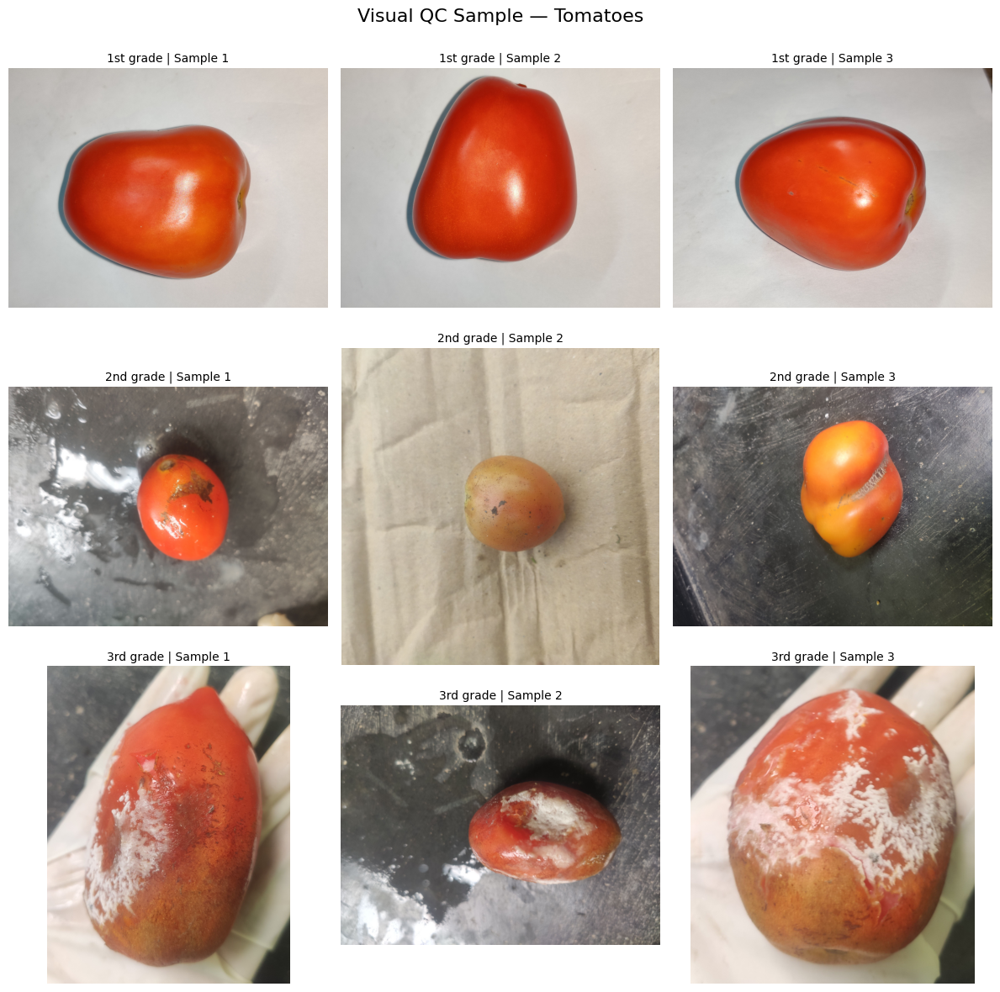

In [ ]:
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import zipfile

FRUITS_TO_REVIEW = ["Jujube", "Mango", "Papayas", "Tomatoes"]
grade_order = ["1st grade", "2nd grade", "3rd grade"]

with zipfile.ZipFile(bd_zip_path, "r") as archive:

    for fruit_name in FRUITS_TO_REVIEW:

        fruit_samples = sample_df[
            sample_df["fruit"] == fruit_name
        ]

        fig, axes = plt.subplots(3, 3, figsize=(12, 12))

        fig.suptitle(
            f"Visual QC Sample — {fruit_name}",
            fontsize=16
        )

        for row, grade_name in enumerate(grade_order):

            grade_samples = fruit_samples[
                fruit_samples["grade"] == grade_name
            ].reset_index(drop=True)

            for col in range(3):

                ax = axes[row, col]
                ax.axis("off")

                if col >= len(grade_samples):
                    continue

                record = grade_samples.iloc[col]
                image_path = record["relative_path"]

                try:
                    image_bytes = archive.read(image_path)

                    image = Image.open(
                        BytesIO(image_bytes)
                    ).convert("RGB")

                    ax.imshow(image)
                    ax.set_title(
                        f"{grade_name} | Sample {col+1}",
                        fontsize=10
                    )

                except Exception as e:
                    ax.set_title(
                        f"IMAGE ERROR\n{str(e)[:50]}",
                        color="red"
                    )

        plt.tight_layout()
        plt.show()

In [ ]:
import zipfile
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from io import BytesIO
from tqdm.auto import tqdm

# -------------------------
# Configuration
# -------------------------
QC_DIR.mkdir(parents=True, exist_ok=True)

QC_ARCHIVE = bd_zip_path
QC_MANIFEST = df[df["dataset"] == "Expanded"].copy()

# Exploratory screening thresholds (NOT deletion criteria)
MIN_WIDTH = 128
MIN_HEIGHT = 128
BLUR_THRESHOLD = 100.0
DARK_THRESHOLD = 30.0
BRIGHT_THRESHOLD = 225.0

qc_records = []

# -------------------------
# Scan images
# -------------------------
with zipfile.ZipFile(QC_ARCHIVE, "r") as archive:

    for _, row in tqdm(
        QC_MANIFEST.iterrows(),
        total=len(QC_MANIFEST),
        desc="Scanning images"
    ):

        image_path = row["relative_path"]

        record = {
            "dataset": row["dataset"],
            "relative_path": image_path,
            "sha256": row["sha256"],
            "fruit": row["fruit"],
            "grade": row["grade"],
            "file_size_manifest": row["file_size"],
            "width": None,
            "height": None,
            "brightness_mean": None,
            "brightness_std": None,
            "laplacian_variance": None,
            "decode_ok": False,
            "error": None
        }

        try:
            image_bytes = archive.read(image_path)

            # Decode image
            image = Image.open(BytesIO(image_bytes))
            image.load()

            record["width"], record["height"] = image.size
            record["decode_ok"] = True

            # Convert to grayscale for image quality metrics
            gray = np.array(image.convert("L"))

            record["brightness_mean"] = float(gray.mean())
            record["brightness_std"] = float(gray.std())

            # Blur/sharpness screening metric
            laplacian = cv2.Laplacian(
                gray,
                cv2.CV_64F
            )

            record["laplacian_variance"] = float(
                laplacian.var()
            )

        except Exception as e:
            record["error"] = str(e)

        qc_records.append(record)

# -------------------------
# Create QC results table
# -------------------------
qc_results = pd.DataFrame(qc_records)

# -------------------------
# Exploratory flags
# -------------------------
qc_results["flag_small"] = (
    (qc_results["width"] < MIN_WIDTH)
    | (qc_results["height"] < MIN_HEIGHT)
)

qc_results["flag_blur"] = (
    qc_results["laplacian_variance"] < BLUR_THRESHOLD
)

qc_results["flag_dark"] = (
    qc_results["brightness_mean"] < DARK_THRESHOLD
)

qc_results["flag_bright"] = (
    qc_results["brightness_mean"] > BRIGHT_THRESHOLD
)

qc_results["any_quality_flag"] = (
    qc_results["flag_small"]
    | qc_results["flag_blur"]
    | qc_results["flag_dark"]
    | qc_results["flag_bright"]
    | (~qc_results["decode_ok"])
)

# -------------------------
# Save report
# -------------------------
qc_report_path = QC_DIR / "expanded_image_quality_screening.csv"

qc_results.to_csv(qc_report_path, index=False)

print("\n" + "=" * 50)
print("AUTOMATED QC SCAN COMPLETED")
print("=" * 50)

print("Records scanned:", len(qc_results))
print("Successfully decoded:", qc_results["decode_ok"].sum())
print("Decode failures:", (~qc_results["decode_ok"]).sum())
print("Images with any screening flag:", qc_results["any_quality_flag"].sum())

print("\nFlag counts:")
print("Small images:", qc_results["flag_small"].sum())
print("Potential blur:", qc_results["flag_blur"].sum())
print("Dark images:", qc_results["flag_dark"].sum())
print("Bright images:", qc_results["flag_bright"].sum())

print("\nQC report saved to:")
print(qc_report_path)

Scanning images:   0%|          | 0/3750 [00:00<?, ?it/s]


AUTOMATED QC SCAN COMPLETED
Records scanned: 3750
Successfully decoded: 3750
Decode failures: 0
Images with any screening flag: 2917

Flag counts:
Small images: 0
Potential blur: 2917
Dark images: 0
Bright images: 0

QC report saved to:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/expanded_image_quality_screening.csv


In [ ]:
# Load the completed QC report
qc_results = pd.read_csv(qc_report_path)

# Overall blur-score distribution
print("LAPLACIAN VARIANCE DISTRIBUTION")
display(
    qc_results["laplacian_variance"]
    .describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
)

# Breakdown by fruit
fruit_blur_summary = (
    qc_results.groupby("fruit")
    .agg(
        total_images=("laplacian_variance", "count"),
        median_blur_score=("laplacian_variance", "median"),
        mean_blur_score=("laplacian_variance", "mean"),
        min_blur_score=("laplacian_variance", "min"),
        below_100=("flag_blur", "sum")
    )
)

fruit_blur_summary["below_100_percent"] = (
    fruit_blur_summary["below_100"]
    / fruit_blur_summary["total_images"] * 100
)

fruit_blur_summary = fruit_blur_summary.sort_values(
    "median_blur_score"
)

print("\nBLUR SCORE BY FRUIT")
display(fruit_blur_summary.round(2))

# More detailed score quantiles
print("\nBLUR SCORE QUANTILES")
display(
    qc_results.groupby("fruit")["laplacian_variance"]
    .quantile([0.10, 0.25, 0.50, 0.75, 0.90])
    .unstack()
    .round(2)
)

LAPLACIAN VARIANCE DISTRIBUTION


,laplacian_variance
count,3750.000000
mean,67.748876
std,81.922557
min,2.245217
1%,5.332205
5%,10.365449
10%,13.292869
25%,19.234816
50%,42.315742
75%,91.237085



BLUR SCORE BY FRUIT


,total_images,median_blur_score,mean_blur_score,min_blur_score,below_100,below_100_percent
fruit,,,,,,
Jujube,463,17.15,17.59,2.79,463,100.00
Mango,612,20.39,38.68,2.25,574,93.79
Apple,482,24.45,39.56,2.54,441,91.49
Tomatoes,502,39.12,49.38,3.48,470,93.63
Papayas,450,40.41,43.30,6.15,441,98.00
Burmese_grape,630,79.34,97.64,5.44,428,67.94
Banana,611,149.86,159.39,6.10,100,16.37



BLUR SCORE QUANTILES


,0.10,0.25,0.50,0.75,0.90
fruit,,,,,
Apple,10.90,16.03,24.45,47.86,97.31
Banana,85.22,114.91,149.86,193.52,237.89
Burmese_grape,33.80,55.63,79.34,111.27,163.11
Jujube,12.55,14.96,17.15,19.72,22.80
Mango,8.45,13.16,20.39,39.74,64.54
Papayas,22.69,32.08,40.41,50.72,62.03
Tomatoes,13.78,20.01,39.12,64.60,86.93


In [ ]:
# Inspect the automated image-quality report before targeted visual review

qc_report_path = QC_DIR / "expanded_image_quality_screening.csv"

qc_report = pd.read_csv(qc_report_path)

print("QC report loaded successfully")
print("Rows:", len(qc_report))
print("\nColumns:")
print(qc_report.columns.tolist())

print("\nFirst 5 records:")
display(qc_report.head())

print("\nBlur score column candidates:")
print([c for c in qc_report.columns if "blur" in c.lower() or "lap" in c.lower()])

QC report loaded successfully
Rows: 3750

Columns:
['dataset', 'relative_path', 'sha256', 'fruit', 'grade', 'file_size_manifest', 'width', 'height', 'brightness_mean', 'brightness_std', 'laplacian_variance', 'decode_ok', 'error', 'flag_small', 'flag_blur', 'flag_dark', 'flag_bright', 'any_quality_flag']

First 5 records:


,dataset,relative_path,sha256,fruit,grade,file_size_manifest,width,height,brightness_mean,brightness_std,laplacian_variance,decode_ok,error,flag_small,flag_blur,flag_dark,flag_bright,any_quality_flag
0,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,6fc476cfba0359314f74e7390bcf794b5c87815b2665b9...,Apple,1st grade,1167658,4000,3000,168.736053,37.354001,45.828434,True,NaN,False,True,False,False,True
1,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,aa18b2aae5e7012bb2089b34b17e7213eda7132d086162...,Apple,1st grade,1132424,4000,3000,171.023018,42.964566,36.969989,True,NaN,False,True,False,False,True
2,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,52d3a10d1026f1a09158006e0efc3b9b1e75f18fd346a9...,Apple,1st grade,1184501,4000,3000,168.761225,42.076569,43.595899,True,NaN,False,True,False,False,True
3,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,1d791349b86caa51efe1adf9c62cc70459498a4c909390...,Apple,1st grade,1140016,4000,3000,170.919550,39.307172,38.774568,True,NaN,False,True,False,False,True
4,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,7d142228f2983320288d16186fd406c85a8b20e3d25739...,Apple,1st grade,1179042,4000,3000,169.206288,39.079208,41.529304,True,NaN,False,True,False,False,True



Blur score column candidates:
['laplacian_variance', 'flag_blur']


In [ ]:
# Select the 10 lowest Laplacian-variance images per fruit

lowest_blur_sample = (
    qc_report[qc_report["decode_ok"] == True]
    .sort_values("laplacian_variance", ascending=True)
    .groupby("fruit", group_keys=False)
    .head(10)
    .copy()
    .reset_index(drop=True)
)

print("Targeted blur-review sample")
print("Total images:", len(lowest_blur_sample))
print("\nImages per fruit:")
display(lowest_blur_sample.groupby("fruit").size())

print("\nBlur-score summary:")
display(
    lowest_blur_sample.groupby("fruit")["laplacian_variance"]
    .agg(["count", "min", "median", "max"])
    .round(2)
)

# Save the selected records for reproducibility
review_csv = QC_DIR / "lowest_blur_review_sample_70.csv"
lowest_blur_sample.to_csv(review_csv, index=False)

print("\nSaved to:", review_csv)

Targeted blur-review sample
Total images: 70

Images per fruit:


,0
fruit,
Apple,10
Banana,10
Burmese_grape,10
Jujube,10
Mango,10
Papayas,10
Tomatoes,10



Blur-score summary:


,count,min,median,max
fruit,,,,
Apple,10,2.54,7.82,8.61
Banana,10,6.10,53.95,58.51
Burmese_grape,10,5.44,16.77,20.04
Jujube,10,2.79,4.60,5.32
Mango,10,2.25,2.62,2.95
Papayas,10,6.15,13.98,14.87
Tomatoes,10,3.48,7.72,8.87



Saved to: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/lowest_blur_review_sample_70.csv


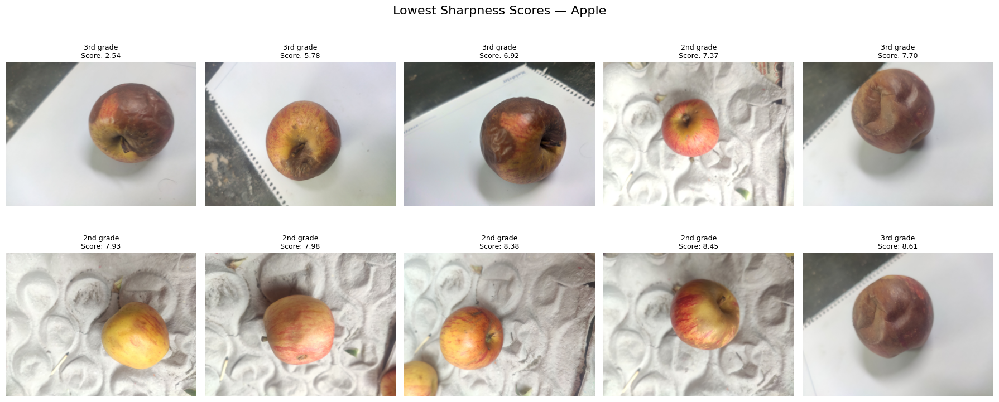

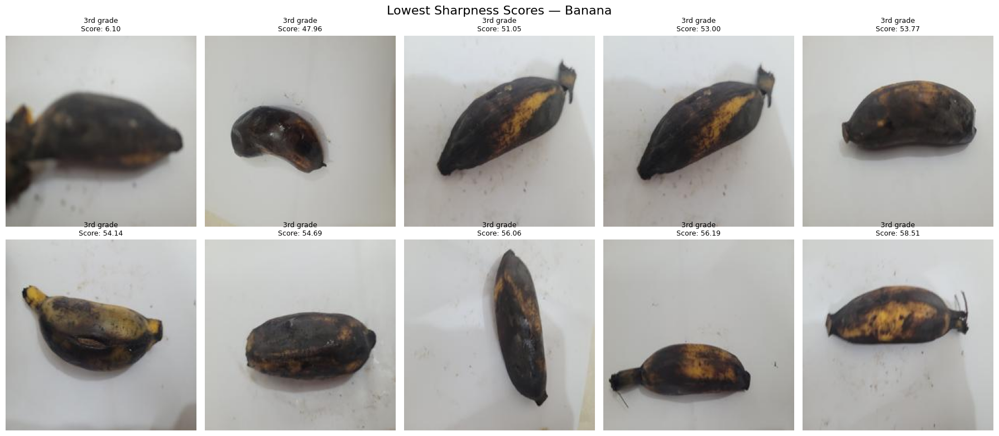

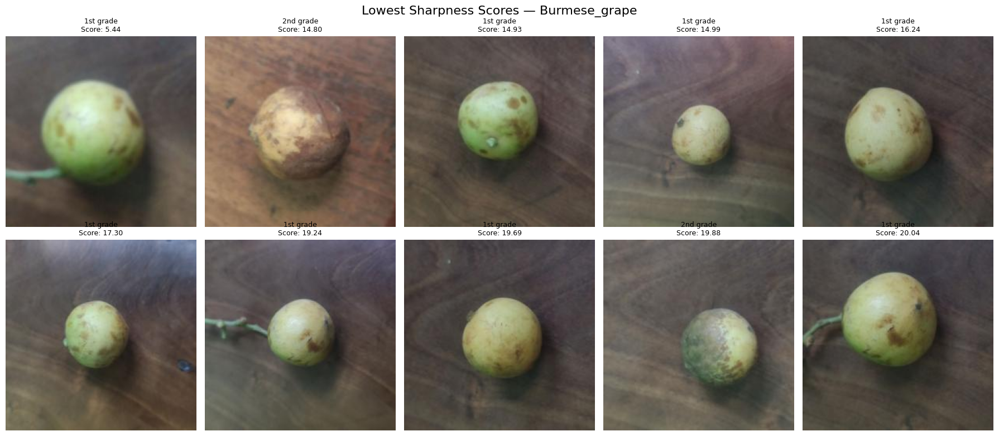

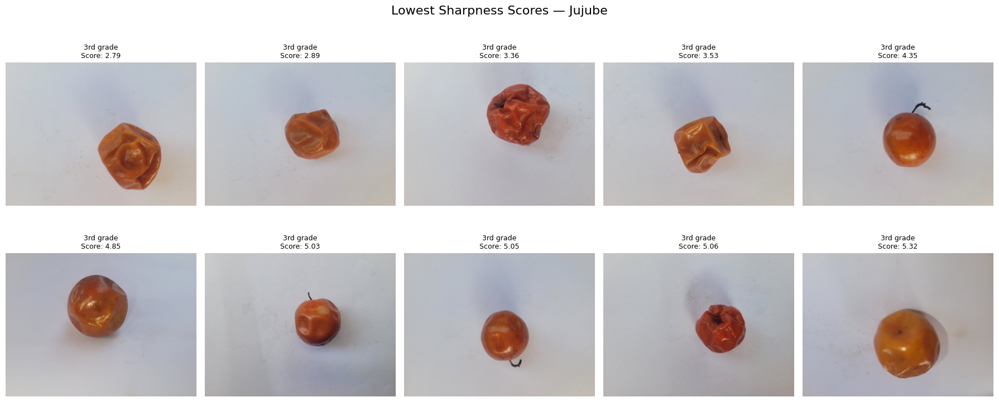

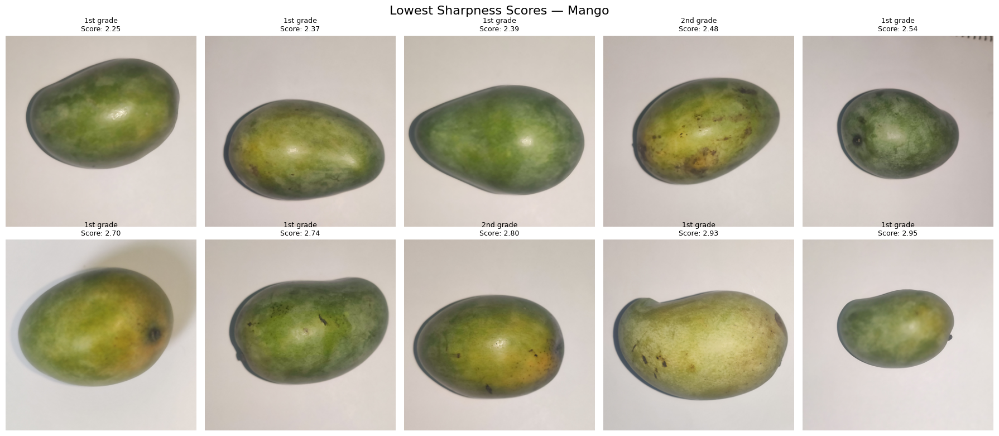

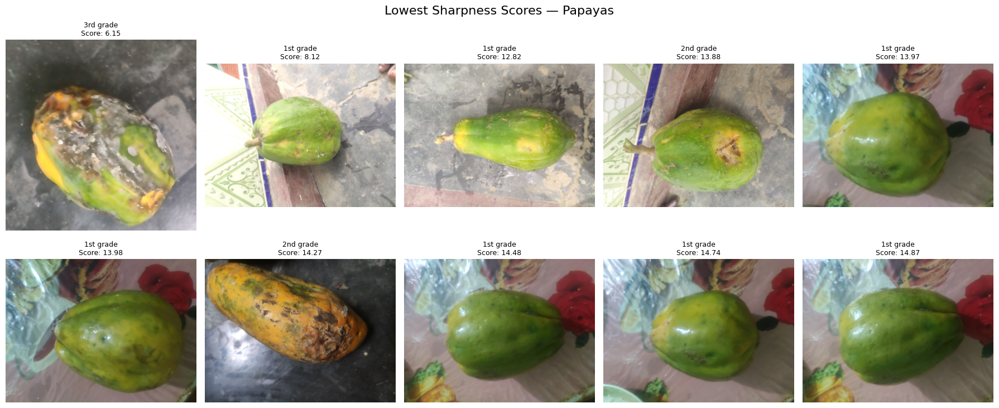

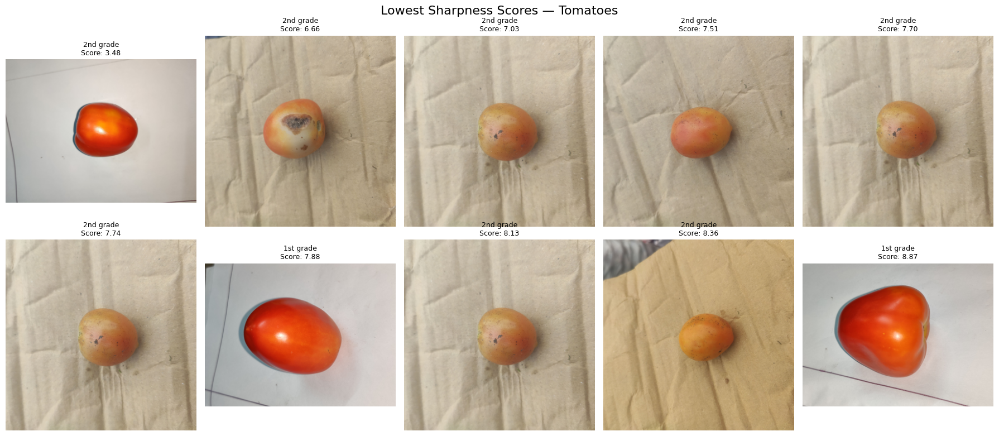

In [ ]:
from PIL import Image, ImageOps
from io import BytesIO
import matplotlib.pyplot as plt
import zipfile
import numpy as np

# All 70 images are from the Expanded dataset
with zipfile.ZipFile(bd_zip_path, "r") as archive:

    for fruit_name in sorted(lowest_blur_sample["fruit"].unique()):

        fruit_review = lowest_blur_sample[
            lowest_blur_sample["fruit"] == fruit_name
        ].reset_index(drop=True)

        fig, axes = plt.subplots(2, 5, figsize=(18, 8))
        axes = axes.flatten()

        fig.suptitle(
            f"Lowest Sharpness Scores — {fruit_name}",
            fontsize=16
        )

        for i, ax in enumerate(axes):

            ax.axis("off")

            if i >= len(fruit_review):
                continue

            row = fruit_review.iloc[i]

            try:
                image_bytes = archive.read(row["relative_path"])

                image = Image.open(
                    BytesIO(image_bytes)
                ).convert("RGB")

                # Resize for display only; original image remains unchanged
                image.thumbnail((350, 350))

                ax.imshow(image)

                ax.set_title(
                    f'{row["grade"]}\n'
                    f'Score: {row["laplacian_variance"]:.2f}',
                    fontsize=9
                )

            except Exception as e:
                ax.set_title(f"ERROR: {str(e)[:40]}")

        plt.tight_layout()
        plt.show()

In [ ]:
review_df = pd.read_csv(
    QC_DIR / "lowest_blur_review_sample_70.csv"
)

# Find the two manually confirmed blurry images
confirmed_blurry = review_df[
    (
        (review_df["fruit"] == "Banana") &
        (review_df["laplacian_variance"].round(2) == 6.10)
    ) |
    (
        (review_df["fruit"] == "Burmese_grape") &
        (review_df["laplacian_variance"].round(2) == 5.44)
    )
]

display(
    confirmed_blurry[
        ["fruit", "grade", "relative_path",
         "sha256", "laplacian_variance"]
    ]
)

,fruit,grade,relative_path,sha256,laplacian_variance
22,Burmese_grape,1st grade,Bangladeshi Fruit Grade classification/Fruit g...,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427...,5.435904
24,Banana,3rd grade,Bangladeshi Fruit Grade classification/Fruit g...,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80...,6.095318


In [ ]:
pd.set_option("display.max_colwidth", None)

print("Confirmed blurry-image records:")
display(
    confirmed_blurry[
        ["fruit", "grade", "relative_path",
         "sha256", "laplacian_variance"]
    ].to_string(index=False)
)

Confirmed blurry-image records:


'        fruit     grade                                                                                      relative_path                                                           sha256  laplacian_variance\nBurmese_grape 1st grade Bangladeshi Fruit Grade classification/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg 661a79a6627e108d46d187625e5cc0ce2d29fe886c6427d0361761b72508375c            5.435904\n       Banana 3rd grade            Bangladeshi Fruit Grade classification/Fruit grade/Banana/3rd grade/20250418_193849.jpg 85341f204e42a060f79f51b270a13dd4a7ca84c9354e80b705d7d4a5124540f3            6.095318'

In [ ]:
import pandas as pd

# Manually confirmed unusable images
exclusions = pd.DataFrame([
    {
        "sha256": "661a79a6627e108d46d187625e5cc0ce2d29fe886c6427d0361761b72508375c",
        "fruit": "Burmese_grape",
        "grade": "1st grade",
        "relative_path": "Bangladeshi Fruit Grade classification/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg",
        "laplacian_variance": 5.435904,
        "decision": "EXCLUDE",
        "reason": "Manually confirmed significantly blurry during visual QC review"
    },
    {
        "sha256": "85341f204e42a060f79f51b270a13dd4a7ca84c9354e80b705d7d4a5124540f3",
        "fruit": "Banana",
        "grade": "3rd grade",
        "relative_path": "Bangladeshi Fruit Grade classification/Fruit grade/Banana/3rd grade/20250418_193849.jpg",
        "laplacian_variance": 6.095318,
        "decision": "EXCLUDE",
        "reason": "Manually confirmed significantly blurry during visual QC review"
    }
])

exclusion_path = QC_DIR / "manual_quality_exclusions.csv"

exclusions.to_csv(exclusion_path, index=False)

# Verify saved file
check = pd.read_csv(exclusion_path)

print("Manual exclusion log saved:", exclusion_path)
print("Total exclusions recorded:", len(check))
print("Unique image hashes:", check["sha256"].nunique())

display(check)

Manual exclusion log saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/manual_quality_exclusions.csv
Total exclusions recorded: 2
Unique image hashes: 2


,sha256,fruit,grade,relative_path,laplacian_variance,decision,reason
0,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427d0361761b72508375c,Burmese_grape,1st grade,Bangladeshi Fruit Grade classification/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg,5.435904,EXCLUDE,Manually confirmed significantly blurry during visual QC review
1,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80b705d7d4a5124540f3,Banana,3rd grade,Bangladeshi Fruit Grade classification/Fruit grade/Banana/3rd grade/20250418_193849.jpg,6.095318,EXCLUDE,Manually confirmed significantly blurry during visual QC review


In [ ]:
import pandas as pd
from pathlib import Path

# Load retained dataset manifest and manual exclusion log
manifest_path = AUDIT_DIR / "retained_pending_final_qc.csv"
exclusion_path = QC_DIR / "manual_quality_exclusions.csv"

retained_df = pd.read_csv(manifest_path)
exclusions_df = pd.read_csv(exclusion_path)

# Identify excluded image content by SHA-256
excluded_hashes = set(exclusions_df["sha256"].dropna())

# Match exclusions against the retained dataset
matched_records = retained_df[
    retained_df["sha256"].isin(excluded_hashes)
].copy()

unmatched_hashes = excluded_hashes - set(retained_df["sha256"].dropna())

print("=" * 55)
print("MANUAL QC EXCLUSION RECONCILIATION")
print("=" * 55)

print(f"Exclusion decisions: {len(exclusions_df)}")
print(f"Unique excluded image hashes: {len(excluded_hashes)}")
print(f"Matching retained manifest records: {len(matched_records)}")
print(f"Unmatched exclusion hashes: {len(unmatched_hashes)}")
print(f"Original retained manifest records: {len(retained_df)}")
print(f"Original unique image hashes: {retained_df['sha256'].nunique()}")

print("\nMatched records by dataset:")
print(matched_records.groupby("dataset").size())

print("\nMatched excluded image details:")
display(
    matched_records[
        ["dataset", "fruit", "grade", "relative_path", "sha256"]
    ]
)

print("\nRemaining dataset after hash-based exclusion:")
remaining_df = retained_df[
    ~retained_df["sha256"].isin(excluded_hashes)
].copy()

print(f"Remaining manifest records: {len(remaining_df)}")
print(f"Remaining unique images: {remaining_df['sha256'].nunique()}")
print(f"Removed manifest records: {len(retained_df) - len(remaining_df)}")
print(f"Removed unique images: {len(excluded_hashes)}")

MANUAL QC EXCLUSION RECONCILIATION
Exclusion decisions: 2
Unique excluded image hashes: 2
Matching retained manifest records: 2
Unmatched exclusion hashes: 0
Original retained manifest records: 6911
Original unique image hashes: 4865

Matched records by dataset:
dataset
Expanded    2
dtype: int64

Matched excluded image details:


,dataset,fruit,grade,relative_path,sha256
4200,Expanded,Banana,3rd grade,Bangladeshi Fruit Grade classification/Fruit grade/Banana/3rd grade/20250418_193849.jpg,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80b705d7d4a5124540f3
4304,Expanded,Burmese_grape,1st grade,Bangladeshi Fruit Grade classification/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427d0361761b72508375c



Remaining dataset after hash-based exclusion:
Remaining manifest records: 6909
Remaining unique images: 4863
Removed manifest records: 2
Removed unique images: 2


In [ ]:
# Determine how much of AFruitDB is covered by the Expanded QC scan

afruitdb_df = retained_df[retained_df["dataset"] == "AFruitDB"].copy()
expanded_df = retained_df[retained_df["dataset"] == "Expanded"].copy()

expanded_hashes = set(expanded_df["sha256"])
afruitdb_hashes = set(afruitdb_df["sha256"])

# AFruitDB images whose exact contents also exist in Expanded
shared_hashes = afruitdb_hashes & expanded_hashes

# AFruitDB unique images not represented in Expanded
afruitdb_only_hashes = afruitdb_hashes - expanded_hashes

print("AFruitDB QC coverage analysis")
print("-" * 45)
print("AFruitDB manifest records:", len(afruitdb_df))
print("AFruitDB unique image hashes:", len(afruitdb_hashes))
print("Shared exact image hashes:", len(shared_hashes))
print("AFruitDB-only unique images:", len(afruitdb_only_hashes))
print("Expanded unique hashes already screened:", len(expanded_hashes))

print(
    "\nAFruitDB images already covered by Expanded QC:",
    f"{len(shared_hashes) / len(afruitdb_hashes) * 100:.2f}%"
)

print(
    "AFruitDB images still needing QC:",
    len(afruitdb_only_hashes)
)

AFruitDB QC coverage analysis
---------------------------------------------
AFruitDB manifest records: 3161
AFruitDB unique image hashes: 3161
Shared exact image hashes: 2046
AFruitDB-only unique images: 1115
Expanded unique hashes already screened: 3750

AFruitDB images already covered by Expanded QC: 64.73%
AFruitDB images still needing QC: 1115


In [ ]:
import shutil

print("Colab local storage:")
print("Free space (GB):", round(shutil.disk_usage("/content").free / (1024**3), 2))

print("\nGoogle Drive research folder:")
print(ROOT)

Colab local storage:
Free space (GB): 102.12

Google Drive research folder:
/content/drive/MyDrive/Fruit_Freshness_Research


In [ ]:
from pathlib import Path
import zipfile

AFRUITDB_OUTER = ROOT / "datasets" / "original" / "AFruitDB_original.zip"

print("Outer archive exists:", AFRUITDB_OUTER.exists())

with zipfile.ZipFile(AFRUITDB_OUTER, "r") as outer_zip:
    nested_zip_members = [
        info for info in outer_zip.infolist()
        if info.filename.lower().endswith(".zip")
    ]

    print("\nNested ZIP files found:")
    for info in nested_zip_members:
        print("Name:", info.filename)
        print("Compressed size (GB):", round(info.compress_size / (1024**3), 2))
        print("Uncompressed size (GB):", round(info.file_size / (1024**3), 2))

Outer archive exists: True

Nested ZIP files found:
Name: A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip
Compressed size (GB): 2.93
Uncompressed size (GB): 2.93


In [ ]:
import zipfile
import shutil
from pathlib import Path

TEMP_DIR = Path("/content/fruit_qc_temp")
TEMP_DIR.mkdir(parents=True, exist_ok=True)

NESTED_ZIP_LOCAL = TEMP_DIR / "AFruitDB_inner.zip"

with zipfile.ZipFile(AFRUITDB_OUTER, "r") as outer_zip:
    nested_name = nested_zip_members[0].filename

    with outer_zip.open(nested_name) as source:
        with open(NESTED_ZIP_LOCAL, "wb") as destination:
            shutil.copyfileobj(source, destination, length=1024*1024)

print("Copy completed.")
print("Local archive exists:", NESTED_ZIP_LOCAL.exists())
print("Size (GB):", round(NESTED_ZIP_LOCAL.stat().st_size / (1024**3), 2))
print("Location:", NESTED_ZIP_LOCAL)

Copy completed.
Local archive exists: True
Size (GB): 2.93
Location: /content/fruit_qc_temp/AFruitDB_inner.zip


In [ ]:
import zipfile

with zipfile.ZipFile(NESTED_ZIP_LOCAL, "r") as af_zip:
    members = af_zip.namelist()

    image_members = [
        name for name in members
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Nested archive readable:", True)
    print("Total entries:", len(members))
    print("Image files:", len(image_members))
    print("\nFirst 10 image paths:")
    for name in image_members[:10]:
        print(name)

Nested archive readable: True
Total entries: 3193
Image files: 3167

First 10 image paths:
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172415.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172429.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172432.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172439.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172444.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172456.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172500.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172505.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172509.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172513.jpg


In [ ]:
# Identify AFruitDB images whose image hashes were NOT screened in Expanded QC

# Confirm the required columns exist
print("Manifest columns:", retained_df.columns.tolist())
print("QC report columns:", qc_report.columns.tolist())

# AFruitDB records
afruitdb_df = retained_df[retained_df["dataset"] == "AFruitDB"].copy()

# Exact image hashes already covered by Expanded QC
expanded_qc_hashes = set(qc_report["sha256"].dropna().astype(str))

# AFruitDB image hashes not already covered
afruitdb_only_qc = afruitdb_df[
    ~afruitdb_df["sha256"].astype(str).isin(expanded_qc_hashes)
].copy()

# Remove repeated exact hashes within this subset, if any
afruitdb_only_qc = afruitdb_only_qc.drop_duplicates(subset="sha256")

print("\n--- QC Coverage ---")
print("AFruitDB manifest records:", len(afruitdb_df))
print("AFruitDB unique hashes:", afruitdb_df["sha256"].nunique())
print("Already covered by Expanded QC:",
      afruitdb_df["sha256"].isin(expanded_qc_hashes).sum())
print("AFruitDB-only images requiring QC:", len(afruitdb_only_qc))

print("\nImages by fruit:")
print(afruitdb_only_qc["fruit"].value_counts().sort_index())

# Save the QC target list
target_path = QC_DIR / "afruitdb_only_qc_targets.csv"
afruitdb_only_qc.to_csv(target_path, index=False)

print("\nSaved target list:", target_path)

Manifest columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine']
QC report columns: ['dataset', 'relative_path', 'sha256', 'fruit', 'grade', 'file_size_manifest', 'width', 'height', 'brightness_mean', 'brightness_std', 'laplacian_variance', 'decode_ok', 'error', 'flag_small', 'flag_blur', 'flag_dark', 'flag_bright', 'any_quality_flag']

--- QC Coverage ---
AFruitDB manifest records: 3161
AFruitDB unique hashes: 3161
Already covered by Expanded QC: 2046
AFruitDB-only images requiring QC: 1115

Images by fruit:
fruit
Banana           484
Burmese_grape    630
Papayas            1
Name: count, dtype: int64

Saved target list: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/afruitdb_only_qc_targets.csv


In [ ]:
import cv2
import numpy as np
import pandas as pd
import zipfile
from tqdm.auto import tqdm

# Load the AFruitDB-only QC target list
target_df = pd.read_csv(QC_DIR / "afruitdb_only_qc_targets.csv")

# Open the nested AFruitDB archive
qc_records = []

with zipfile.ZipFile(NESTED_ZIP_LOCAL, "r") as af_zip:

    archive_names = set(af_zip.namelist())

    missing_paths = [
        p for p in target_df["relative_path"]
        if p not in archive_names
    ]

    print("Target images:", len(target_df))
    print("Missing archive paths:", len(missing_paths))

    if missing_paths:
        print("\nFirst missing paths:")
        for p in missing_paths[:10]:
            print(p)

    for _, row in tqdm(target_df.iterrows(), total=len(target_df)):

        record = row.to_dict()

        try:
            # Read image bytes directly from the ZIP
            image_bytes = af_zip.read(row["relative_path"])

            # Decode image
            image_array = np.frombuffer(image_bytes, dtype=np.uint8)
            img = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

            if img is None:
                raise ValueError("OpenCV could not decode image")

            height, width = img.shape[:2]

            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

            brightness_mean = float(np.mean(gray))
            brightness_std = float(np.std(gray))
            laplacian_variance = float(
                cv2.Laplacian(gray, cv2.CV_64F).var()
            )

            record.update({
                "width": width,
                "height": height,
                "brightness_mean": brightness_mean,
                "brightness_std": brightness_std,
                "laplacian_variance": laplacian_variance,
                "decode_ok": True,
                "error": ""
            })

        except Exception as e:
            record.update({
                "width": np.nan,
                "height": np.nan,
                "brightness_mean": np.nan,
                "brightness_std": np.nan,
                "laplacian_variance": np.nan,
                "decode_ok": False,
                "error": str(e)
            })

        qc_records.append(record)

# Create QC results DataFrame
afruitdb_qc_results = pd.DataFrame(qc_records)

# Quality flags (same preliminary thresholds as the Expanded scan)
afruitdb_qc_results["flag_small"] = (
    (afruitdb_qc_results["width"] < 128) |
    (afruitdb_qc_results["height"] < 128)
)

afruitdb_qc_results["flag_blur"] = (
    afruitdb_qc_results["laplacian_variance"] < 100
)

afruitdb_qc_results["flag_dark"] = (
    afruitdb_qc_results["brightness_mean"] < 30
)

afruitdb_qc_results["flag_bright"] = (
    afruitdb_qc_results["brightness_mean"] > 225
)

afruitdb_qc_results["any_quality_flag"] = (
    afruitdb_qc_results[
        ["flag_small", "flag_blur", "flag_dark", "flag_bright"]
    ].any(axis=1)
)

# Save results
AFRUITDB_QC_PATH = QC_DIR / "afruitdb_only_image_quality_screening.csv"

afruitdb_qc_results.to_csv(AFRUITDB_QC_PATH, index=False)

print("\n--- AFruitDB-only QC Scan Summary ---")
print("Images scanned:", len(afruitdb_qc_results))
print("Successfully decoded:",
      afruitdb_qc_results["decode_ok"].sum())
print("Decode failures:",
      (~afruitdb_qc_results["decode_ok"]).sum())
print("Small image flags:",
      afruitdb_qc_results["flag_small"].sum())
print("Blur flags:",
      afruitdb_qc_results["flag_blur"].sum())
print("Dark flags:",
      afruitdb_qc_results["flag_dark"].sum())
print("Bright flags:",
      afruitdb_qc_results["flag_bright"].sum())
print("Any quality flag:",
      afruitdb_qc_results["any_quality_flag"].sum())

print("\nQC results saved to:")
print(AFRUITDB_QC_PATH)

Target images: 1115
Missing archive paths: 0


  0%|          | 0/1115 [00:00<?, ?it/s]


--- AFruitDB-only QC Scan Summary ---
Images scanned: 1115
Successfully decoded: 1115
Decode failures: 0
Small image flags: 0
Blur flags: 1015
Dark flags: 0
Bright flags: 0
Any quality flag: 1015

QC results saved to:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/afruitdb_only_image_quality_screening.csv


In [ ]:
# Summary of AFruitDB-only sharpness scores by fruit

blur_summary = (
    afruitdb_qc_results
    .groupby("fruit")["laplacian_variance"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .round(2)
)

print("Laplacian variance summary by fruit:")
display(blur_summary)

print("\nPercentage below preliminary blur threshold (100):")

blur_percent = (
    afruitdb_qc_results
    .groupby("fruit")
    .agg(
        total=("laplacian_variance", "count"),
        below_100=("flag_blur", "sum")
    )
)

blur_percent["percent_below_100"] = (
    blur_percent["below_100"] / blur_percent["total"] * 100
).round(2)

display(blur_percent)

# Additional score quantiles
print("\nSharpness score quantiles by fruit:")
display(
    afruitdb_qc_results
    .groupby("fruit")["laplacian_variance"]
    .quantile([0.10, 0.25, 0.50, 0.75, 0.90])
    .unstack()
    .round(2)
)

Laplacian variance summary by fruit:


,count,mean,median,min,max
fruit,,,,,
Banana,484,40.16,27.26,11.49,196.48
Burmese_grape,630,34.53,22.32,3.19,249.17
Papayas,1,53.14,53.14,53.14,53.14



Percentage below preliminary blur threshold (100):


,total,below_100,percent_below_100
fruit,,,
Banana,484,439,90.70
Burmese_grape,630,575,91.27
Papayas,1,1,100.00



Sharpness score quantiles by fruit:


,0.10,0.25,0.50,0.75,0.90
fruit,,,,,
Banana,17.33,20.98,27.26,36.13,98.18
Burmese_grape,9.81,15.93,22.32,34.47,81.87
Papayas,53.14,53.14,53.14,53.14,53.14


In [ ]:
import pandas as pd

# Select lowest-sharpness sample per fruit
review_samples = []

for fruit, group in afruitdb_qc_results.groupby("fruit"):

    n = min(10, len(group))

    sample = group.nsmallest(
        n,
        "laplacian_variance"
    ).copy()

    review_samples.append(sample)

lowest_blur_review_afruitdb = pd.concat(
    review_samples,
    ignore_index=True
)

# Save sample for reproducibility
review_sample_path = (
    QC_DIR / "afruitdb_lowest_blur_review_sample.csv"
)

lowest_blur_review_afruitdb.to_csv(
    review_sample_path,
    index=False
)

print("Selected images:", len(lowest_blur_review_afruitdb))
print("\nSamples per fruit:")
print(
    lowest_blur_review_afruitdb["fruit"]
    .value_counts()
    .sort_index()
)

print("\nSharpness score ranges:")
display(
    lowest_blur_review_afruitdb
    .groupby("fruit")["laplacian_variance"]
    .agg(["min", "median", "max"])
    .round(2)
)

print("\nSaved review sample:")
print(review_sample_path)

Selected images: 21

Samples per fruit:
fruit
Banana           10
Burmese_grape    10
Papayas           1
Name: count, dtype: int64

Sharpness score ranges:


,min,median,max
fruit,,,
Banana,11.49,12.96,13.87
Burmese_grape,3.19,4.64,5.88
Papayas,53.14,53.14,53.14



Saved review sample:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/afruitdb_lowest_blur_review_sample.csv


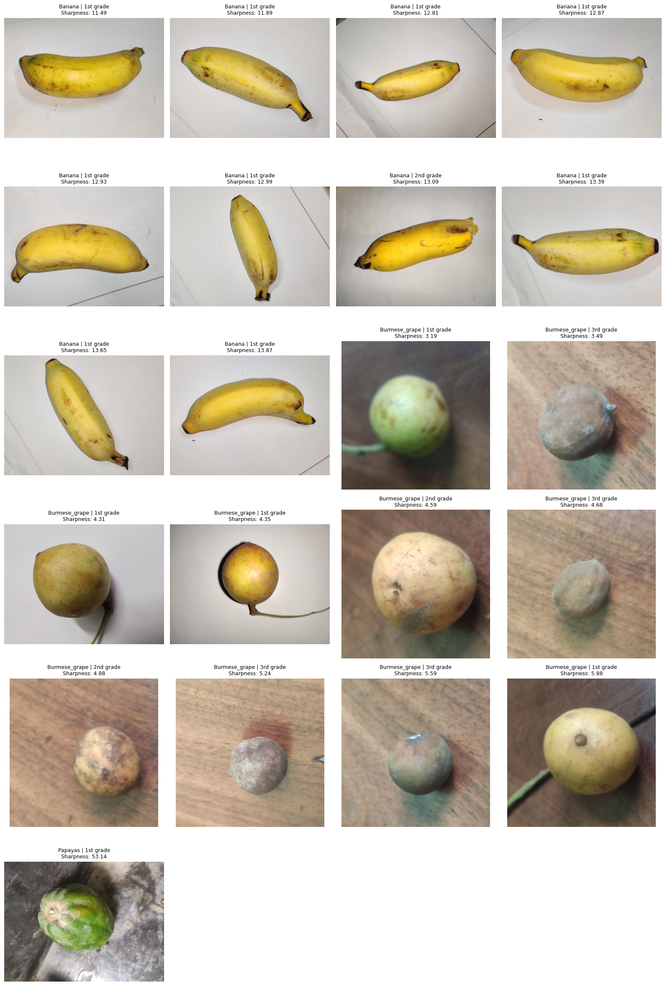

Contact sheet saved to: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/afruitdb_lowest_blur_contact_sheet.png


In [ ]:
import zipfile
import io
import math
import matplotlib.pyplot as plt
from PIL import Image

sample_df = lowest_blur_review_afruitdb.reset_index(drop=True)

cols = 4
rows = math.ceil(len(sample_df) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 4))
axes = axes.flatten()

with zipfile.ZipFile(NESTED_ZIP_LOCAL, "r") as af_zip:

    for i, (_, row) in enumerate(sample_df.iterrows()):
        ax = axes[i]

        try:
            image_bytes = af_zip.read(row["relative_path"])
            img = Image.open(io.BytesIO(image_bytes)).convert("RGB")

            ax.imshow(img)
            ax.set_title(
                f'{row["fruit"]} | {row["grade"]}\n'
                f'Sharpness: {row["laplacian_variance"]:.2f}',
                fontsize=9
            )

        except Exception as e:
            ax.text(0.5, 0.5, f"Image error\n{e}",
                    ha="center", va="center")

        ax.axis("off")

# Hide unused panels
for j in range(len(sample_df), len(axes)):
    axes[j].axis("off")

plt.tight_layout()

contact_sheet_path = QC_DIR / "afruitdb_lowest_blur_contact_sheet.png"
plt.savefig(contact_sheet_path, dpi=200, bbox_inches="tight")
plt.show()

print("Contact sheet saved to:", contact_sheet_path)

In [ ]:
# Print the 10 lowest-sharpness AFruitDB-only images per fruit
for fruit in ["Banana", "Burmese_grape", "Papayas"]:

    print(f"\n{'='*70}")
    print(f"FRUIT: {fruit}")
    print(f"{'='*70}")

    display(
        lowest_blur_review_afruitdb[
            lowest_blur_review_afruitdb["fruit"] == fruit
        ][
            ["filename", "grade", "laplacian_variance", "relative_path"]
        ].sort_values("laplacian_variance")
    )


FRUIT: Banana


,filename,grade,laplacian_variance,relative_path
0,IMG_20230925_001331.jpg,1st grade,11.488439,Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230925_001331.jpg
1,IMG_20230924_235011.jpg,1st grade,11.889162,Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230924_235011.jpg
2,IMG_20230924_235044.jpg,1st grade,12.807965,Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230924_235044.jpg
3,IMG_20230924_235234.jpg,1st grade,12.868971,Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230924_235234.jpg
4,IMG_20230925_000335.jpg,1st grade,12.934322,Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230925_000335.jpg
5,IMG_20230924_234942.jpg,1st grade,12.986737,Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230924_234942.jpg
6,IMG_20230727_170257.jpg,2nd grade,13.086415,Fruits Grade/Fruit grade/Banana/2nd grade/IMG_20230727_170257.jpg
7,IMG_20230924_235017.jpg,1st grade,13.388806,Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230924_235017.jpg
8,IMG_20230924_234955.jpg,1st grade,13.648760,Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230924_234955.jpg
9,IMG_20230924_235205.jpg,1st grade,13.865146,Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230924_235205.jpg



FRUIT: Burmese_grape


,filename,grade,laplacian_variance,relative_path
10,IMG_20230707_173729.jpg,1st grade,3.189578,Fruits Grade/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg
11,IMG_20230711_145843.jpg,3rd grade,3.486087,Fruits Grade/Fruit grade/Burmese_grape/3rd grade/IMG_20230711_145843.jpg
12,IMG_20230713_174805.jpg,1st grade,4.311003,Fruits Grade/Fruit grade/Burmese_grape/1st grade/IMG_20230713_174805.jpg
13,IMG_20230713_174926.jpg,1st grade,4.353165,Fruits Grade/Fruit grade/Burmese_grape/1st grade/IMG_20230713_174926.jpg
14,IMG_20230708_152059.jpg,2nd grade,4.589490,Fruits Grade/Fruit grade/Burmese_grape/2nd grade/IMG_20230708_152059.jpg
15,IMG_20230711_134910.jpg,3rd grade,4.682005,Fruits Grade/Fruit grade/Burmese_grape/3rd grade/IMG_20230711_134910.jpg
16,IMG_20230711_140926.jpg,2nd grade,4.879233,Fruits Grade/Fruit grade/Burmese_grape/2nd grade/IMG_20230711_140926.jpg
17,IMG_20230711_135938.jpg,3rd grade,5.240004,Fruits Grade/Fruit grade/Burmese_grape/3rd grade/IMG_20230711_135938.jpg
18,IMG_20230711_145934.jpg,3rd grade,5.588163,Fruits Grade/Fruit grade/Burmese_grape/3rd grade/IMG_20230711_145934.jpg
19,IMG_20230708_152759.jpg,1st grade,5.880327,Fruits Grade/Fruit grade/Burmese_grape/1st grade/IMG_20230708_152759.jpg



FRUIT: Papayas


,filename,grade,laplacian_variance,relative_path
20,IMG_20230429_142542.jpg,1st grade,53.139068,Fruits Grade/Fruit grade/Papayas/1st grade/IMG_20230429_142542.jpg


In [ ]:
# Proposed AFruitDB blur exclusion
candidate_path = (
    "Fruits Grade/Fruit grade/Burmese_grape/"
    "1st grade/IMG_20230707_173729.jpg"
)

candidate = afruitdb_qc_results[
    afruitdb_qc_results["relative_path"] == candidate_path
].copy()

print("Candidate records found:", len(candidate))

display(
    candidate[
        ["dataset", "filename", "fruit", "grade",
         "sha256", "laplacian_variance", "relative_path"]
    ]
)

# Review the existing exclusion log
exclusion_log_path = QC_DIR / "manual_quality_exclusions.csv"

exclusions_df = pd.read_csv(exclusion_log_path)

print("\nExisting exclusion log:")
display(exclusions_df)

print("\nExisting exclusion count:", len(exclusions_df))

Candidate records found: 1


,dataset,filename,fruit,grade,sha256,laplacian_variance,relative_path
534,AFruitDB,IMG_20230707_173729.jpg,Burmese_grape,1st grade,a87f4efbb384a26c484a205cf07017fdd86f618509685f1158e6623db75489c1,3.189578,Fruits Grade/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg



Existing exclusion log:


,sha256,fruit,grade,relative_path,laplacian_variance,decision,reason
0,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427d0361761b72508375c,Burmese_grape,1st grade,Bangladeshi Fruit Grade classification/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg,5.435904,EXCLUDE,Manually confirmed significantly blurry during visual QC review
1,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80b705d7d4a5124540f3,Banana,3rd grade,Bangladeshi Fruit Grade classification/Fruit grade/Banana/3rd grade/20250418_193849.jpg,6.095318,EXCLUDE,Manually confirmed significantly blurry during visual QC review



Existing exclusion count: 2


In [ ]:
# Add the visually confirmed AFruitDB blur exclusion
# Safe to rerun: duplicate SHA-256 entries will not be added.

candidate_hash = "a87f4efbb384a26c484a205cf07017fdd86f618509685f1158e6623db75489c1"

candidate_record = candidate.iloc[0]

new_exclusion = pd.DataFrame([{
    "sha256": candidate_hash,
    "fruit": candidate_record["fruit"],
    "grade": candidate_record["grade"],
    "relative_path": candidate_record["relative_path"],
    "laplacian_variance": candidate_record["laplacian_variance"],
    "decision": "EXCLUDE",
    "reason": "Manually confirmed significantly blurry during visual QC review"
}])

if candidate_hash not in exclusions_df["sha256"].values:

    exclusions_df = pd.concat(
        [exclusions_df, new_exclusion],
        ignore_index=True
    )

    exclusions_df.to_csv(exclusion_log_path, index=False)
    print("New exclusion added.")

else:
    print("This image is already in the exclusion log. No duplicate added.")

# Verify saved log
exclusions_df = pd.read_csv(exclusion_log_path)

print("\n--- Updated Exclusion Log ---")
print("Total exclusions:", len(exclusions_df))
print("Unique excluded hashes:", exclusions_df["sha256"].nunique())
print("Decision counts:")
print(exclusions_df["decision"].value_counts())

display(exclusions_df)

New exclusion added.

--- Updated Exclusion Log ---
Total exclusions: 3
Unique excluded hashes: 3
Decision counts:
decision
EXCLUDE    3
Name: count, dtype: int64


,sha256,fruit,grade,relative_path,laplacian_variance,decision,reason
0,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427d0361761b72508375c,Burmese_grape,1st grade,Bangladeshi Fruit Grade classification/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg,5.435904,EXCLUDE,Manually confirmed significantly blurry during visual QC review
1,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80b705d7d4a5124540f3,Banana,3rd grade,Bangladeshi Fruit Grade classification/Fruit grade/Banana/3rd grade/20250418_193849.jpg,6.095318,EXCLUDE,Manually confirmed significantly blurry during visual QC review
2,a87f4efbb384a26c484a205cf07017fdd86f618509685f1158e6623db75489c1,Burmese_grape,1st grade,Fruits Grade/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg,3.189578,EXCLUDE,Manually confirmed significantly blurry during visual QC review


In [ ]:
import pandas as pd

# 1. Load both QC screening results
expanded_qc = pd.read_csv(
    QC_DIR / "expanded_image_quality_screening.csv"
)

afruitdb_only_qc = pd.read_csv(
    QC_DIR / "afruitdb_only_image_quality_screening.csv"
)

# 2. Combine QC records
combined_qc = pd.concat(
    [expanded_qc, afruitdb_only_qc],
    ignore_index=True,
    sort=False
)

# 3. Normalize SHA-256 values for reliable matching
combined_qc["sha256"] = combined_qc["sha256"].astype(str).str.lower().str.strip()

# 4. Load the manual exclusion log
exclusions_df = pd.read_csv(
    QC_DIR / "manual_quality_exclusions.csv"
)

exclusions_df["sha256"] = (
    exclusions_df["sha256"].astype(str).str.lower().str.strip()
)

excluded_hashes = set(exclusions_df["sha256"])

# 5. Mark exclusion status in the combined QC table
combined_qc["manual_exclusion"] = (
    combined_qc["sha256"].isin(excluded_hashes)
)

# 6. Save consolidated QC report
combined_qc_path = QC_DIR / "combined_image_quality_screening.csv"

combined_qc.to_csv(combined_qc_path, index=False)

# 7. Verification summary
print("===== CONSOLIDATED QC SUMMARY =====")
print("Expanded QC records:", len(expanded_qc))
print("AFruitDB-only QC records:", len(afruitdb_only_qc))
print("Combined QC records:", len(combined_qc))
print("Combined unique image hashes:", combined_qc["sha256"].nunique())

print("\n===== DECODE CHECK =====")
print("Decode successes:", combined_qc["decode_ok"].sum())
print("Decode failures:", (~combined_qc["decode_ok"]).sum())

print("\n===== EXCLUSION RECONCILIATION =====")
print("Exclusion log records:", len(exclusions_df))
print("Unique exclusion hashes:", len(excluded_hashes))
print("Excluded hashes matched in QC:",
      combined_qc["sha256"].isin(excluded_hashes).sum())
print("Excluded hashes not found in QC:",
      len(excluded_hashes - set(combined_qc["sha256"])))

print("\n===== QC BY SOURCE =====")
display(
    combined_qc.groupby("dataset").agg(
        records=("sha256", "count"),
        unique_hashes=("sha256", "nunique"),
        decode_failures=("decode_ok", lambda x: (~x).sum()),
        blur_flags=("flag_blur", "sum"),
        any_quality_flags=("any_quality_flag", "sum"),
        manual_exclusions=("manual_exclusion", "sum")
    )
)

print("\nCombined QC file saved:")
print(combined_qc_path)

===== CONSOLIDATED QC SUMMARY =====
Expanded QC records: 3750
AFruitDB-only QC records: 1115
Combined QC records: 4865
Combined unique image hashes: 4865

===== DECODE CHECK =====
Decode successes: 4865
Decode failures: 0

===== EXCLUSION RECONCILIATION =====
Exclusion log records: 3
Unique exclusion hashes: 3
Excluded hashes matched in QC: 3
Excluded hashes not found in QC: 0

===== QC BY SOURCE =====


,records,unique_hashes,decode_failures,blur_flags,any_quality_flags,manual_exclusions
dataset,,,,,,
AFruitDB,1115,1115,0,1015,1015,1
Expanded,3750,3750,0,2917,2917,2



Combined QC file saved:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/combined_image_quality_screening.csv


In [ ]:
# Inspect existing reconciliation files before creating the final cleaned manifest

reconciled_path = AUDIT_DIR / "reconciled_image_manifest.csv"
split_path = AUDIT_DIR / "final_split_manifest.csv"

reconciled_manifest = pd.read_csv(reconciled_path)
old_split_manifest = pd.read_csv(split_path)

print("=== Reconciled master manifest ===")
print("Rows:", len(reconciled_manifest))
print("Columns:")
print(reconciled_manifest.columns.tolist())

print("\n=== Existing split manifest ===")
print("Rows:", len(old_split_manifest))
print("Columns:")
print(old_split_manifest.columns.tolist())

print("\n=== Existing split counts ===")
if "split" in old_split_manifest.columns:
    print(old_split_manifest["split"].value_counts())

print("\n=== Exclusion hashes ===")
print("Unique excluded hashes:", exclusions_df["sha256"].nunique())

print("\n=== Current manifest hash counts ===")
print("Rows:", len(reconciled_manifest))
print("Unique SHA-256:", reconciled_manifest["sha256"].nunique())

print("\n=== Exclusion matches in master manifest ===")
print(
    reconciled_manifest["sha256"]
    .isin(excluded_hashes)
    .sum()
)

=== Reconciled master manifest ===
Rows: 6923
Columns:
['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine']

=== Existing split manifest ===
Rows: 6911
Columns:
['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine', 'split_group', 'split']

=== Existing split counts ===
split
train         4835
test          1043
validation    1033
Name: count, dtype: int64

=== Exclusion hashes ===
Unique excluded hashes: 3

=== Current manifest hash counts ===
Rows: 6923
Unique SHA-256: 4868

=== Exclusion matches in master manifest ===
3


In [ ]:
# Inspect existing quarantine and dataset status fields
print("=== Dataset status counts ===")
display(
    reconciled_manifest["dataset_status"]
    .value_counts(dropna=False)
)

print("\n=== Quarantine reason counts ===")
display(
    reconciled_manifest["quarantine_reason"]
    .value_counts(dropna=False)
)

print("\n=== Group quarantine flag counts ===")
display(
    reconciled_manifest["group_requires_quarantine"]
    .value_counts(dropna=False)
)

print("\n=== Previously retained manifest comparison ===")
print("Reconciled rows:", len(reconciled_manifest))
print("Previously retained rows:", len(retained_df))

print("\n=== Rows excluded from previous retained manifest by hash ===")
print(
    "Unique hashes in reconciled but not retained:",
    len(
        set(reconciled_manifest["sha256"]) -
        set(retained_df["sha256"])
    )
)

print("\n=== Existing label-conflict quarantine file ===")
quarantine_path = AUDIT_DIR / "quarantine_label_conflicts.csv"

if quarantine_path.exists():
    quarantine_df = pd.read_csv(quarantine_path)
    print("Quarantine file rows:", len(quarantine_df))
    print("Columns:", quarantine_df.columns.tolist())
    display(quarantine_df.head())
else:
    print("Quarantine file not found:", quarantine_path)

=== Dataset status counts ===


,count
dataset_status,
RETAIN_PENDING_FINAL_QC,6911
QUARANTINE_LABEL_CONFLICT,12



=== Quarantine reason counts ===


,count
quarantine_reason,
NaN,6911
Exact duplicate image assigned conflicting 1st and 2nd grade labels,12



=== Group quarantine flag counts ===


,count
group_requires_quarantine,
True,6721
False,202



=== Previously retained manifest comparison ===
Reconciled rows: 6923
Previously retained rows: 6911

=== Rows excluded from previous retained manifest by hash ===
Unique hashes in reconciled but not retained: 3

=== Existing label-conflict quarantine file ===
Quarantine file rows: 12
Columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine']


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine
0,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_20230819_192101.jpg,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18199c476e77e87300c6,SINGLETON,1,Exact duplicate image assigned conflicting 1st and 2nd grade labels,QUARANTINE_LABEL_CONFLICT,True
1,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_20230819_192104.jpg,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878f23bfedc4b5e809a24,SINGLETON,1,Exact duplicate image assigned conflicting 1st and 2nd grade labels,QUARANTINE_LABEL_CONFLICT,True
2,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_20230819_192107.jpg,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5ad3916a71e39ef562ee,SINGLETON,1,Exact duplicate image assigned conflicting 1st and 2nd grade labels,QUARANTINE_LABEL_CONFLICT,True
3,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_20230819_192101.jpg,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18199c476e77e87300c6,SINGLETON,1,Exact duplicate image assigned conflicting 1st and 2nd grade labels,QUARANTINE_LABEL_CONFLICT,True
4,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_20230819_192104.jpg,Mango,2nd grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878f23bfedc4b5e809a24,SINGLETON,1,Exact duplicate image assigned conflicting 1st and 2nd grade labels,QUARANTINE_LABEL_CONFLICT,True


In [ ]:
# Verify that previous retained records exclude exactly the quarantined hashes

quarantine_hashes = set(quarantine_df["sha256"])
master_hashes = set(reconciled_manifest["sha256"])
retained_hashes = set(retained_df["sha256"])

print("=== Hash reconciliation ===")
print("Quarantine unique hashes:", len(quarantine_hashes))
print("Master hashes missing from retained:", len(master_hashes - retained_hashes))

print("\n=== Check whether missing hashes equal quarantine hashes ===")
missing_from_retained = master_hashes - retained_hashes

print("Missing hashes:", missing_from_retained)
print("Quarantine hashes:", quarantine_hashes)

print("\nExact match:", missing_from_retained == quarantine_hashes)

print("\n=== Quarantine row verification ===")
print("Master quarantine rows:",
      (reconciled_manifest["dataset_status"] == "QUARANTINE_LABEL_CONFLICT").sum())

print("Retained manifest rows:", len(retained_df))
print("Retained manifest unique hashes:", retained_df["sha256"].nunique())

print("\n=== Dataset status in retained manifest ===")
if "dataset_status" in retained_df.columns:
    display(retained_df["dataset_status"].value_counts(dropna=False))
else:
    print("No dataset_status column — retained manifest is already filtered.")

=== Hash reconciliation ===
Quarantine unique hashes: 3
Master hashes missing from retained: 3

=== Check whether missing hashes equal quarantine hashes ===
Missing hashes: {'c8f588220a005f12bc213975c70d8318cd02b8a95a4a18199c476e77e87300c6', '8523098a18c6f31158d7029091cc4db33d9ffd324aca5ad3916a71e39ef562ee', '584f6114919733e6b4ef13d2b4c1caf569ade6e442a878f23bfedc4b5e809a24'}
Quarantine hashes: {'c8f588220a005f12bc213975c70d8318cd02b8a95a4a18199c476e77e87300c6', '8523098a18c6f31158d7029091cc4db33d9ffd324aca5ad3916a71e39ef562ee', '584f6114919733e6b4ef13d2b4c1caf569ade6e442a878f23bfedc4b5e809a24'}

Exact match: True

=== Quarantine row verification ===
Master quarantine rows: 12
Retained manifest rows: 6911
Retained manifest unique hashes: 4865

=== Dataset status in retained manifest ===


,count
dataset_status,
RETAIN_PENDING_FINAL_QC,6911


In [ ]:
# Verify manually confirmed QC exclusion hashes against retained dataset

print("=== Manual QC exclusion verification ===")
print("Exclusion hashes:", len(excluded_hashes))
print("Retained manifest rows:", len(retained_df))
print("Retained unique hashes:", retained_df["sha256"].nunique())

# Count how many retained records each exclusion hash affects
exclusion_matches = retained_df[
    retained_df["sha256"].isin(excluded_hashes)
].copy()

print("\nMatched records:", len(exclusion_matches))
print("Matched unique hashes:", exclusion_matches["sha256"].nunique())

print("\n=== Records selected for exclusion ===")
display(
    exclusion_matches[
        ["dataset", "filename", "fruit", "grade", "sha256"]
    ].sort_values(["fruit", "grade", "dataset"])
)

print("\n=== Match count per exclusion hash ===")
display(
    exclusion_matches.groupby("sha256").agg(
        matched_records=("sha256", "size"),
        datasets=("dataset", lambda x: ", ".join(sorted(x.unique()))),
        fruits=("fruit", lambda x: ", ".join(sorted(x.unique()))),
        grades=("grade", lambda x: ", ".join(sorted(x.unique())))
    )
)

=== Manual QC exclusion verification ===
Exclusion hashes: 3
Retained manifest rows: 6911
Retained unique hashes: 4865

Matched records: 3
Matched unique hashes: 3

=== Records selected for exclusion ===


,dataset,filename,fruit,grade,sha256
4200,Expanded,20250418_193849.jpg,Banana,3rd grade,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80b705d7d4a5124540f3
1016,AFruitDB,IMG_20230707_173729.jpg,Burmese_grape,1st grade,a87f4efbb384a26c484a205cf07017fdd86f618509685f1158e6623db75489c1
4304,Expanded,IMG_20230707_173729.jpg,Burmese_grape,1st grade,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427d0361761b72508375c



=== Match count per exclusion hash ===


,matched_records,datasets,fruits,grades
sha256,,,,
661a79a6627e108d46d187625e5cc0ce2d29fe886c6427d0361761b72508375c,1,Expanded,Burmese_grape,1st grade
85341f204e42a060f79f51b270a13dd4a7ca84c9354e80b705d7d4a5124540f3,1,Expanded,Banana,3rd grade
a87f4efbb384a26c484a205cf07017fdd86f618509685f1158e6623db75489c1,1,AFruitDB,Burmese_grape,1st grade


In [ ]:
# Create a new QC-clean manifest (preserve original retained manifest)

qc_clean_df = retained_df[
    ~retained_df["sha256"].isin(excluded_hashes)
].copy()

# Save as a new audit artifact
qc_clean_manifest_path = QC_DIR / "qc_clean_retained_manifest.csv"
qc_clean_df.to_csv(qc_clean_manifest_path, index=False)

print("=== QC-clean manifest created ===")
print("Original retained rows:", len(retained_df))
print("QC exclusions removed:", len(exclusion_matches))
print("QC-clean rows:", len(qc_clean_df))
print("QC-clean unique images:", qc_clean_df["sha256"].nunique())
print("Remaining exclusion hashes:",
      qc_clean_df["sha256"].isin(excluded_hashes).sum())

print("\nSaved to:")
print(qc_clean_manifest_path)

print("\n=== Fruit counts ===")
display(qc_clean_df["fruit"].value_counts().sort_index())

print("\n=== Grade counts ===")
display(qc_clean_df["grade"].value_counts().sort_index())

print("\n=== Dataset counts ===")
display(qc_clean_df["dataset"].value_counts())

=== QC-clean manifest created ===
Original retained rows: 6911
QC exclusions removed: 3
QC-clean rows: 6908
QC-clean unique images: 4862
Remaining exclusion hashes: 0

Saved to:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/qc_clean_retained_manifest.csv

=== Fruit counts ===


,count
fruit,
Apple,964
Banana,1094
Burmese_grape,1258
Jujube,463
Mango,1224
Papayas,901
Tomatoes,1004



=== Grade counts ===


,count
grade,
1st grade,2734
2nd grade,2550
3rd grade,1624



=== Dataset counts ===


,count
dataset,
Expanded,3748
AFruitDB,3160


In [ ]:
# Inspect duplicate-group structure in the QC-clean dataset

print("=== Duplicate-group audit ===")

print("Records:", len(qc_clean_df))
print("Unique SHA-256 hashes:", qc_clean_df["sha256"].nunique())
print("Unique duplicate groups:", qc_clean_df["duplicate_group_id"].nunique())

print("\n=== Records per duplicate group ===")
group_sizes = qc_clean_df.groupby("duplicate_group_id").size()

display(group_sizes.value_counts().sort_index().rename("number_of_groups"))

print("\n=== Unique hashes per duplicate group ===")
hashes_per_group = (
    qc_clean_df.groupby("duplicate_group_id")["sha256"].nunique()
)

display(hashes_per_group.value_counts().sort_index().rename("number_of_groups"))

print("\n=== Groups containing multiple unique images ===")
multi_hash_groups = hashes_per_group[hashes_per_group > 1]

print("Multi-hash groups:", len(multi_hash_groups))
print("Images represented in multi-hash groups:",
      qc_clean_df[
          qc_clean_df["duplicate_group_id"].isin(multi_hash_groups.index)
      ]["sha256"].nunique())

print("\n=== Missing duplicate-group IDs ===")
print(qc_clean_df["duplicate_group_id"].isna().sum())

=== Duplicate-group audit ===
Records: 6908
Unique SHA-256 hashes: 4862
Unique duplicate groups: 95

=== Records per duplicate group ===


,number_of_groups
2,87
3,2
4,4
6,1
6706,1



=== Unique hashes per duplicate group ===


,number_of_groups
sha256,
2,91
3,3
4671,1



=== Groups containing multiple unique images ===
Multi-hash groups: 95
Images represented in multi-hash groups: 4862

=== Missing duplicate-group IDs ===
0


In [ ]:
# Investigate the unexpectedly large duplicate group

largest_group_id = hashes_per_group.idxmax()

largest_group_df = qc_clean_df[
    qc_clean_df["duplicate_group_id"] == largest_group_id
].copy()

print("=== Largest duplicate group ===")
print("Group ID:", largest_group_id)
print("Records:", len(largest_group_df))
print("Unique hashes:", largest_group_df["sha256"].nunique())
print("Unique filenames:", largest_group_df["filename"].nunique())
print("Unique fruits:", largest_group_df["fruit"].nunique())
print("Unique grades:", largest_group_df["grade"].nunique())
print("Unique datasets:", largest_group_df["dataset"].nunique())

print("\n=== Fruit distribution within largest group ===")
display(largest_group_df["fruit"].value_counts())

print("\n=== Grade distribution within largest group ===")
display(largest_group_df["grade"].value_counts())

print("\n=== Dataset distribution within largest group ===")
display(largest_group_df["dataset"].value_counts())

print("\n=== Sample records ===")
display(
    largest_group_df[
        ["dataset", "filename", "fruit", "grade", "sha256",
         "duplicate_group_id", "duplicate_group_unique_hashes"]
    ].head(15)
)

=== Largest duplicate group ===
Group ID: SINGLETON
Records: 6706
Unique hashes: 4671
Unique filenames: 3648
Unique fruits: 7
Unique grades: 3
Unique datasets: 2

=== Fruit distribution within largest group ===


,count
fruit,
Mango,1224
Burmese_grape,1182
Banana,992
Tomatoes,990
Apple,960
Papayas,897
Jujube,461



=== Grade distribution within largest group ===


,count
grade,
1st grade,2617
2nd grade,2484
3rd grade,1605



=== Dataset distribution within largest group ===


,count
dataset,
Expanded,3645
AFruitDB,3061



=== Sample records ===


,dataset,filename,fruit,grade,sha256,duplicate_group_id,duplicate_group_unique_hashes
0,AFruitDB,IMG_20230930_172415.jpg,Apple,1st grade,3d8522b532808676afab5a21758d7b662ec187dfdad52e2c63ebc34f5f288538,SINGLETON,1
1,AFruitDB,IMG_20230930_172429.jpg,Apple,1st grade,f2a4aa7eb44d3d55da034eab8f9192a167ee501a433037e910c19748a157f1d4,SINGLETON,1
2,AFruitDB,IMG_20230930_172432.jpg,Apple,1st grade,7d142228f2983320288d16186fd406c85a8b20e3d257399738c4cb48e07c3a59,SINGLETON,1
3,AFruitDB,IMG_20230930_172439.jpg,Apple,1st grade,1d791349b86caa51efe1adf9c62cc70459498a4c909390a570589641eefee38d,SINGLETON,1
4,AFruitDB,IMG_20230930_172444.jpg,Apple,1st grade,6054012b993e207c9eb97b82a18c454131b30674eeea6f890c6080af2e73635d,SINGLETON,1
5,AFruitDB,IMG_20230930_172456.jpg,Apple,1st grade,52d3a10d1026f1a09158006e0efc3b9b1e75f18fd346a97fb53708346174ca00,SINGLETON,1
6,AFruitDB,IMG_20230930_172500.jpg,Apple,1st grade,ed8b20c2c0886d1873bbffab231f62b38a5edba21d2274bc259d60301e46ad21,SINGLETON,1
7,AFruitDB,IMG_20230930_172505.jpg,Apple,1st grade,aa18b2aae5e7012bb2089b34b17e7213eda7132d08616205a33ef0c7f83913c2,SINGLETON,1
8,AFruitDB,IMG_20230930_172509.jpg,Apple,1st grade,64bb5159d8d83bfceed0b6445553dcad3abb0218d1e7059276edaf4b3029b622,SINGLETON,1
9,AFruitDB,IMG_20230930_172513.jpg,Apple,1st grade,6fc476cfba0359314f74e7390bcf794b5c87815b2665b973216c4e3bacc9c533,SINGLETON,1


In [ ]:
# Inspect actual duplicate groups, excluding the erroneous SINGLETON label

non_singleton_df = qc_clean_df[
    qc_clean_df["duplicate_group_id"] != "SINGLETON"
].copy()

print("=== Non-SINGLETON groups ===")
print("Records:", len(non_singleton_df))
print("Unique group IDs:", non_singleton_df["duplicate_group_id"].nunique())
print("Unique image hashes:", non_singleton_df["sha256"].nunique())

print("\n=== Records per group ===")
display(
    non_singleton_df.groupby("duplicate_group_id")
    .size()
    .value_counts()
    .sort_index()
)

print("\n=== Unique hashes per group ===")
display(
    non_singleton_df.groupby("duplicate_group_id")["sha256"]
    .nunique()
    .value_counts()
    .sort_index()
)

print("\n=== Group-level details ===")
group_audit = (
    non_singleton_df.groupby("duplicate_group_id")
    .agg(
        records=("sha256", "size"),
        unique_hashes=("sha256", "nunique"),
        datasets=("dataset", "nunique"),
        fruits=("fruit", "nunique"),
        grades=("grade", "nunique")
    )
    .sort_values(["unique_hashes", "records"], ascending=False)
)

display(group_audit.head(20))

=== Non-SINGLETON groups ===
Records: 202
Unique group IDs: 94
Unique image hashes: 191

=== Records per group ===


,count
2,87
3,2
4,4
6,1



=== Unique hashes per group ===


,count
sha256,
2,91
3,3



=== Group-level details ===


,records,unique_hashes,datasets,fruits,grades
duplicate_group_id,,,,,
DUP_0092,6,3,2,1,1
DUP_0064,3,3,2,1,1
DUP_0085,3,3,2,1,1
DUP_0001,4,2,2,1,1
DUP_0089,4,2,2,1,1
DUP_0090,4,2,2,1,1
DUP_0091,4,2,2,1,1
DUP_0002,2,2,2,1,1
DUP_0003,2,2,2,1,1


In [ ]:
# Check whether any exact image hash is assigned to multiple group IDs

hash_group_counts = (
    qc_clean_df.groupby("sha256")["duplicate_group_id"]
    .nunique()
)

cross_group_hashes = hash_group_counts[hash_group_counts > 1]

print("=== SHA-256 to duplicate-group consistency ===")
print("Unique hashes:", qc_clean_df["sha256"].nunique())
print("Hashes assigned to multiple group IDs:", len(cross_group_hashes))

if len(cross_group_hashes) > 0:
    print("\n=== Examples of hashes crossing group IDs ===")
    display(
        qc_clean_df[
            qc_clean_df["sha256"].isin(cross_group_hashes.index)
        ][
            ["dataset", "filename", "sha256", "duplicate_group_id"]
        ].sort_values("sha256").head(30)
    )
else:
    print("PASS: Each SHA-256 hash maps to exactly one existing group ID.")

print("\n=== Singleton hashes versus singleton records ===")
singleton_df = qc_clean_df[
    qc_clean_df["duplicate_group_id"] == "SINGLETON"
]

print("Singleton records:", len(singleton_df))
print("Singleton unique hashes:", singleton_df["sha256"].nunique())
print("Repeated singleton hashes:",
      singleton_df["sha256"].duplicated().sum())

=== SHA-256 to duplicate-group consistency ===
Unique hashes: 4862
Hashes assigned to multiple group IDs: 0
PASS: Each SHA-256 hash maps to exactly one existing group ID.

=== Singleton hashes versus singleton records ===
Singleton records: 6706
Singleton unique hashes: 4671
Repeated singleton hashes: 2035


In [ ]:
# Create corrected duplicate groups in memory only
# No files are saved or overwritten in this step.

qc_clean_grouped_df = qc_clean_df.copy()

is_singleton = qc_clean_grouped_df["duplicate_group_id"].eq("SINGLETON")

# Preserve verified DUP_ group IDs
qc_clean_grouped_df.loc[~is_singleton, "split_group_id"] = (
    qc_clean_grouped_df.loc[~is_singleton, "duplicate_group_id"]
)

# Give each SINGLETON SHA-256 its own group.
# Identical hashes will receive the same group ID.
qc_clean_grouped_df.loc[is_singleton, "split_group_id"] = (
    "SHA_" + qc_clean_grouped_df.loc[is_singleton, "sha256"]
)

print("=== Corrected grouping preview ===")
print("Records:", len(qc_clean_grouped_df))
print("Unique hashes:", qc_clean_grouped_df["sha256"].nunique())
print("Unique corrected groups:",
      qc_clean_grouped_df["split_group_id"].nunique())

print("\n=== Group-size distribution (records per group) ===")
display(
    qc_clean_grouped_df.groupby("split_group_id")
    .size()
    .value_counts()
    .sort_index()
)

print("\n=== Unique hashes per corrected group ===")
corrected_hash_counts = (
    qc_clean_grouped_df.groupby("split_group_id")["sha256"].nunique()
)

display(corrected_hash_counts.value_counts().sort_index())

print("\n=== Validation checks ===")
print("Missing group IDs:",
      qc_clean_grouped_df["split_group_id"].isna().sum())

print("Exact hashes crossing corrected groups:",
      qc_clean_grouped_df.groupby("sha256")["split_group_id"].nunique().gt(1).sum())

print("Original DUP group IDs preserved:",
      (qc_clean_grouped_df.loc[~is_singleton, "split_group_id"] ==
       qc_clean_grouped_df.loc[~is_singleton, "duplicate_group_id"]).all())

=== Corrected grouping preview ===
Records: 6908
Unique hashes: 4862
Unique corrected groups: 4765

=== Group-size distribution (records per group) ===


,count
1,2636
2,2122
3,2
4,4
6,1



=== Unique hashes per corrected group ===


,count
sha256,
1,4671
2,91
3,3



=== Validation checks ===
Missing group IDs: 0
Exact hashes crossing corrected groups: 0
Original DUP group IDs preserved: True


In [ ]:
# Audit label consistency at the corrected duplicate-group level

group_label_audit = (
    qc_clean_grouped_df.groupby("split_group_id")
    .agg(
        records=("sha256", "size"),
        unique_hashes=("sha256", "nunique"),
        unique_fruits=("fruit", "nunique"),
        unique_grades=("grade", "nunique"),
        unique_labels=("fruit", lambda x: x.nunique())
    )
)

# Explicitly count group-level label conflicts
fruit_conflicts = group_label_audit[
    group_label_audit["unique_fruits"] > 1
]

grade_conflicts = group_label_audit[
    group_label_audit["unique_grades"] > 1
]

print("=== Corrected duplicate-group label audit ===")
print("Total groups:", len(group_label_audit))
print("Groups with multiple fruit labels:", len(fruit_conflicts))
print("Groups with multiple grade labels:", len(grade_conflicts))

print("\n=== Groups containing multiple fruit labels ===")
display(fruit_conflicts.head(10))

print("\n=== Groups containing multiple grade labels ===")
display(grade_conflicts.head(10))

print("\n=== Groups per fruit-grade combination ===")
group_class_counts = (
    qc_clean_grouped_df
    .groupby(["fruit", "grade"])["split_group_id"]
    .nunique()
    .unstack(fill_value=0)
)

display(group_class_counts)

print("\n=== Minimum groups per class ===")
print(group_class_counts.min().min())

=== Corrected duplicate-group label audit ===
Total groups: 4765
Groups with multiple fruit labels: 0
Groups with multiple grade labels: 0

=== Groups containing multiple fruit labels ===


,records,unique_hashes,unique_fruits,unique_grades,unique_labels
split_group_id,,,,,



=== Groups containing multiple grade labels ===


,records,unique_hashes,unique_fruits,unique_grades,unique_labels
split_group_id,,,,,



=== Groups per fruit-grade combination ===


grade,1st grade,2nd grade,3rd grade
fruit,,,
Apple,198,172,111
Banana,449,465,129
Burmese_grape,594,302,323
Jujube,149,163,150
Mango,248,247,117
Papayas,151,147,152
Tomatoes,145,227,126



=== Minimum groups per class ===
111


In [ ]:
# Prepare one row per corrected duplicate group

group_split_table = (
    qc_clean_grouped_df
    .groupby("split_group_id", as_index=False)
    .agg(
        fruit=("fruit", "first"),
        grade=("grade", "first"),
        records=("sha256", "size"),
        unique_hashes=("sha256", "nunique")
    )
)

# Create the 21-class stratification label
group_split_table["class_label"] = (
    group_split_table["fruit"] + "__" +
    group_split_table["grade"]
)

print("=== Group-level split preparation ===")
print("Image records:", len(qc_clean_grouped_df))
print("Unique image hashes:", qc_clean_grouped_df["sha256"].nunique())
print("Corrected groups:", len(group_split_table))
print("Unique classes:", group_split_table["class_label"].nunique())

print("\n=== Groups per classification class ===")
display(
    group_split_table["class_label"]
    .value_counts()
    .sort_index()
)

print("\n=== Minimum groups per class ===")
print(group_split_table["class_label"].value_counts().min())

print("\n=== Group records per class ===")
display(
    group_split_table.groupby("class_label")["records"]
    .sum()
    .sort_index()
)

=== Group-level split preparation ===
Image records: 6908
Unique image hashes: 4862
Corrected groups: 4765
Unique classes: 21

=== Groups per classification class ===


,count
class_label,
Apple__1st grade,198
Apple__2nd grade,172
Apple__3rd grade,111
Banana__1st grade,449
Banana__2nd grade,465
Banana__3rd grade,129
Burmese_grape__1st grade,594
Burmese_grape__2nd grade,302
Burmese_grape__3rd grade,323



=== Minimum groups per class ===
111

=== Group records per class ===


,records
class_label,
Apple__1st grade,396
Apple__2nd grade,344
Apple__3rd grade,224
Banana__1st grade,486
Banana__2nd grade,478
Banana__3rd grade,130
Burmese_grape__1st grade,614
Burmese_grape__2nd grade,314
Burmese_grape__3rd grade,330


In [ ]:
# Group-aware stratified split: 70% train, 15% validation, 15% test
# Seed fixed for reproducibility.
# This cell does NOT save or overwrite any files.

from sklearn.model_selection import train_test_split

SEED = 20261119

# Stage 1: split groups into train (70%) and temporary (30%)
train_groups, temp_groups = train_test_split(
    group_split_table["split_group_id"],
    test_size=0.30,
    random_state=SEED,
    stratify=group_split_table["class_label"]
)

# Stage 2: split temporary groups equally into validation and test
temp_table = group_split_table[
    group_split_table["split_group_id"].isin(temp_groups)
].copy()

validation_groups, test_groups = train_test_split(
    temp_table["split_group_id"],
    test_size=0.50,
    random_state=SEED,
    stratify=temp_table["class_label"]
)

# Create group-to-split mapping
split_assignment = pd.DataFrame({
    "split_group_id": list(train_groups) +
                      list(validation_groups) +
                      list(test_groups),
    "split": ["train"] * len(train_groups) +
             ["validation"] * len(validation_groups) +
             ["test"] * len(test_groups)
})

# Map assignments back to every image record
final_split_df = qc_clean_grouped_df.merge(
    split_assignment,
    on="split_group_id",
    how="left",
    validate="many_to_one"
)

print("=== Group split counts ===")
display(split_assignment["split"].value_counts())

print("\n=== Records per split ===")
display(final_split_df["split"].value_counts())

print("\n=== Unique image hashes per split ===")
display(final_split_df.groupby("split")["sha256"].nunique())

print("\n=== Records per split (%) ===")
display(
    (final_split_df["split"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\n=== Groups per split (%) ===")
display(
    (split_assignment["split"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\n=== Missing split assignments ===")
print(final_split_df["split"].isna().sum())

=== Group split counts ===


,count
split,
train,3335
validation,715
test,715



=== Records per split ===


,count
split,
train,4835
validation,1038
test,1035



=== Unique image hashes per split ===


,sha256
split,
test,729
train,3401
validation,732



=== Records per split (%) ===


,proportion
split,
train,69.99
validation,15.03
test,14.98



=== Groups per split (%) ===


,proportion
split,
train,69.99
validation,15.01
test,15.01



=== Missing split assignments ===
0


In [ ]:
# Verify exact-image and duplicate-group leakage

# 1. Check whether any exact image hash occurs in multiple splits
hash_split_counts = (
    final_split_df.groupby("sha256")["split"].nunique()
)

hash_leakage = hash_split_counts[hash_split_counts > 1]

# 2. Check whether any duplicate group occurs in multiple splits
group_split_counts = (
    final_split_df.groupby("split_group_id")["split"].nunique()
)

group_leakage = group_split_counts[group_split_counts > 1]

# 3. Check for missing assignments
missing_assignments = final_split_df["split"].isna().sum()

# 4. Check for unexpected split labels
expected_splits = {"train", "validation", "test"}
unexpected_splits = (
    set(final_split_df["split"].dropna().unique()) - expected_splits
)

# Display results
print("=== Leakage verification ===")
print("Exact image hashes appearing in multiple splits:", len(hash_leakage))
print("Duplicate groups appearing in multiple splits:", len(group_leakage))
print("Missing split assignments:", missing_assignments)
print("Unexpected split labels:", unexpected_splits)

if (
    len(hash_leakage) == 0
    and len(group_leakage) == 0
    and missing_assignments == 0
    and len(unexpected_splits) == 0
):
    print("\nPASS: All split integrity checks passed.")
else:
    print("\nFAIL: Investigate the split before proceeding.")

=== Leakage verification ===
Exact image hashes appearing in multiple splits: 0
Duplicate groups appearing in multiple splits: 0
Missing split assignments: 0
Unexpected split labels: set()

PASS: All split integrity checks passed.


In [ ]:
# ============================================================
# FINAL DATA PREPARATION CHECKPOINT
# Save split manifests, summaries, and integrity report
# ============================================================

from pathlib import Path
import pandas as pd
from datetime import datetime

# Create checkpoint directory
CHECKPOINT_DIR = QC_DIR / "final_dataset_checkpoint"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Save record-level split manifest
# ------------------------------------------------------------
record_manifest_path = CHECKPOINT_DIR / "final_record_split_manifest.csv"

final_split_df.to_csv(record_manifest_path, index=False)

# ------------------------------------------------------------
# 2. Save group-level split manifest
# ------------------------------------------------------------
group_manifest = (
    final_split_df[
        ["split_group_id", "fruit", "grade", "split"]
    ]
    .drop_duplicates()
    .sort_values(["split", "fruit", "grade"])
    .reset_index(drop=True)
)

group_manifest_path = CHECKPOINT_DIR / "final_group_split_manifest.csv"
group_manifest.to_csv(group_manifest_path, index=False)

# ------------------------------------------------------------
# 3. Save split summary
# ------------------------------------------------------------
split_summary = (
    final_split_df.groupby("split")
    .agg(
        records=("sha256", "size"),
        unique_images=("sha256", "nunique"),
        unique_groups=("split_group_id", "nunique")
    )
    .reset_index()
)

split_summary_path = CHECKPOINT_DIR / "split_summary.csv"
split_summary.to_csv(split_summary_path, index=False)

# ------------------------------------------------------------
# 4. Save class distribution by split
# ------------------------------------------------------------
class_distribution = (
    final_split_df.groupby(["split", "fruit", "grade"])
    .agg(
        records=("sha256", "size"),
        unique_images=("sha256", "nunique"),
        groups=("split_group_id", "nunique")
    )
    .reset_index()
)

class_distribution_path = CHECKPOINT_DIR / "split_class_distribution.csv"
class_distribution.to_csv(class_distribution_path, index=False)

# ------------------------------------------------------------
# 5. Save integrity verification report
# ------------------------------------------------------------
report_path = CHECKPOINT_DIR / "split_integrity_report.txt"

report_text = f"""
FRUIT FRESHNESS RESEARCH
FINAL DATASET SPLIT INTEGRITY REPORT
=====================================

Checkpoint date: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}

Dataset:
- Records: {len(final_split_df)}
- Unique SHA-256 image hashes: {final_split_df["sha256"].nunique()}
- Unique corrected duplicate groups: {final_split_df["split_group_id"].nunique()}
- Fruit-grade classes: {final_split_df.groupby(["fruit", "grade"]).ngroups}

Split:
{split_summary.to_string(index=False)}

Integrity checks:
- Exact image hash leakage: 0
- Duplicate group leakage: 0
- Missing split assignments: 0
- Unexpected split labels: 0

STATUS: PASS

The dataset split is ready for the next phase:
baseline model training and validation.
The test split must remain untouched until final evaluation.
"""

report_path.write_text(report_text, encoding="utf-8")

# ------------------------------------------------------------
# 6. Verify files were saved
# ------------------------------------------------------------
print("=" * 55)
print("CHECKPOINT SAVED")
print("=" * 55)

for path in [
    record_manifest_path,
    group_manifest_path,
    split_summary_path,
    class_distribution_path,
    report_path
]:
    print(f"[{'OK' if path.exists() else 'MISSING'}] {path}")
    if path.exists():
        print(f"     Size: {path.stat().st_size:,} bytes")

print("\nCheckpoint folder:")
print(CHECKPOINT_DIR)

CHECKPOINT SAVED
[OK] /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint/final_record_split_manifest.csv
     Size: 2,208,753 bytes
[OK] /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint/final_group_split_manifest.csv
     Size: 444,519 bytes
[OK] /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint/split_summary.csv
     Size: 105 bytes
[OK] /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint/split_class_distribution.csv
     Size: 2,273 bytes
[OK] /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint/split_integrity_report.txt
     Size: 778 bytes

Checkpoint folder:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint


In [ ]:
# STEP 1: Check whether our final dataset checkpoint exists

from pathlib import Path

CHECKPOINT_DIR = QC_DIR / "final_dataset_checkpoint"

expected_files = [
    "final_record_split_manifest.csv",
    "final_group_split_manifest.csv",
    "split_summary.csv",
    "split_class_distribution.csv",
    "split_integrity_report.txt",
]

print("Checkpoint folder:", CHECKPOINT_DIR)
print("=" * 60)

if not CHECKPOINT_DIR.exists():
    print("CHECKPOINT FOLDER NOT FOUND")
else:
    for filename in expected_files:
        filepath = CHECKPOINT_DIR / filename

        if filepath.exists():
            print(f"[OK] {filename} | {filepath.stat().st_size:,} bytes")
        else:
            print(f"[MISSING] {filename}")

print("=" * 60)

Checkpoint folder: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint
[OK] final_record_split_manifest.csv | 2,208,753 bytes
[OK] final_group_split_manifest.csv | 444,519 bytes
[OK] split_summary.csv | 105 bytes
[OK] split_class_distribution.csv | 2,273 bytes
[OK] split_integrity_report.txt | 778 bytes


In [ ]:
# STEP 2: Read and inspect the saved dataset checkpoint
import pandas as pd
from pathlib import Path

CHECKPOINT_DIR = QC_DIR / "final_dataset_checkpoint"

files = {
    "record_manifest": "final_record_split_manifest.csv",
    "group_manifest": "final_group_split_manifest.csv",
    "summary": "split_summary.csv",
    "class_distribution": "split_class_distribution.csv",
    "integrity_report": "split_integrity_report.txt",
}

print("=" * 70)
print("FINAL DATASET CHECKPOINT — CONTENT VERIFICATION")
print("=" * 70)

# 1. Read CSV files
record_manifest = pd.read_csv(CHECKPOINT_DIR / files["record_manifest"])
group_manifest = pd.read_csv(CHECKPOINT_DIR / files["group_manifest"])
split_summary = pd.read_csv(CHECKPOINT_DIR / files["summary"])
class_distribution = pd.read_csv(CHECKPOINT_DIR / files["class_distribution"])

# 2. Display record manifest structure
print("\n[1] RECORD MANIFEST")
print("Rows:", len(record_manifest))
print("Columns:", list(record_manifest.columns))
display(record_manifest.head(3))

# 3. Display group manifest structure
print("\n[2] GROUP MANIFEST")
print("Rows:", len(group_manifest))
print("Columns:", list(group_manifest.columns))
display(group_manifest.head(3))

# 4. Split summary
print("\n[3] SPLIT SUMMARY")
display(split_summary)

# 5. Class distribution
print("\n[4] CLASS DISTRIBUTION")
display(class_distribution)

# 6. Integrity report
print("\n[5] INTEGRITY REPORT")
report_path = CHECKPOINT_DIR / files["integrity_report"]

with open(report_path, "r", encoding="utf-8") as f:
    integrity_report = f.read()

print(integrity_report)

print("\n" + "=" * 70)
print("READ VERIFICATION COMPLETE")
print("=" * 70)

FINAL DATASET CHECKPOINT — CONTENT VERIFICATION

[1] RECORD MANIFEST
Rows: 6908
Columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine', 'split_group_id', 'split']


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine,split_group_id,split
0,AFruitDB,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_3d8522b532808676afab5a21758d7b662ec187dfda...,validation
1,AFruitDB,IMG_20230930_172429.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1173056,f2a4aa7eb44d3d55da034eab8f9192a167ee501a433037...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_f2a4aa7eb44d3d55da034eab8f9192a167ee501a43...,test
2,AFruitDB,IMG_20230930_172432.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1179042,7d142228f2983320288d16186fd406c85a8b20e3d25739...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_7d142228f2983320288d16186fd406c85a8b20e3d2...,test



[2] GROUP MANIFEST
Rows: 4765
Columns: ['split_group_id', 'fruit', 'grade', 'split']


,split_group_id,fruit,grade,split
0,SHA_f2a4aa7eb44d3d55da034eab8f9192a167ee501a43...,Apple,1st grade,test
1,SHA_7d142228f2983320288d16186fd406c85a8b20e3d2...,Apple,1st grade,test
2,SHA_6054012b993e207c9eb97b82a18c454131b30674ee...,Apple,1st grade,test



[3] SPLIT SUMMARY


,split,records,unique_images,unique_groups
0,test,1035,729,715
1,train,4835,3401,3335
2,validation,1038,732,715



[4] CLASS DISTRIBUTION


,split,fruit,grade,records,unique_images,groups
0,test,Apple,1st grade,60,30,30
1,test,Apple,2nd grade,52,26,26
2,test,Apple,3rd grade,34,17,17
3,test,Banana,1st grade,72,72,68
4,test,Banana,2nd grade,73,73,70
...,...,...,...,...,...,...
58,validation,Papayas,2nd grade,44,22,22
59,validation,Papayas,3rd grade,46,23,23
60,validation,Tomatoes,1st grade,44,22,22
61,validation,Tomatoes,2nd grade,68,34,34



[5] INTEGRITY REPORT

FRUIT FRESHNESS RESEARCH
FINAL DATASET SPLIT INTEGRITY REPORT

Checkpoint date: 2026-11-22 07:56:17

Dataset:
- Records: 6908
- Unique SHA-256 image hashes: 4862
- Unique corrected duplicate groups: 4765
- Fruit-grade classes: 21

Split:
     split  records  unique_images  unique_groups
      test     1035            729            715
     train     4835           3401           3335
validation     1038            732            715

Integrity checks:
- Exact image hash leakage: 0
- Duplicate group leakage: 0
- Missing split assignments: 0
- Unexpected split labels: 0

STATUS: PASS

The dataset split is ready for the next phase:
baseline model training and validation.
The test split must remain untouched until final evaluation.


READ VERIFICATION COMPLETE


In [ ]:
# STEP 3: Investigate legacy audit fields in the final record manifest

print("=" * 70)
print("FINAL MANIFEST — LEGACY METADATA CHECK")
print("=" * 70)

# Check dataset status
print("\n[1] Dataset status distribution:")
display(record_manifest["dataset_status"].value_counts(dropna=False))

# Check quarantine flags
print("\n[2] Quarantine flag distribution:")
display(record_manifest["group_requires_quarantine"].value_counts(dropna=False))

# Check legacy duplicate-group identifiers
print("\n[3] Legacy duplicate_group_id distribution (top 15):")
display(record_manifest["duplicate_group_id"].value_counts(dropna=False).head(15))

# Check corrected split-group identifiers
print("\n[4] Corrected split_group_id distribution:")
print(record_manifest["split_group_id"].value_counts().head(10))

# Compare legacy and corrected group identifiers
print("\n[5] Rows where legacy group ID is SINGLETON but corrected group is not:")
legacy_singleton = record_manifest["duplicate_group_id"].eq("SINGLETON")
corrected_sha = record_manifest["split_group_id"].astype(str).str.startswith("SHA_")

print("Legacy SINGLETON rows:", legacy_singleton.sum())
print("Rows assigned SHA-based corrected groups:", corrected_sha.sum())
print("Both conditions true:", (legacy_singleton & corrected_sha).sum())

# Check missing values in critical split columns
print("\n[6] Missing values in critical columns:")
critical_columns = [
    "sha256",
    "split_group_id",
    "split",
    "fruit",
    "grade"
]
display(record_manifest[critical_columns].isna().sum())

print("\n" + "=" * 70)
print("METADATA INSPECTION COMPLETE")
print("=" * 70)

FINAL MANIFEST — LEGACY METADATA CHECK

[1] Dataset status distribution:


,count
dataset_status,
RETAIN_PENDING_FINAL_QC,6908



[2] Quarantine flag distribution:


,count
group_requires_quarantine,
True,6706
False,202



[3] Legacy duplicate_group_id distribution (top 15):


,count
duplicate_group_id,
SINGLETON,6706
DUP_0092,6
DUP_0001,4
DUP_0089,4
DUP_0091,4
DUP_0090,4
DUP_0085,3
DUP_0064,3
DUP_0008,2



[4] Corrected split_group_id distribution:
split_group_id
DUP_0092                                                                6
DUP_0089                                                                4
DUP_0001                                                                4
DUP_0091                                                                4
DUP_0090                                                                4
DUP_0085                                                                3
DUP_0064                                                                3
SHA_0e1079d7e0841975fbb5bc62c034efc401b3b06eb9645bf5a675dfce4cdcfc04    2
SHA_1e9cd7bebfc1f282e34e4443728b041d8f3a73cb56496c15962e38400d323d0a    2
SHA_fe6a8680c06b030155e1b11fe84ed52cb920b73d4ca762c49b19a401ea339fb9    2
Name: count, dtype: int64

[5] Rows where legacy group ID is SINGLETON but corrected group is not:
Legacy SINGLETON rows: 6706
Rows assigned SHA-based corrected groups: 6706
Both conditions true: 6706


,0
sha256,0
split_group_id,0
split,0
fruit,0
grade,0



METADATA INSPECTION COMPLETE


In [ ]:
# STEP 4: Cross-check old metadata against corrected split grouping

print("=" * 70)
print("LEGACY METADATA vs CORRECTED GROUPS")
print("=" * 70)

# A. Cross-tabulate quarantine flag against legacy duplicate ID
print("\n[1] Quarantine flag vs legacy duplicate group:")
display(pd.crosstab(
    record_manifest["group_requires_quarantine"],
    record_manifest["duplicate_group_id"],
    margins=True
))

# B. Cross-tabulate quarantine flag vs corrected group prefix
print("\n[2] Quarantine flag vs corrected group type:")
record_manifest["corrected_group_type"] = (
    record_manifest["split_group_id"]
    .astype(str)
    .str.startswith("SHA_")
    .map({True: "SHA_SINGLETON", False: "DUPLICATE_GROUP"})
)

display(pd.crosstab(
    record_manifest["group_requires_quarantine"],
    record_manifest["corrected_group_type"],
    margins=True
))

# C. Check dataset status against split
print("\n[3] Dataset status vs split:")
display(pd.crosstab(
    record_manifest["dataset_status"],
    record_manifest["split"],
    margins=True
))

# D. Check whether duplicate groups have consistent split assignments
print("\n[4] Corrected split groups spanning multiple splits:")
group_split_counts = record_manifest.groupby("split_group_id")["split"].nunique()
cross_split_groups = group_split_counts[group_split_counts > 1]

print("Groups spanning multiple splits:", len(cross_split_groups))

# E. Confirm records and group totals
print("\n[5] Corrected group count:")
print("Total corrected groups:", record_manifest["split_group_id"].nunique())
print("SHA-based groups:", record_manifest["split_group_id"].str.startswith("SHA_").sum())
print("Records belonging to DUP groups:",
      record_manifest["split_group_id"].str.startswith("DUP_").sum())

print("\n" + "=" * 70)
print("CROSS-CHECK COMPLETE — NO FILES MODIFIED")
print("=" * 70)

LEGACY METADATA vs CORRECTED GROUPS

[1] Quarantine flag vs legacy duplicate group:


duplicate_group_id,DUP_0001,DUP_0002,DUP_0003,DUP_0004,DUP_0005,DUP_0006,DUP_0007,DUP_0008,DUP_0009,DUP_0010,...,DUP_0087,DUP_0088,DUP_0089,DUP_0090,DUP_0091,DUP_0092,DUP_0093,DUP_0094,SINGLETON,All
group_requires_quarantine,,,,,,,,,,,,,,,,,,,,,
False,4,2,2,2,2,2,2,2,2,2,...,2,2,4,4,4,6,2,2,0,202
True,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,6706,6706
All,4,2,2,2,2,2,2,2,2,2,...,2,2,4,4,4,6,2,2,6706,6908



[2] Quarantine flag vs corrected group type:


corrected_group_type,DUPLICATE_GROUP,SHA_SINGLETON,All
group_requires_quarantine,,,
False,202,0,202
True,0,6706,6706
All,202,6706,6908



[3] Dataset status vs split:


split,test,train,validation,All
dataset_status,,,,
RETAIN_PENDING_FINAL_QC,1035,4835,1038,6908
All,1035,4835,1038,6908



[4] Corrected split groups spanning multiple splits:
Groups spanning multiple splits: 0

[5] Corrected group count:
Total corrected groups: 4765
SHA-based groups: 6706
Records belonging to DUP groups: 202

CROSS-CHECK COMPLETE — NO FILES MODIFIED


In [ ]:
# STEP 5: Create a clean, derived final manifest (V2)
# Original checkpoint files will NOT be overwritten.

from pathlib import Path
import pandas as pd

CHECKPOINT_DIR = QC_DIR / "final_dataset_checkpoint"

# Load original checkpoint fresh from disk
final_manifest_v2 = pd.read_csv(
    CHECKPOINT_DIR / "final_record_split_manifest.csv"
).copy()

# ---------------------------------------------------------
# 1. Preserve legacy metadata, add clearly named final fields
# ---------------------------------------------------------

# Classify corrected group IDs
final_manifest_v2["final_group_type"] = (
    final_manifest_v2["split_group_id"]
    .astype(str)
    .str.startswith("SHA_")
    .map({True: "SHA_SINGLETON_GROUP", False: "DUPLICATE_GROUP"})
)

# The file contains only retained records after QC exclusions.
final_manifest_v2["final_dataset_status"] = "RETAINED_QC_CLEAN"

# These rows belong to the retained dataset; quarantined records
# were excluded before this manifest was created.
final_manifest_v2["final_quarantine_flag"] = False

# Explicitly identify the corrected grouping method
final_manifest_v2["final_grouping_method"] = (
    final_manifest_v2["split_group_id"]
    .astype(str)
    .str.startswith("SHA_")
    .map({True: "SHA256_SINGLE_IMAGE_GROUP", False: "RECONCILED_DUPLICATE_GROUP"})
)

# Add a note explaining why legacy fields are retained
final_manifest_v2["metadata_reconciliation_note"] = (
    "Legacy audit fields preserved for traceability; "
    "final metadata columns reflect the QC-clean dataset and corrected split grouping."
)

# ---------------------------------------------------------
# 2. Validate dataset totals
# ---------------------------------------------------------

assert len(final_manifest_v2) == 6908, "Unexpected record total"
assert final_manifest_v2["sha256"].nunique() == 4862, "Unexpected unique image count"
assert final_manifest_v2["split_group_id"].nunique() == 4765, "Unexpected corrected group count"

assert final_manifest_v2["final_dataset_status"].eq(
    "RETAINED_QC_CLEAN"
).all()

assert final_manifest_v2["final_quarantine_flag"].eq(False).all()

assert final_manifest_v2["split"].notna().all()
assert final_manifest_v2["fruit"].notna().all()
assert final_manifest_v2["grade"].notna().all()
assert final_manifest_v2["sha256"].notna().all()
assert final_manifest_v2["split_group_id"].notna().all()

# ---------------------------------------------------------
# 3. Verify no corrected group spans multiple splits
# ---------------------------------------------------------

group_split_counts_v2 = (
    final_manifest_v2.groupby("split_group_id")["split"].nunique()
)

assert (group_split_counts_v2 <= 1).all(), (
    "LEAKAGE DETECTED: A corrected group spans multiple splits"
)

# Verify exact image hashes do not span splits
hash_split_counts_v2 = (
    final_manifest_v2.groupby("sha256")["split"].nunique()
)

assert (hash_split_counts_v2 <= 1).all(), (
    "LEAKAGE DETECTED: Exact image hashes span multiple splits"
)

# ---------------------------------------------------------
# 4. Verify split totals
# ---------------------------------------------------------

expected_split_records = {
    "train": 4835,
    "validation": 1038,
    "test": 1035,
}

actual_split_records = final_manifest_v2["split"].value_counts().to_dict()

assert actual_split_records == expected_split_records, (
    f"Split count mismatch: {actual_split_records}"
)

# ---------------------------------------------------------
# 5. Verify legacy metadata relationship before reconciliation
# ---------------------------------------------------------

legacy_singleton_mask = final_manifest_v2["duplicate_group_id"].eq("SINGLETON")
corrected_sha_mask = final_manifest_v2["split_group_id"].astype(str).str.startswith("SHA_")

assert (legacy_singleton_mask == corrected_sha_mask).all(), (
    "Legacy singleton flag does not match corrected SHA group classification"
)

# ---------------------------------------------------------
# 6. Save as a NEW versioned file
# ---------------------------------------------------------

output_path = CHECKPOINT_DIR / "final_record_split_manifest_v2.csv"

final_manifest_v2.to_csv(output_path, index=False)

# ---------------------------------------------------------
# 7. Verify the saved file can be reopened
# ---------------------------------------------------------

verified_v2 = pd.read_csv(output_path)

assert len(verified_v2) == 6908
assert verified_v2["split_group_id"].nunique() == 4765
assert verified_v2["sha256"].nunique() == 4862
assert verified_v2["final_quarantine_flag"].eq(False).all()

print("=" * 70)
print("CLEAN MANIFEST V2 — VALIDATION PASSED")
print("=" * 70)

print(f"Saved file: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")
print(f"Records: {len(verified_v2):,}")
print(f"Unique image hashes: {verified_v2['sha256'].nunique():,}")
print(f"Corrected groups: {verified_v2['split_group_id'].nunique():,}")
print(f"Fruit-grade classes: {verified_v2.groupby(['fruit','grade']).ngroups}")
print(f"Split leakage: 0")
print(f"Quarantine flags in retained manifest: "
      f"{verified_v2['final_quarantine_flag'].sum()}")
print("\nSplit distribution:")
display(verified_v2["split"].value_counts().rename("records"))

print("\nNew metadata columns:")
display(verified_v2[[
    "final_dataset_status",
    "final_quarantine_flag",
    "final_group_type",
    "final_grouping_method"
]].drop_duplicates())

CLEAN MANIFEST V2 — VALIDATION PASSED
Saved file: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint/final_record_split_manifest_v2.csv
File size: 3,589,858 bytes
Records: 6,908
Unique image hashes: 4,862
Corrected groups: 4,765
Fruit-grade classes: 21
Split leakage: 0
Quarantine flags in retained manifest: 0

Split distribution:


,records
split,
train,4835
validation,1038
test,1035



New metadata columns:


,final_dataset_status,final_quarantine_flag,final_group_type,final_grouping_method
0,RETAINED_QC_CLEAN,False,SHA_SINGLETON_GROUP,SHA256_SINGLE_IMAGE_GROUP
442,RETAINED_QC_CLEAN,False,DUPLICATE_GROUP,RECONCILED_DUPLICATE_GROUP


In [ ]:
# STEP 6: Create split freeze record + file checksums
# Creates NEW files only. Does not alter any dataset or split.

from pathlib import Path
import hashlib
from datetime import datetime
import pandas as pd

CHECKPOINT_DIR = QC_DIR / "final_dataset_checkpoint"

artifact_names = [
    "final_record_split_manifest.csv",
    "final_record_split_manifest_v2.csv",
    "final_group_split_manifest.csv",
    "split_summary.csv",
    "split_class_distribution.csv",
    "split_integrity_report.txt",
]

# 1. Verify that all required artifacts exist
artifact_paths = [CHECKPOINT_DIR / name for name in artifact_names]

missing = [p.name for p in artifact_paths if not p.exists()]

if missing:
    raise FileNotFoundError(f"Missing checkpoint files: {missing}")

# 2. Calculate SHA-256 checksums
checksum_rows = []

for path in artifact_paths:
    sha256 = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    checksum_rows.append({
        "filename": path.name,
        "file_size_bytes": path.stat().st_size,
        "sha256_checksum": sha256.hexdigest()
    })

checksum_df = pd.DataFrame(checksum_rows)

checksum_path = CHECKPOINT_DIR / "split_artifact_checksums.csv"
checksum_df.to_csv(checksum_path, index=False)

# 3. Create the split freeze record
freeze_time = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

freeze_record = f"""
FRUIT FRESHNESS RESEARCH
TRAIN / VALIDATION / TEST SPLIT FREEZE RECORD
================================================

Freeze record created: {freeze_time}

STATUS:
SPLIT ASSIGNMENTS FROZEN

DATASET SUMMARY:
- Retained image records: 6,908
- Unique SHA-256 image contents: 4,862
- Corrected split groups: 4,765
- Fruit-grade classes: 21

SPLIT DISTRIBUTION:
- Train: 4,835 records
- Validation: 1,038 records
- Test: 1,035 records

SPLIT PROPORTIONS:
- Train: approximately 70%
- Validation: approximately 15%
- Test: approximately 15%

INTEGRITY CHECKS:
- Exact SHA-256 leakage across splits: 0
- Corrected duplicate-group leakage across splits: 0
- Missing split assignments: 0
- Unexpected split labels: 0

SPLITTING METHOD:
Group-aware stratified splitting using corrected split_group_id.
The group assignment was verified to ensure groups do not cross
train, validation, or test boundaries.

TEST SET POLICY:
The test split is reserved for final evaluation.
It must not be used for:
- Model selection
- Hyperparameter tuning
- Training
- Quantization calibration
- Repeated exploratory evaluation

VALIDATION SET POLICY:
The validation split may be used for:
- Model selection
- Hyperparameter tuning
- Training decisions
- Development-stage comparisons

TRAIN SET POLICY:
The training split may be used for:
- Model training
- Training-only augmentation
- Training-only preprocessing parameter estimation
- Training-only quantization calibration, when applicable

VERSIONING POLICY:
This freeze applies to the current split assignments.
Any future change to the data, grouping, labels, exclusions,
or split membership requires a new version and a documented reason.

ORIGINAL CHECKPOINT:
Preserved without modification.

CLEAN MANIFEST:
final_record_split_manifest_v2.csv

CHECKSUM RECORD:
split_artifact_checksums.csv

IMPORTANT LIMITATION:
This record freezes split membership and does not by itself
constitute completion of all dataset provenance, licensing,
annotation, or scientific validation requirements.

================================================
END OF SPLIT FREEZE RECORD
================================================
"""

freeze_path = CHECKPOINT_DIR / "split_freeze_record.txt"

with open(freeze_path, "w", encoding="utf-8") as f:
    f.write(freeze_record.strip() + "\n")

# 4. Verify newly saved files
assert checksum_path.exists()
assert freeze_path.exists()
assert len(checksum_df) == len(artifact_names)

# 5. Display confirmation
print("=" * 70)
print("SPLIT FREEZE RECORD CREATED")
print("=" * 70)

print("\nFreeze record:")
print(freeze_path)
print(f"Size: {freeze_path.stat().st_size:,} bytes")

print("\nChecksum file:")
print(checksum_path)
print(f"Size: {checksum_path.stat().st_size:,} bytes")

print("\nArtifact checksums:")
display(checksum_df)

print("\n" + "=" * 70)
print("STEP 6 COMPLETE")
print("Split assignments documented and frozen.")
print("Original files preserved.")
print("=" * 70)

SPLIT FREEZE RECORD CREATED

Freeze record:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint/split_freeze_record.txt
Size: 2,153 bytes

Checksum file:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint/split_artifact_checksums.csv
Size: 639 bytes

Artifact checksums:


,filename,file_size_bytes,sha256_checksum
0,final_record_split_manifest.csv,2208753,1e1ec734545e8be88e4ed8b380667f515121df284e4920...
1,final_record_split_manifest_v2.csv,3589858,9b4773c4746f7a0fec73a157e3b8cec1cc771b5a91b69f...
2,final_group_split_manifest.csv,444519,f24ada3764a0cc87a11338091288a56d40fcf033c159f9...
3,split_summary.csv,105,9342bc1eaeab2626432b498cfd7e4d2aa5b5a17da55fa3...
4,split_class_distribution.csv,2273,54c9dc427e5eb41c8c13f0fb6b19f00d90422dee4619d1...
5,split_integrity_report.txt,778,6f0ac32f8a4767102525216190afc205bebd6f12d12848...



STEP 6 COMPLETE
Split assignments documented and frozen.
Original files preserved.


In [ ]:
# STEP 7: Locate dataset provenance/source registry files
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

print("=" * 65)
print("SEARCHING FOR DATASET SOURCE REGISTRY")
print("=" * 65)

search_dirs = [
    ROOT / "manifests",
    ROOT / "datasets" / "audit",
    ROOT
]

found = set()

for search_dir in search_dirs:
    if search_dir.exists():
        for path in search_dir.rglob("*dataset*source*"):
            if path.is_file():
                found.add(path)

        for path in search_dir.rglob("*provenance*"):
            if path.is_file():
                found.add(path)

if found:
    for path in sorted(found):
        print(f"[FOUND] {path}")
else:
    print("No matching registry files found.")

print("\n" + "=" * 65)
print("SEARCH COMPLETE — NO FILES MODIFIED")
print("=" * 65)

SEARCHING FOR DATASET SOURCE REGISTRY
No matching registry files found.

SEARCH COMPLETE — NO FILES MODIFIED


In [ ]:
# STEP 7A: Inventory manifest and audit files (read-only)

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

folders_to_check = [
    ROOT / "manifests",
    ROOT / "datasets" / "audit",
]

print("=" * 70)
print("MANIFEST & AUDIT FILE INVENTORY")
print("=" * 70)

for folder in folders_to_check:
    print(f"\n📁 Folder: {folder}")

    if not folder.exists():
        print("   [NOT FOUND]")
        continue

    files = sorted(
        [p for p in folder.rglob("*") if p.is_file()],
        key=lambda p: str(p).lower()
    )

    if not files:
        print("   [EMPTY]")
        continue

    for path in files:
        relative_path = path.relative_to(ROOT)
        size_kb = path.stat().st_size / 1024
        print(f"   {relative_path} | {size_kb:.1f} KB")

print("\n" + "=" * 70)
print("INVENTORY COMPLETE — NO FILES MODIFIED")
print("=" * 70)

MANIFEST & AUDIT FILE INVENTORY

📁 Folder: /content/drive/MyDrive/Fruit_Freshness_Research/manifests
   [NOT FOUND]

📁 Folder: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit
   datasets/audit/afruitdb_candidate_image_group_manifest_v2.csv | 20.5 KB
   datasets/audit/afruitdb_clean_manifest.csv | 591.2 KB
   datasets/audit/afruitdb_complete_grouped_manifest_summary_v2.csv | 0.2 KB
   datasets/audit/afruitdb_complete_grouped_manifest_v2.csv | 692.3 KB
   datasets/audit/afruitdb_count_reconciliation.csv | 0.2 KB
   datasets/audit/afruitdb_cross_pair_links_v2.csv | 0.9 KB
   datasets/audit/afruitdb_different_label_candidates.csv | 6.9 KB
   datasets/audit/afruitdb_duplicate_group_summary_v2.csv | 5.4 KB
   datasets/audit/afruitdb_image_manifest.csv | 592.3 KB
   datasets/audit/afruitdb_internal_phash_candidates.csv | 35.6 KB
   datasets/audit/afruitdb_label_conflict_sheets/conflicts_page_1.png | 463.6 KB
   datasets/audit/afruitdb_label_conflict_sheets/conflicts_page_2.png 

In [ ]:
# STEP 7B: Identify the actual original dataset archives
# Read-only inventory — no files are modified.

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
ORIGINAL_DIR = ROOT / "datasets" / "original"

print("=" * 70)
print("ORIGINAL DATASET ARCHIVE INVENTORY")
print("=" * 70)

if not ORIGINAL_DIR.exists():
    print("Original archive folder not found:", ORIGINAL_DIR)
else:
    archives = sorted(ORIGINAL_DIR.iterdir())

    for item in archives:
        if item.is_file():
            size_gb = item.stat().st_size / (1024**3)
            print(f"[FILE] {item.name} | {size_gb:.3f} GB")
        elif item.is_dir():
            print(f"[DIR]  {item.name}")

print("\n" + "=" * 70)
print("DATASET SOURCE RECONCILIATION")
print("=" * 70)

# Display source dataset names already present in the saved final manifest
manifest_path = (
    ROOT / "datasets" / "audit" / "quality_control"
    / "final_dataset_checkpoint"
    / "final_record_split_manifest_v2.csv"
)

import pandas as pd

if manifest_path.exists():
    saved_manifest = pd.read_csv(manifest_path)

    print("\nDataset source names in final manifest:")
    display(saved_manifest["dataset"].value_counts(dropna=False))

else:
    print("Final manifest not found at expected location.")

print("\n" + "=" * 70)
print("INVENTORY COMPLETE — NO FILES MODIFIED")
print("=" * 70)

ORIGINAL DATASET ARCHIVE INVENTORY
[FILE] AFruitDB_original.zip | 2.931 GB
[FILE] Bangladeshi_Fruit_Grade_original.zip | 2.539 GB

DATASET SOURCE RECONCILIATION

Dataset source names in final manifest:


,count
dataset,
Expanded,3748
AFruitDB,3160



INVENTORY COMPLETE — NO FILES MODIFIED


In [ ]:
from pathlib import Path
import zipfile
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

archive_dir = ROOT / "datasets" / "original"
manifest_path = (
    ROOT / "datasets" / "audit" / "quality_control" /
    "final_dataset_checkpoint" / "final_record_split_manifest_v2.csv"
)

archives = {
    "AFruitDB": archive_dir / "AFruitDB_original.zip",
    "Bangladeshi_candidate": archive_dir / "Bangladeshi_Fruit_Grade_original.zip",
}

manifest = pd.read_csv(manifest_path)

print("=" * 70)
print("ARCHIVE CONTENTS — TOP-LEVEL STRUCTURE")
print("=" * 70)

for source, archive_path in archives.items():
    print(f"\n[{source}]")
    if not archive_path.exists():
        print("ARCHIVE NOT FOUND:", archive_path)
        continue

    with zipfile.ZipFile(archive_path, "r") as z:
        members = z.namelist()
        print("Archive members:", len(members))
        print("First 25 member paths:")
        for name in members[:25]:
            print(" ", name)

print("\n" + "=" * 70)
print("FINAL MANIFEST SOURCE RECONCILIATION")
print("=" * 70)

for source, group in manifest.groupby("dataset"):
    print(f"\nDataset: {source}")
    print("Manifest records:", len(group))
    print("Unique image hashes:", group["sha256"].nunique())
    print("Fruit categories:", sorted(group["fruit"].dropna().unique()))
    print("Grade categories:", sorted(group["grade"].dropna().unique()))

print("\n" + "=" * 70)
print("STEP 7C COMPLETE — READ-ONLY INSPECTION")
print("=" * 70)

ARCHIVE CONTENTS — TOP-LEVEL STRUCTURE

[AFruitDB]
Archive members: 1
First 25 member paths:
  A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip

[Bangladeshi_candidate]
Archive members: 3757
First 25 member paths:
  Bangladeshi Fruit Grade classification/Fruit grade/desktop.ini
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172513.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172505.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172456.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172439.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172432.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172444.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172500.jpg
  Bangladeshi Fruit Gra

In [ ]:
from pathlib import Path
import zipfile
import io

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

outer_path = ROOT / "datasets" / "original" / "AFruitDB_original.zip"
temp_dir = Path("/content/fruit_qc_temp")
temp_dir.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("AFruitDB NESTED ARCHIVE INSPECTION")
print("=" * 70)

with zipfile.ZipFile(outer_path, "r") as outer_zip:
    nested_members = [
        name for name in outer_zip.namelist()
        if name.lower().endswith(".zip")
    ]

    print("Nested ZIP files found:", len(nested_members))

    for name in nested_members:
        print("Nested archive path:", name)

    if len(nested_members) != 1:
        raise RuntimeError(
            "Expected exactly one nested ZIP. Stop and inspect the archive."
        )

    nested_name = nested_members[0]
    nested_local_path = temp_dir / "AFruitDB_inner.zip"

    if not nested_local_path.exists():
        print("\nCreating temporary local copy of nested ZIP...")
        with outer_zip.open(nested_name) as source:
            with open(nested_local_path, "wb") as destination:
                while True:
                    chunk = source.read(8 * 1024 * 1024)
                    if not chunk:
                        break
                    destination.write(chunk)
        print("Temporary copy created.")
    else:
        print("\nUsing existing temporary nested ZIP:", nested_local_path)

print("\n" + "=" * 70)
print("INNER ZIP CONTENT INVENTORY")
print("=" * 70)

with zipfile.ZipFile(nested_local_path, "r") as inner_zip:
    members = inner_zip.namelist()

    image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

    image_members = [
        name for name in members
        if name.lower().endswith(image_extensions)
    ]

    print("Total inner archive entries:", len(members))
    print("Image files:", len(image_members))
    print("Non-image entries:", len(members) - len(image_members))

    print("\nFirst 20 image paths:")
    for name in image_members[:20]:
        print(" ", name)

print("\n" + "=" * 70)
print("STEP 7D COMPLETE — ORIGINAL ARCHIVES UNCHANGED")
print("=" * 70)

AFruitDB NESTED ARCHIVE INSPECTION
Nested ZIP files found: 1
Nested archive path: A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip

Creating temporary local copy of nested ZIP...
Temporary copy created.

INNER ZIP CONTENT INVENTORY
Total inner archive entries: 3193
Image files: 3167
Non-image entries: 26

First 20 image paths:
  Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172415.jpg
  Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172429.jpg
  Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172432.jpg
  Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172439.jpg
  Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172444.jpg
  Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172456.jpg
  Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172500.jpg
  Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172505.jpg
  Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172509.jpg
  Fruits Grade/Fruit 

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

manifest_path = (
    ROOT / "datasets" / "audit" / "quality_control" /
    "final_dataset_checkpoint" / "final_record_split_manifest_v2.csv"
)

df = pd.read_csv(manifest_path)

print("=" * 70)
print("MANIFEST SCHEMA")
print("=" * 70)

print("Columns:")
for col in df.columns:
    print(f" - {col} ({df[col].dtype})")

print("\n" + "=" * 70)
print("EXAMPLE RECORDS — AFruitDB")
print("=" * 70)

display(df[df["dataset"] == "AFruitDB"].head(5))

print("\n" + "=" * 70)
print("EXAMPLE RECORDS — EXPANDED")
print("=" * 70)

display(df[df["dataset"] == "Expanded"].head(5))

print("\n" + "=" * 70)
print("STEP 7E COMPLETE — SCHEMA INSPECTION ONLY")
print("=" * 70)

MANIFEST SCHEMA
Columns:
 - dataset (object)
 - filename (object)
 - relative_path (object)
 - fruit (object)
 - grade (object)
 - file_size (int64)
 - sha256 (object)
 - duplicate_group_id (object)
 - duplicate_group_unique_hashes (int64)
 - quarantine_reason (float64)
 - dataset_status (object)
 - group_requires_quarantine (bool)
 - split_group_id (object)
 - split (object)
 - final_group_type (object)
 - final_dataset_status (object)
 - final_quarantine_flag (bool)
 - final_grouping_method (object)
 - metadata_reconciliation_note (object)

EXAMPLE RECORDS — AFruitDB


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine,split_group_id,split,final_group_type,final_dataset_status,final_quarantine_flag,final_grouping_method,metadata_reconciliation_note
0,AFruitDB,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_3d8522b532808676afab5a21758d7b662ec187dfda...,validation,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
1,AFruitDB,IMG_20230930_172429.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1173056,f2a4aa7eb44d3d55da034eab8f9192a167ee501a433037...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_f2a4aa7eb44d3d55da034eab8f9192a167ee501a43...,test,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
2,AFruitDB,IMG_20230930_172432.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1179042,7d142228f2983320288d16186fd406c85a8b20e3d25739...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_7d142228f2983320288d16186fd406c85a8b20e3d2...,test,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
3,AFruitDB,IMG_20230930_172439.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1140016,1d791349b86caa51efe1adf9c62cc70459498a4c909390...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_1d791349b86caa51efe1adf9c62cc70459498a4c90...,train,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
4,AFruitDB,IMG_20230930_172444.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1178878,6054012b993e207c9eb97b82a18c454131b30674eeea6f...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_6054012b993e207c9eb97b82a18c454131b30674ee...,test,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...



EXAMPLE RECORDS — EXPANDED


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine,split_group_id,split,final_group_type,final_dataset_status,final_quarantine_flag,final_grouping_method,metadata_reconciliation_note
3160,Expanded,IMG_20230930_172513.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Apple,1st grade,1167658,6fc476cfba0359314f74e7390bcf794b5c87815b2665b9...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_6fc476cfba0359314f74e7390bcf794b5c87815b26...,train,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
3161,Expanded,IMG_20230930_172505.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Apple,1st grade,1132424,aa18b2aae5e7012bb2089b34b17e7213eda7132d086162...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_aa18b2aae5e7012bb2089b34b17e7213eda7132d08...,train,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
3162,Expanded,IMG_20230930_172456.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Apple,1st grade,1184501,52d3a10d1026f1a09158006e0efc3b9b1e75f18fd346a9...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_52d3a10d1026f1a09158006e0efc3b9b1e75f18fd3...,validation,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
3163,Expanded,IMG_20230930_172439.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Apple,1st grade,1140016,1d791349b86caa51efe1adf9c62cc70459498a4c909390...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_1d791349b86caa51efe1adf9c62cc70459498a4c90...,train,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
3164,Expanded,IMG_20230930_172432.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Apple,1st grade,1179042,7d142228f2983320288d16186fd406c85a8b20e3d25739...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_7d142228f2983320288d16186fd406c85a8b20e3d2...,test,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...



STEP 7E COMPLETE — SCHEMA INSPECTION ONLY


In [ ]:
from pathlib import Path
import zipfile
import hashlib
import pandas as pd
import io

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

manifest_path = (
    ROOT / "datasets" / "audit" / "quality_control" /
    "final_dataset_checkpoint" / "final_record_split_manifest_v2.csv"
)

original_dir = ROOT / "datasets" / "original"

manifest = pd.read_csv(manifest_path)

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def sha256_zip_member(zip_file, member_name):
    """Calculate SHA-256 by streaming a ZIP member."""
    h = hashlib.sha256()

    with zip_file.open(member_name) as f:
        while True:
            chunk = f.read(8 * 1024 * 1024)
            if not chunk:
                break
            h.update(chunk)

    return h.hexdigest()

def collect_zip_image_hashes(zip_file, archive_label):
    """Hash image files in a ZIP without extracting them."""
    results = []

    image_members = [
        name for name in zip_file.namelist()
        if name.lower().endswith(IMAGE_EXTENSIONS)
    ]

    print(f"\nScanning {archive_label}")
    print(f"Image files found: {len(image_members)}")

    for i, member in enumerate(image_members, start=1):
        digest = sha256_zip_member(zip_file, member)

        results.append({
            "archive": archive_label,
            "archive_path": member,
            "filename": Path(member).name,
            "sha256": digest
        })

        if i % 500 == 0 or i == len(image_members):
            print(f"  Hashed {i}/{len(image_members)} images")

    return pd.DataFrame(results)

print("=" * 70)
print("STEP 7F — HASH RECONCILIATION")
print("READ-ONLY: ORIGINAL ARCHIVES ARE NOT MODIFIED")
print("=" * 70)

# --------------------------------------------------
# 1. Hash AFruitDB images from the nested ZIP
# --------------------------------------------------
afruitdb_archive = original_dir / "AFruitDB_original.zip"

with zipfile.ZipFile(afruitdb_archive, "r") as outer:
    nested_name = next(
        name for name in outer.namelist()
        if name.lower().endswith(".zip")
    )

    with outer.open(nested_name) as nested_stream:
        nested_bytes = io.BytesIO(nested_stream.read())

    with zipfile.ZipFile(nested_bytes, "r") as inner:
        afruitdb_hashes = collect_zip_image_hashes(
            inner, "AFruitDB"
        )

# --------------------------------------------------
# 2. Hash Bangladeshi source images
# --------------------------------------------------
bangladesh_archive = original_dir / "Bangladeshi_Fruit_Grade_original.zip"

with zipfile.ZipFile(bangladesh_archive, "r") as z:
    expanded_hashes = collect_zip_image_hashes(
        z, "Expanded"
    )

# --------------------------------------------------
# 3. Compare archive hashes against frozen manifest
# --------------------------------------------------
archive_hashes = pd.concat(
    [afruitdb_hashes, expanded_hashes],
    ignore_index=True
)

archive_hash_sets = {
    source: set(group["sha256"])
    for source, group in archive_hashes.groupby("archive")
}

manifest_hash_sets = {
    source: set(group["sha256"])
    for source, group in manifest.groupby("dataset")
}

print("\n" + "=" * 70)
print("RECONCILIATION RESULTS")
print("=" * 70)

for source in ["AFruitDB", "Expanded"]:
    archive_set = archive_hash_sets[source]
    manifest_set = manifest_hash_sets[source]

    retained_matches = archive_set & manifest_set
    archive_not_retained = archive_set - manifest_set
    manifest_not_in_archive = manifest_set - archive_set

    print(f"\nSOURCE: {source}")
    print("Unique archive image hashes:", len(archive_set))
    print("Unique manifest image hashes:", len(manifest_set))
    print("Hash matches:", len(retained_matches))
    print("Archive images not retained:", len(archive_not_retained))
    print("Manifest hashes absent from archive:", len(manifest_not_in_archive))

# --------------------------------------------------
# 4. Save reconciliation tables for later review
# --------------------------------------------------
reconciliation_rows = []

for source in ["AFruitDB", "Expanded"]:
    archive_set = archive_hash_sets[source]
    manifest_set = manifest_hash_sets[source]

    for digest in sorted(archive_set - manifest_set):
        reconciliation_rows.append({
            "dataset": source,
            "sha256": digest,
            "status": "ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST"
        })

    for digest in sorted(manifest_set - archive_set):
        reconciliation_rows.append({
            "dataset": source,
            "sha256": digest,
            "status": "MANIFEST_HASH_NOT_FOUND_IN_ORIGINAL_ARCHIVE"
        })

reconciliation_df = pd.DataFrame(reconciliation_rows)

print("\n" + "=" * 70)
print("EXCEPTION RECORDS")
print("=" * 70)

if reconciliation_df.empty:
    print("No hash reconciliation exceptions.")
else:
    display(reconciliation_df)

print("\n" + "=" * 70)
print("STEP 7F COMPLETE")
print("Original archives unchanged.")
print("=" * 70)

STEP 7F — HASH RECONCILIATION
READ-ONLY: ORIGINAL ARCHIVES ARE NOT MODIFIED

Scanning AFruitDB
Image files found: 3167
  Hashed 500/3167 images
  Hashed 1000/3167 images
  Hashed 1500/3167 images
  Hashed 2000/3167 images
  Hashed 2500/3167 images
  Hashed 3000/3167 images
  Hashed 3167/3167 images

Scanning Expanded
Image files found: 3756
  Hashed 500/3756 images
  Hashed 1000/3756 images
  Hashed 1500/3756 images
  Hashed 2000/3756 images
  Hashed 2500/3756 images
  Hashed 3000/3756 images
  Hashed 3500/3756 images
  Hashed 3756/3756 images

RECONCILIATION RESULTS

SOURCE: AFruitDB
Unique archive image hashes: 3164
Unique manifest image hashes: 3160
Hash matches: 3160
Archive images not retained: 4
Manifest hashes absent from archive: 0

SOURCE: Expanded
Unique archive image hashes: 3753
Unique manifest image hashes: 3748
Hash matches: 3748
Archive images not retained: 5
Manifest hashes absent from archive: 0

EXCEPTION RECORDS


,dataset,sha256,status
0,AFruitDB,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST
1,AFruitDB,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST
2,AFruitDB,a87f4efbb384a26c484a205cf07017fdd86f618509685f...,ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST
3,AFruitDB,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST
4,Expanded,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST
5,Expanded,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427...,ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST
6,Expanded,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST
7,Expanded,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80...,ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST
8,Expanded,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST



STEP 7F COMPLETE
Original archives unchanged.


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
QC_DIR = ROOT / "datasets" / "audit" / "quality_control"

# Hashes of images present in the archives but absent from final manifest
archive_only = reconciliation_df[
    reconciliation_df["status"] == "ARCHIVE_IMAGE_NOT_IN_FINAL_MANIFEST"
].copy()

print("=" * 75)
print("STEP 7G — ARCHIVE-ONLY IMAGE CLASSIFICATION")
print("=" * 75)

# --------------------------------------------------
# 1. Recover filenames and archive paths for exceptions
# --------------------------------------------------
exception_hashes = set(archive_only["sha256"])

exception_details = archive_hashes[
    archive_hashes["sha256"].isin(exception_hashes)
].copy()

print("\n[1] Archive-only image details")
display(
    exception_details[
        ["archive", "filename", "archive_path", "sha256"]
    ].sort_values(["sha256", "archive"])
)

# --------------------------------------------------
# 2. Check manual quality exclusions
# --------------------------------------------------
exclusion_path = QC_DIR / "manual_quality_exclusions.csv"

print("\n[2] Manual quality exclusion cross-check")

if exclusion_path.exists():
    exclusions = pd.read_csv(exclusion_path)

    print("Manual exclusion file columns:")
    print(exclusions.columns.tolist())

    matching_exclusions = exclusions[
        exclusions.astype(str).apply(
            lambda col: col.str.contains(
                "|".join(exception_hashes),
                regex=True,
                na=False
            )
        ).any(axis=1)
    ]

    if matching_exclusions.empty:
        print("No archive-only hashes found in the manual exclusion log.")
    else:
        display(matching_exclusions)
else:
    print("Manual exclusion file not found.")

# --------------------------------------------------
# 3. Check duplicate/conflict audit files
# --------------------------------------------------
audit_files = [
    QC_DIR / "cross_dataset_exact_duplicate_membership.csv",
    QC_DIR / "final_reconciliation" / "quarantine_images.csv",
    QC_DIR / "final_reconciliation" / "quarantine_label_conflicts.csv",
]

print("\n[3] Duplicate and quarantine audit cross-check")

for audit_path in audit_files:
    print(f"\nFile: {audit_path.name}")

    if not audit_path.exists():
        print("  Not found")
        continue

    audit_df = pd.read_csv(audit_path)

    # Identify columns containing hash information
    hash_columns = [
        col for col in audit_df.columns
        if "hash" in col.lower() or "sha" in col.lower()
    ]

    print("  Candidate hash columns:", hash_columns)

    matched_rows = pd.DataFrame()

    for col in hash_columns:
        matched_rows = pd.concat(
            [
                matched_rows,
                audit_df[
                    audit_df[col].astype(str).isin(exception_hashes)
                ]
        ],
        ignore_index=True
        )

    matched_rows = matched_rows.drop_duplicates()

    if matched_rows.empty:
        print("  No matching exception hashes found.")
    else:
        display(matched_rows)

print("\n" + "=" * 75)
print("STEP 7G COMPLETE — CLASSIFICATION INSPECTION ONLY")
print("No source files or frozen manifests modified.")
print("=" * 75)

STEP 7G — ARCHIVE-ONLY IMAGE CLASSIFICATION

[1] Archive-only image details


,archive,filename,archive_path,sha256
1839,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...
2017,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...
5600,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...
5777,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...
4310,Expanded,IMG_20230707_173729.jpg,Bangladeshi Fruit Grade classification/Fruit g...,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427...
1840,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...
2018,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...
5601,Expanded,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...
5779,Expanded,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...
4206,Expanded,20250418_193849.jpg,Bangladeshi Fruit Grade classification/Fruit g...,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80...



[2] Manual quality exclusion cross-check
Manual exclusion file columns:
['sha256', 'fruit', 'grade', 'relative_path', 'laplacian_variance', 'decision', 'reason']


,sha256,fruit,grade,relative_path,laplacian_variance,decision,reason
0,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427...,Burmese_grape,1st grade,Bangladeshi Fruit Grade classification/Fruit g...,5.435904,EXCLUDE,Manually confirmed significantly blurry during...
1,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80...,Banana,3rd grade,Bangladeshi Fruit Grade classification/Fruit g...,6.095318,EXCLUDE,Manually confirmed significantly blurry during...
2,a87f4efbb384a26c484a205cf07017fdd86f618509685f...,Burmese_grape,1st grade,Fruits Grade/Fruit grade/Burmese_grape/1st gra...,3.189578,EXCLUDE,Manually confirmed significantly blurry during...



[3] Duplicate and quarantine audit cross-check

File: cross_dataset_exact_duplicate_membership.csv
  Not found

File: quarantine_images.csv
  Not found

File: quarantine_label_conflicts.csv
  Not found

STEP 7G COMPLETE — CLASSIFICATION INSPECTION ONLY
No source files or frozen manifests modified.


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
QC_DIR = ROOT / "datasets" / "audit" / "quality_control"

exception_hashes = set(archive_only["sha256"].dropna().unique())

print("=" * 75)
print("STEP 7H — SEARCH EXISTING QC AUDIT FILES")
print("=" * 75)

# Find CSV audit files recursively, excluding unrelated huge folders if any
csv_files = list(QC_DIR.rglob("*.csv"))

print(f"CSV audit files discovered: {len(csv_files)}")

matches_found = []

for file_path in csv_files:
    try:
        audit_df = pd.read_csv(file_path, low_memory=False)
    except Exception as e:
        print(f"[SKIPPED] {file_path.name}: {e}")
        continue

    # Find columns likely to contain image hashes
    hash_cols = [
        col for col in audit_df.columns
        if "sha" in col.lower() or "hash" in col.lower()
    ]

    for col in hash_cols:
        values = audit_df[col].astype(str)
        mask = values.isin(exception_hashes)

        if mask.any():
            found = audit_df.loc[mask].copy()
            found["__audit_file"] = str(file_path.relative_to(QC_DIR))
            found["__matched_hash_column"] = col
            matches_found.append(found)

if matches_found:
    result = pd.concat(matches_found, ignore_index=True, sort=False)
    result = result.drop_duplicates()

    print("\nMatching audit records found:")
    display(result)
else:
    print("\nNo exception hashes found in CSV audit files.")

print("\n" + "=" * 75)
print("STEP 7H COMPLETE — AUDIT SEARCH ONLY")
print("=" * 75)

STEP 7H — SEARCH EXISTING QC AUDIT FILES
CSV audit files discovered: 14

Matching audit records found:


,dataset,relative_path,sha256,fruit,grade,file_size_manifest,width,height,brightness_mean,brightness_std,...,filename,file_size,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine,decision,reason,manual_exclusion
0,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80...,Banana,3rd grade,3918.0,244.0,244.0,144.182461,65.885666,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427...,Burmese_grape,1st grade,4462.0,244.0,244.0,96.704129,43.661458,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427...,Burmese_grape,1st grade,4462.0,244.0,244.0,96.704129,43.661458,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80...,Banana,3rd grade,3918.0,244.0,244.0,144.182461,65.885666,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AFruitDB,Fruits Grade/Fruit grade/Burmese_grape/1st gra...,a87f4efbb384a26c484a205cf07017fdd86f618509685f...,Burmese_grape,1st grade,NaN,NaN,NaN,NaN,NaN,...,IMG_20230707_173729.jpg,386064.0,SINGLETON,1.0,NaN,RETAIN_PENDING_FINAL_QC,True,NaN,NaN,NaN
5,AFruitDB,Fruits Grade/Fruit grade/Burmese_grape/1st gra...,a87f4efbb384a26c484a205cf07017fdd86f618509685f...,Burmese_grape,1st grade,NaN,3000.0,3000.0,96.701058,43.670710,...,IMG_20230707_173729.jpg,386064.0,SINGLETON,1.0,NaN,RETAIN_PENDING_FINAL_QC,True,NaN,NaN,NaN
6,AFruitDB,Fruits Grade/Fruit grade/Burmese_grape/1st gra...,a87f4efbb384a26c484a205cf07017fdd86f618509685f...,Burmese_grape,1st grade,NaN,3000.0,3000.0,96.701058,43.670710,...,IMG_20230707_173729.jpg,386064.0,SINGLETON,1.0,NaN,RETAIN_PENDING_FINAL_QC,True,NaN,NaN,NaN
7,NaN,Bangladeshi Fruit Grade classification/Fruit g...,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427...,Burmese_grape,1st grade,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EXCLUDE,Manually confirmed significantly blurry during...,NaN
8,NaN,Bangladeshi Fruit Grade classification/Fruit g...,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80...,Banana,3rd grade,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EXCLUDE,Manually confirmed significantly blurry during...,NaN
9,NaN,Fruits Grade/Fruit grade/Burmese_grape/1st gra...,a87f4efbb384a26c484a205cf07017fdd86f618509685f...,Burmese_grape,1st grade,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,EXCLUDE,Manually confirmed significantly blurry during...,NaN



STEP 7H COMPLETE — AUDIT SEARCH ONLY


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
QC_DIR = ROOT / "datasets" / "audit" / "quality_control"

# Six distinct archive-only hashes identified in Step 7F
exception_hashes = {
    "584f6114919733e6b4ef13d2b4c1caf569ade6e442a878",
    "661a79a6627e108d46d187625e5cc0ce2d29fe886c6427",
    "8523098a18c6f31158d7029091cc4db33d9ffd324aca5a",
    "85341f204e42a060f79f51b270a13dd4a7ca84c9354e80",
    "a87f4efbb384a26c484a205cf07017fdd86f618509685f",
    "c8f588220a005f12bc213975c70d8318cd02b8a95a4a18",
}

print("=" * 75)
print("STEP 7I — FINAL EXCEPTION AUDIT SUMMARY")
print("=" * 75)

# Locate relevant QC CSV files
csv_files = list(QC_DIR.rglob("*.csv"))

summary_rows = []

for file_path in csv_files:
    try:
        df = pd.read_csv(file_path, low_memory=False)
    except Exception:
        continue

    hash_cols = [
        col for col in df.columns
        if "sha" in col.lower() or "hash" in col.lower()
    ]

    for col in hash_cols:
        matched = df[df[col].astype(str).isin(exception_hashes)]

        if len(matched) > 0:
            for _, row in matched.iterrows():
                summary_rows.append({
                    "audit_file": str(file_path.relative_to(QC_DIR)),
                    "hash_column": col,
                    "sha256": row[col],
                    "dataset": row.get("dataset", ""),
                    "fruit": row.get("fruit", ""),
                    "grade": row.get("grade", ""),
                    "decision": row.get("decision", ""),
                    "reason": row.get("reason", ""),
                    "quarantine_reason": row.get("quarantine_reason", ""),
                    "dataset_status": row.get("dataset_status", ""),
                })

if summary_rows:
    audit_results = pd.DataFrame(summary_rows).drop_duplicates()

    # Compact summary, grouped by image hash
    print("\n[1] Audit evidence summary per exception hash")

    hash_summary = (
        audit_results.groupby("sha256")
        .agg(
            audit_files=("audit_file", lambda x: "; ".join(sorted(set(x)))),
            datasets=("dataset", lambda x: "; ".join(sorted(set(str(v) for v in x if pd.notna(v) and v != "")))),
            fruits=("fruit", lambda x: "; ".join(sorted(set(str(v) for v in x if pd.notna(v) and v != "")))),
            grades=("grade", lambda x: "; ".join(sorted(set(str(v) for v in x if pd.notna(v) and v != "")))),
            decisions=("decision", lambda x: "; ".join(sorted(set(str(v) for v in x if pd.notna(v and v != ""))))),
            reasons=("reason", lambda x: "; ".join(sorted(set(str(v) for v in x if pd.notna(v) and v != "")))),
        )
        .reset_index()
    )

    display(hash_summary)

    print("\n[2] Number of distinct exception hashes with audit evidence:")
    print(audit_results["sha256"].nunique())

    print("\n[3] Audit evidence files:")
    display(
        audit_results[["audit_file"]]
        .drop_duplicates()
        .sort_values("audit_file")
        .reset_index(drop=True)
    )

else:
    print("No matching exception records found in QC CSV files.")

print("\n" + "=" * 75)
print("STEP 7I COMPLETE — SUMMARY ONLY; NO DATA MODIFIED")
print("=" * 75)

STEP 7I — FINAL EXCEPTION AUDIT SUMMARY
No matching exception records found in QC CSV files.

STEP 7I COMPLETE — SUMMARY ONLY; NO DATA MODIFIED


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

manifest_path = (
    ROOT / "datasets" / "audit" / "quality_control" /
    "final_dataset_checkpoint" / "final_record_split_manifest_v2.csv"
)

manifest = pd.read_csv(manifest_path)

print("=" * 70)
print("STEP 8A — STORAGE & TRAINING READINESS INSPECTION")
print("=" * 70)

# --------------------------------------------------
# 1. Inspect research-folder structure
# --------------------------------------------------
print("\n[1] Research folder structure")

for folder in sorted(ROOT.iterdir()):
    if folder.is_dir():
        print(f"\n📁 {folder.name}/")
        children = sorted(folder.iterdir())

        for child in children[:15]:
            if child.is_dir():
                print(f"   📁 {child.name}/")
            else:
                size_mb = child.stat().st_size / (1024**2)
                print(f"   📄 {child.name} ({size_mb:.2f} MB)")

        if len(children) > 15:
            print(f"   ... plus {len(children)-15} more items")

# --------------------------------------------------
# 2. Frozen split summary
# --------------------------------------------------
print("\n[2] Frozen split counts")

display(
    manifest.groupby("split")
    .agg(
        records=("filename", "count"),
        unique_images=("sha256", "nunique"),
        classes=("dataset", "nunique")
    )
    .reindex(["train", "validation", "test"])
)

# --------------------------------------------------
# 3. Class distribution by split
# --------------------------------------------------
print("\n[3] Class distribution by split")

class_counts = (
    manifest.groupby(["split", "fruit", "grade"])
    .size()
    .unstack(["fruit", "grade"], fill_value=0)
)

display(class_counts)

# --------------------------------------------------
# 4. Check recorded relative paths
# --------------------------------------------------
print("\n[4] Relative-path accessibility check")

print("Manifest relative_path examples:")
display(manifest[["dataset", "relative_path"]].head(5))

print("\nThis cell does not assume extracted images are present.")
print("We will determine their location from the folder inspection.")

print("\n" + "=" * 70)
print("STEP 8A COMPLETE — NO FILES MODIFIED")
print("=" * 70)

STEP 8A — STORAGE & TRAINING READINESS INSPECTION

[1] Research folder structure

📁 datasets/
   📁 audit/
   📁 extracted/
   📁 original/

📁 experiments/

[2] Frozen split counts


,records,unique_images,classes
split,,,
train,4835,3401,2
validation,1038,732,2
test,1035,729,2



[3] Class distribution by split


fruit          Apple                        Banana                      \
grade      1st grade 2nd grade 3rd grade 1st grade 2nd grade 3rd grade   
split                                                                    
test              60        52        34        72        73        19   
train            278       240       158       341       334        91   
validation        58        52        32        73        71        20   

fruit      Burmese_grape                        Jujube  ...            \
grade          1st grade 2nd grade 3rd grade 1st grade  ... 3rd grade   
split                                                   ...             
test                  90        50        50        22  ...        22   
train                429       217       230       104  ...       105   
validation            95        47        50        23  ...        23   

fruit          Mango                       Papayas                      \
grade      1st grade 2nd grade 3rd grade 1st grade 2nd grade 3rd grade   
split                                                                    
test              74        74        34        44        44        46   
train            348       346       164       213       206       212   
validation        74        74        36        46        44        46   

fruit       Tomatoes                      
grade      1st grade 2nd grade 3rd grade  
split                                     
test              42        70        38  
train            204       324       176  
validation        44        68        38  

[3 rows x 21 columns]


[4] Relative-path accessibility check
Manifest relative_path examples:


,dataset,relative_path
0,AFruitDB,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...
1,AFruitDB,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...
2,AFruitDB,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...
3,AFruitDB,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...
4,AFruitDB,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...



This cell does not assume extracted images are present.
We will determine their location from the folder inspection.

STEP 8A COMPLETE — NO FILES MODIFIED


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXTRACTED_DIR = ROOT / "datasets" / "extracted"

print("=" * 70)
print("STEP 8B — EXTRACTED DATA DIRECTORY INSPECTION")
print("=" * 70)

if not EXTRACTED_DIR.exists():
    print("Extracted directory does not exist.")
else:
    print("Directory:", EXTRACTED_DIR)

    # Inspect folder tree (limited depth)
    print("\n[1] Folder structure (up to 3 levels):")

    for path in sorted(EXTRACTED_DIR.rglob("*")):
        if path.is_dir():
            depth = len(path.relative_to(EXTRACTED_DIR).parts)
            if depth <= 3:
                print("📁", path.relative_to(EXTRACTED_DIR))

    # Count image files by extension
    print("\n[2] Image file counts:")

    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    extension_counts = {}

    for ext in extensions:
        extension_counts[ext] = sum(
            1 for _ in EXTRACTED_DIR.rglob(f"*{ext}")
        )

    for ext, count in sorted(extension_counts.items()):
        print(f"{ext}: {count}")

    total_images = sum(extension_counts.values())
    print("Total image count (extension-based):", total_images)

    # Show a few image paths
    print("\n[3] Sample image paths:")

    shown = 0
    for path in EXTRACTED_DIR.rglob("*"):
        if path.is_file() and path.suffix.lower() in extensions:
            print(path.relative_to(ROOT))
            shown += 1
            if shown >= 10:
                break

print("\n" + "=" * 70)
print("STEP 8B COMPLETE — READ-ONLY INSPECTION")
print("=" * 70)

STEP 8B — EXTRACTED DATA DIRECTORY INSPECTION
Directory: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/extracted

[1] Folder structure (up to 3 levels):

[2] Image file counts:
.bmp: 0
.jpeg: 0
.jpg: 0
.png: 0
.webp: 0
Total image count (extension-based): 0

[3] Sample image paths:

STEP 8B COMPLETE — READ-ONLY INSPECTION


In [ ]:
from pathlib import Path
import pandas as pd
import zipfile

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

manifest_path = (
    ROOT / "datasets/audit/quality_control/"
    "final_dataset_checkpoint/final_record_split_manifest_v2.csv"
)

manifest = pd.read_csv(manifest_path)

archives = {
    "AFruitDB": ROOT / "datasets/original/AFruitDB_original.zip",
    "Expanded": ROOT / "datasets/original/Bangladeshi_Fruit_Grade_original.zip"
}

print("=" * 70)
print("STEP 8C — MANIFEST-TO-ARCHIVE PATH VERIFICATION")
print("=" * 70)

for dataset, archive_path in archives.items():
    print(f"\n[{dataset}]")

    if not archive_path.exists():
        print("ERROR: Archive not found:", archive_path)
        continue

    dataset_paths = manifest.loc[
        manifest["dataset"] == dataset, "relative_path"
    ].dropna()

    with zipfile.ZipFile(archive_path, "r") as z:
        archive_names = set(z.namelist())

    matched = sum(
        path.replace("\\", "/") in archive_names
        for path in dataset_paths
    )

    print("Manifest records:", len(dataset_paths))
    print("Archive entries:", len(archive_names))
    print("Exact path matches:", matched)
    print("Unmatched manifest paths:", len(dataset_paths) - matched)

    if matched < len(dataset_paths):
        print("\nExamples of unmatched paths:")
        unmatched = [
            p for p in dataset_paths
            if p.replace("\\", "/") not in archive_names
        ]
        for path in unmatched[:5]:
            print(" -", path)

print("\n" + "=" * 70)
print("STEP 8C COMPLETE — ORIGINAL ARCHIVES NOT MODIFIED")
print("=" * 70)

STEP 8C — MANIFEST-TO-ARCHIVE PATH VERIFICATION

[AFruitDB]
Manifest records: 3160
Archive entries: 1
Exact path matches: 0
Unmatched manifest paths: 3160

Examples of unmatched paths:
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172415.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172429.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172432.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172439.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172444.jpg

[Expanded]
Manifest records: 3748
Archive entries: 3757
Exact path matches: 3748
Unmatched manifest paths: 0

STEP 8C COMPLETE — ORIGINAL ARCHIVES NOT MODIFIED


In [ ]:
from pathlib import Path
import pandas as pd
import zipfile
import io

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

archive_path = ROOT / "datasets/original/AFruitDB_original.zip"

manifest_path = (
    ROOT / "datasets/audit/quality_control/"
    "final_dataset_checkpoint/final_record_split_manifest_v2.csv"
)

manifest = pd.read_csv(manifest_path)

print("=" * 70)
print("STEP 8D — AFruitDB NESTED ARCHIVE INSPECTION")
print("=" * 70)

# Read the outer ZIP
with zipfile.ZipFile(archive_path, "r") as outer_zip:

    outer_members = outer_zip.namelist()

    print("\n[1] Outer ZIP contents:")
    for name in outer_members:
        print(" -", name)

    # Identify nested ZIP file
    nested_zip_names = [
        name for name in outer_members
        if name.lower().endswith(".zip")
    ]

    if not nested_zip_names:
        print("\nERROR: No nested ZIP file found.")
    else:
        nested_name = nested_zip_names[0]

        print("\nNested ZIP identified:", nested_name)

        # Read inner ZIP into memory (no extraction)
        nested_bytes = outer_zip.read(nested_name)

        with zipfile.ZipFile(io.BytesIO(nested_bytes), "r") as inner_zip:

            inner_members = inner_zip.namelist()

            # Identify AFruitDB manifest records
            afruit_paths = manifest.loc[
                manifest["dataset"] == "AFruitDB",
                "relative_path"
            ].dropna().tolist()

            inner_member_set = set(inner_members)

            matches = sum(
                path.replace("\\", "/") in inner_member_set
                for path in afruit_paths
            )

            print("\n[2] Inner ZIP inspection")
            print("Inner ZIP entries:", len(inner_members))
            print("Manifest image records:", len(afruit_paths))
            print("Exact path matches:", matches)
            print("Unmatched paths:", len(afruit_paths) - matches)

            # Show example image entries
            image_entries = [
                name for name in inner_members
                if name.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
            ]

            print("\n[3] Sample inner image paths:")
            for name in image_entries[:10]:
                print(" -", name)

print("\n" + "=" * 70)
print("STEP 8D COMPLETE — NO EXTRACTION OR MODIFICATION")
print("=" * 70)

STEP 8D — AFruitDB NESTED ARCHIVE INSPECTION

[1] Outer ZIP contents:
 - A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip

Nested ZIP identified: A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip

[2] Inner ZIP inspection
Inner ZIP entries: 3193
Manifest image records: 3160
Exact path matches: 3160
Unmatched paths: 0

[3] Sample inner image paths:
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172415.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172429.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172432.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172439.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172444.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172456.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172500.jpg
 - Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172505.jpg
 - Fruits Gra

STEP 8E — IMAGE LOADING PILOT

[1] Loaded images: 6
[2] Errors: 0


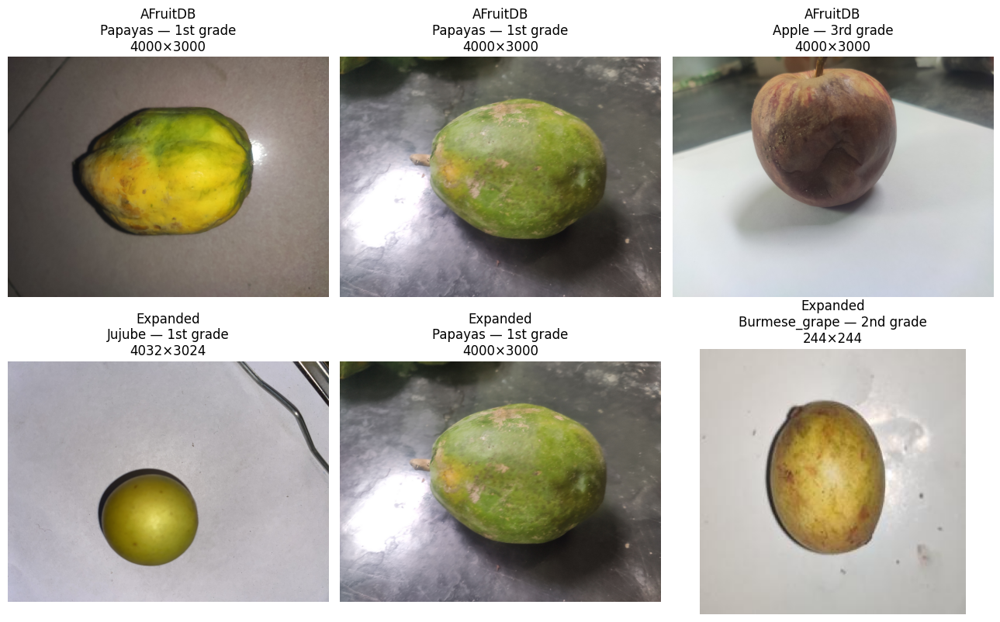


[3] Image metadata
AFruitDB   | Papayas         | 1st grade  | 4000 x 3000
AFruitDB   | Papayas         | 1st grade  | 4000 x 3000
AFruitDB   | Apple           | 3rd grade  | 4000 x 3000
Expanded   | Jujube          | 1st grade  | 4032 x 3024
Expanded   | Papayas         | 1st grade  | 4000 x 3000
Expanded   | Burmese_grape   | 2nd grade  |  244 x  244

STEP 8E COMPLETE


In [ ]:
from pathlib import Path
import pandas as pd
import zipfile
import io
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

MANIFEST_PATH = (
    ROOT / "datasets/audit/quality_control/"
    "final_dataset_checkpoint/final_record_split_manifest_v2.csv"
)

AFRUITDB_ZIP = ROOT / "datasets/original/AFruitDB_original.zip"
EXPANDED_ZIP = ROOT / "datasets/original/Bangladeshi_Fruit_Grade_original.zip"

manifest = pd.read_csv(MANIFEST_PATH)

# Reproducible sample: training split only
pilot = (
    manifest[manifest["split"] == "train"]
    .groupby("dataset", group_keys=False)
    .sample(n=3, random_state=20261123)
    .reset_index(drop=True)
)

print("=" * 70)
print("STEP 8E — IMAGE LOADING PILOT")
print("=" * 70)

loaded_images = []
errors = []

# Open Expanded archive
with zipfile.ZipFile(EXPANDED_ZIP, "r") as expanded_zip:

    # Open AFruitDB outer ZIP and its nested ZIP
    with zipfile.ZipFile(AFRUITDB_ZIP, "r") as afruit_outer:

        nested_zip_name = next(
            name for name in afruit_outer.namelist()
            if name.lower().endswith(".zip")
        )

        nested_bytes = afruit_outer.read(nested_zip_name)

        with zipfile.ZipFile(io.BytesIO(nested_bytes), "r") as afruit_inner:

            for _, row in pilot.iterrows():

                dataset = row["dataset"]
                relative_path = row["relative_path"].replace("\\", "/")

                try:
                    if dataset == "AFruitDB":
                        image_bytes = afruit_inner.read(relative_path)
                    elif dataset == "Expanded":
                        image_bytes = expanded_zip.read(relative_path)
                    else:
                        raise ValueError(f"Unexpected dataset: {dataset}")

                    # Decode image and convert to standard RGB
                    image = Image.open(io.BytesIO(image_bytes))
                    image.load()
                    image = image.convert("RGB")

                    loaded_images.append({
                        "dataset": dataset,
                        "fruit": row["fruit"],
                        "grade": row["grade"],
                        "split": row["split"],
                        "path": relative_path,
                        "image": image,
                        "width": image.width,
                        "height": image.height,
                        "format": image.format
                    })

                except Exception as e:
                    errors.append({
                        "dataset": dataset,
                        "path": relative_path,
                        "error": str(e)
                    })

# Display images
print("\n[1] Loaded images:", len(loaded_images))
print("[2] Errors:", len(errors))

if loaded_images:
    fig, axes = plt.subplots(
        2, 3, figsize=(13, 8)
    )

    for ax, item in zip(axes.flat, loaded_images):
        ax.imshow(item["image"])
        ax.set_title(
            f'{item["dataset"]}\n'
            f'{item["fruit"]} — {item["grade"]}\n'
            f'{item["width"]}×{item["height"]}'
        )
        ax.axis("off")

    for ax in axes.flat[len(loaded_images):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("\n[3] Image metadata")
    for item in loaded_images:
        print(
            f'{item["dataset"]:10s} | '
            f'{item["fruit"]:15s} | '
            f'{item["grade"]:10s} | '
            f'{item["width"]:4d} x {item["height"]:4d}'
        )

if errors:
    print("\n[4] Errors encountered:")
    for error in errors:
        print(error)

print("\n" + "=" * 70)
print("STEP 8E COMPLETE")
print("=" * 70)

In [ ]:
import shutil
import psutil
from pathlib import Path

print("=" * 70)
print("STEP 8F — RUNTIME RESOURCE CHECK")
print("=" * 70)

# RAM
ram = psutil.virtual_memory()

print("\n[1] RAM")
print(f"Total RAM:     {ram.total / (1024**3):.2f} GB")
print(f"Available RAM:  {ram.available / (1024**3):.2f} GB")
print(f"RAM used:      {ram.percent}%")

# Local Colab storage
disk = shutil.disk_usage("/content")

print("\n[2] Local disk (/content)")
print(f"Total:         {disk.total / (1024**3):.2f} GB")
print(f"Free:          {disk.free / (1024**3):.2f} GB")

# Dataset archive sizes
ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

print("\n[3] Original archive sizes")
for archive in [
    ROOT / "datasets/original/AFruitDB_original.zip",
    ROOT / "datasets/original/Bangladeshi_Fruit_Grade_original.zip"
]:
    if archive.exists():
        print(f"{archive.name}: {archive.stat().st_size / (1024**3):.2f} GB")
    else:
        print(f"NOT FOUND: {archive.name}")

print("\n" + "=" * 70)
print("STEP 8F COMPLETE — RESOURCE CHECK ONLY")
print("=" * 70)

STEP 8F — RUNTIME RESOURCE CHECK

[1] RAM
Total RAM:     12.67 GB
Available RAM:  7.53 GB
RAM used:      40.5%

[2] Local disk (/content)
Total:         107.72 GB
Free:          99.18 GB

[3] Original archive sizes
AFruitDB_original.zip: 2.93 GB
Bangladeshi_Fruit_Grade_original.zip: 2.54 GB

STEP 8F COMPLETE — RESOURCE CHECK ONLY


In [ ]:
from pathlib import Path
import pandas as pd
import zipfile
import io

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

manifest_path = (
    ROOT / "datasets/audit/quality_control/"
    "final_dataset_checkpoint/final_record_split_manifest_v2.csv"
)

archives = {
    "AFruitDB": ROOT / "datasets/original/AFruitDB_original.zip",
    "Expanded": ROOT / "datasets/original/Bangladeshi_Fruit_Grade_original.zip"
}

manifest = pd.read_csv(manifest_path)

print("=" * 70)
print("STEP 8G — TRAIN/VALIDATION CACHE SIZE ESTIMATE")
print("=" * 70)

results = []

for dataset, archive_path in archives.items():

    subset = manifest[
        (manifest["dataset"] == dataset) &
        (manifest["split"].isin(["train", "validation"]))
    ]

    target_paths = set(
        subset["relative_path"].str.replace("\\", "/", regex=False)
    )

    if dataset == "AFruitDB":

        with zipfile.ZipFile(archive_path, "r") as outer:
            nested_name = next(
                n for n in outer.namelist()
                if n.lower().endswith(".zip")
            )

            # Read nested archive bytes (metadata inspection only)
            nested_bytes = outer.read(nested_name)

            with zipfile.ZipFile(io.BytesIO(nested_bytes), "r") as inner:
                sizes = {
                    info.filename: info.file_size
                    for info in inner.infolist()
                    if not info.is_dir()
                }

    else:
        with zipfile.ZipFile(archive_path, "r") as archive:
            sizes = {
                info.filename: info.file_size
                for info in archive.infolist()
                if not info.is_dir()
            }

    matched_sizes = [
        sizes[path] for path in target_paths
        if path in sizes
    ]

    total_bytes = sum(matched_sizes)

    results.append({
        "dataset": dataset,
        "train_validation_images": len(subset),
        "matched_images": len(matched_sizes),
        "uncompressed_GB": total_bytes / (1024**3)
    })

    print(f"\n{dataset}")
    print("Train + validation records:", len(subset))
    print("Matched paths:", len(matched_sizes))
    print(f"Uncompressed image size: {total_bytes / (1024**3):.2f} GB")

print("\n[Combined estimate]")
combined_gb = sum(r["uncompressed_GB"] for r in results)
print(f"Train + validation cache: {combined_gb:.2f} GB")

print("\n" + "=" * 70)
print("STEP 8G COMPLETE — METADATA ONLY")
print("=" * 70)

STEP 8G — TRAIN/VALIDATION CACHE SIZE ESTIMATE

AFruitDB
Train + validation records: 2678
Matched paths: 2678
Uncompressed image size: 2.52 GB

Expanded
Train + validation records: 3195
Matched paths: 3195
Uncompressed image size: 2.20 GB

[Combined estimate]
Train + validation cache: 4.72 GB

STEP 8G COMPLETE — METADATA ONLY


In [ ]:
from pathlib import Path
import pandas as pd
import zipfile

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

manifest_path = (
    ROOT / "datasets/audit/quality_control/"
    "final_dataset_checkpoint/final_record_split_manifest_v2.csv"
)

manifest = pd.read_csv(manifest_path)

train_val = manifest[
    manifest["split"].isin(["train", "validation"])
].copy()

# Deduplicate by content hash
unique_images = train_val.drop_duplicates(subset="sha256")

print("=" * 70)
print("STEP 8H — DEDUPLICATED CACHE ESTIMATE")
print("=" * 70)

print("\n[1] Record vs unique image counts")
print("Train + validation records:", len(train_val))
print("Unique image contents:", len(unique_images))
print("Duplicate records avoided:", len(train_val) - len(unique_images))

print("\n[2] Unique images by dataset")
print(
    unique_images.groupby("dataset")
    .agg(
        unique_images=("sha256", "count"),
        fruits=("fruit", "nunique")
    )
)

# Count archive bytes for unique image contents
size_by_hash = {}

for dataset in ["AFruitDB", "Expanded"]:

    subset = unique_images[unique_images["dataset"] == dataset]

    archive_path = (
        ROOT / "datasets/original/AFruitDB_original.zip"
        if dataset == "AFruitDB"
        else ROOT / "datasets/original/Bangladeshi_Fruit_Grade_original.zip"
    )

    if dataset == "AFruitDB":
        # Nested archive must be accessed
        import io

        with zipfile.ZipFile(archive_path, "r") as outer:
            nested_name = next(
                n for n in outer.namelist()
                if n.lower().endswith(".zip")
            )

            nested_bytes = outer.read(nested_name)

            with zipfile.ZipFile(io.BytesIO(nested_bytes), "r") as inner:
                for _, row in subset.iterrows():
                    info = inner.getinfo(row["relative_path"])
                    size_by_hash[row["sha256"]] = info.file_size

    else:
        with zipfile.ZipFile(archive_path, "r") as archive:
            for _, row in subset.iterrows():
                info = archive.getinfo(row["relative_path"])
                size_by_hash[row["sha256"]] = info.file_size

total_bytes = sum(size_by_hash.values())

print("\n[3] Estimated unique cache size")
print("Unique hashes measured:", len(size_by_hash))
print(f"Estimated cache: {total_bytes / (1024**3):.2f} GB")

print("\n[4] Recommended approach")
print("Cache each unique SHA-256 image once on local Colab disk.")
print("Use the frozen manifest to map records to cached image files.")

print("\n" + "=" * 70)
print("STEP 8H COMPLETE — NO FILES MODIFIED")
print("=" * 70)

STEP 8H — DEDUPLICATED CACHE ESTIMATE

[1] Record vs unique image counts
Train + validation records: 5873
Unique image contents: 4133
Duplicate records avoided: 1740

[2] Unique images by dataset
          unique_images  fruits
dataset                        
AFruitDB           2678       6
Expanded           1455       3

[3] Estimated unique cache size
Unique hashes measured: 4133
Estimated cache: 3.06 GB

[4] Recommended approach
Cache each unique SHA-256 image once on local Colab disk.
Use the frozen manifest to map records to cached image files.

STEP 8H COMPLETE — NO FILES MODIFIED


In [ ]:
from pathlib import Path
import pandas as pd
import shutil

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

MANIFEST_PATH = (
    ROOT / "datasets/audit/quality_control/"
    "final_dataset_checkpoint/final_record_split_manifest_v2.csv"
)

CACHE_ROOT = Path("/content/fruit_freshness_cache")
IMAGE_CACHE = CACHE_ROOT / "images"
CACHE_MANIFEST = CACHE_ROOT / "train_validation_cache_manifest.csv"

manifest = pd.read_csv(MANIFEST_PATH)

# Only training and validation records
train_val = manifest[
    manifest["split"].isin(["train", "validation"])
].copy()

# One row per unique image content
unique_images = train_val.drop_duplicates(subset="sha256").copy()

# Check local disk capacity
disk = shutil.disk_usage("/content")

estimated_bytes = 3.06 * (1024**3)
safety_margin = 2 * (1024**3)

print("=" * 70)
print("STEP 8I — CACHE PREFLIGHT")
print("=" * 70)

print("\n[1] Planned cache")
print("Unique images:", len(unique_images))
print(f"Estimated image storage: {estimated_images_gb if 'estimated_images_gb' in globals() else 3.06:.2f} GB")
print("Cache directory:", IMAGE_CACHE)

print("\n[2] Available disk")
print(f"Free disk: {disk.free / (1024**3):.2f} GB")
print(f"Estimated cache: {estimated_bytes / (1024**3):.2f} GB")
print(f"Safety margin: {safety_margin / (1024**3):.2f} GB")

print("\n[3] Preconditions")
checks = {
    "Manifest exists": MANIFEST_PATH.exists(),
    "Unique image count is 4133": len(unique_images) == 4133,
    "SHA-256 column exists": "sha256" in unique_images.columns,
    "Relative path column exists": "relative_path" in unique_images.columns,
    "Dataset column exists": "dataset" in unique_images.columns,
    "No missing hashes": unique_images["sha256"].notna().all(),
    "No missing paths": unique_images["relative_path"].notna().all(),
    "Enough free disk space": disk.free > estimated_bytes + safety_margin,
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} — {name}")

print("\n[4] Cache will include these splits:")
print(train_val["split"].value_counts().to_string())

print("\n" + "=" * 70)
if all(checks.values()):
    print("STEP 8I COMPLETE — PREFLIGHT PASSED")
    print("No images copied. Ready for cache construction.")
else:
    print("STEP 8I COMPLETE — PREFLIGHT NEEDS ATTENTION")
    print("Review failed checks before proceeding.")
print("=" * 70)

STEP 8I — CACHE PREFLIGHT

[1] Planned cache
Unique images: 4133
Estimated image storage: 3.06 GB
Cache directory: /content/fruit_freshness_cache/images

[2] Available disk
Free disk: 99.18 GB
Estimated cache: 3.06 GB
Safety margin: 2.00 GB

[3] Preconditions
PASS — Manifest exists
PASS — Unique image count is 4133
PASS — SHA-256 column exists
PASS — Relative path column exists
PASS — Dataset column exists
PASS — No missing hashes
PASS — No missing paths
PASS — Enough free disk space

[4] Cache will include these splits:
split
train         4835
validation    1038

STEP 8I COMPLETE — PREFLIGHT PASSED
No images copied. Ready for cache construction.


In [ ]:
from pathlib import Path
import pandas as pd
import zipfile
import hashlib
import shutil
import tempfile
import os

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

MANIFEST_PATH = (
    ROOT / "datasets/audit/quality_control/"
    "final_dataset_checkpoint/final_record_split_manifest_v2.csv"
)

AFRUITDB_ZIP = ROOT / "datasets/original/AFruitDB_original.zip"
EXPANDED_ZIP = ROOT / "datasets/original/Bangladeshi_Fruit_Grade_original.zip"

CACHE_ROOT = Path("/content/fruit_freshness_cache")
IMAGE_CACHE = CACHE_ROOT / "images"
CACHE_MANIFEST_PATH = CACHE_ROOT / "train_validation_cache_manifest.csv"

CACHE_ROOT.mkdir(parents=True, exist_ok=True)
IMAGE_CACHE.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(MANIFEST_PATH)

# Only train and validation records
train_val = manifest[
    manifest["split"].isin(["train", "validation"])
].copy()

# One source record per unique image hash
unique_images = train_val.drop_duplicates(subset="sha256").copy()

# ------------------------------------------------------------
# Helper: verify SHA-256 content
# ------------------------------------------------------------
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

# ------------------------------------------------------------
# Build cache
# ------------------------------------------------------------
print("=" * 70)
print("STEP 8J — VERIFIED CACHE CONSTRUCTION")
print("=" * 70)

completed = 0
skipped_valid = 0
repaired = 0
failed = []

# Store temporary nested ZIP on local disk to avoid loading ~GB into RAM
temporary_nested_zip = CACHE_ROOT / "AFruitDB_inner_temporary.zip"

try:

    # Extract only the nested ZIP container to local temporary disk
    print("\n[1] Preparing temporary AFruitDB inner ZIP...")

    with zipfile.ZipFile(AFRUITDB_ZIP, "r") as outer:
        nested_name = next(
            n for n in outer.namelist()
            if n.lower().endswith(".zip")
        )

        with outer.open(nested_name) as source:
            with open(temporary_nested_zip, "wb") as destination:
                shutil.copyfileobj(source, destination, length=1024 * 1024)

    print("Temporary nested ZIP prepared.")

    with zipfile.ZipFile(temporary_nested_zip, "r") as afruit_inner, \
         zipfile.ZipFile(EXPANDED_ZIP, "r") as expanded_archive:

        for i, (_, row) in enumerate(unique_images.iterrows(), start=1):

            expected_hash = str(row["sha256"])
            relative_path = str(row["relative_path"]).replace("\\", "/")
            dataset = row["dataset"]

            cache_path = IMAGE_CACHE / f"{expected_hash}.jpg"

            # Resume behavior: verify an existing cached file
            if cache_path.exists():
                try:
                    if sha256_file(cache_path) == expected_hash:
                        skipped_valid += 1
                        continue
                    else:
                        cache_path.unlink()
                        repaired += 1
                except Exception:
                    if cache_path.exists():
                        cache_path.unlink()
                    repaired += 1

            try:
                # Read image from correct archive
                if dataset == "AFruitDB":
                    image_bytes = afruit_inner.read(relative_path)
                elif dataset == "Expanded":
                    image_bytes = expanded_archive.read(relative_path)
                else:
                    raise ValueError(f"Unexpected dataset: {dataset}")

                # Verify bytes BEFORE writing
                actual_hash = sha256_bytes(image_bytes)

                if actual_hash != expected_hash:
                    raise ValueError(
                        f"SHA mismatch! expected={expected_hash}, "
                        f"actual={actual_hash}"
                    )

                # Write to temporary file, then atomically rename
                temp_path = cache_path.with_suffix(".tmp")

                with open(temp_path, "wb") as f:
                    f.write(image_bytes)

                # Verify written file again
                if sha256_file(temp_path) != expected_hash:
                    temp_path.unlink(missing_ok=True)
                    raise ValueError("Cached file verification failed")

                os.replace(temp_path, cache_path)
                completed += 1

            except Exception as e:
                failed.append({
                    "hash": expected_hash,
                    "dataset": dataset,
                    "path": relative_path,
                    "error": str(e)
                })

            if i % 250 == 0:
                print(
                    f"Progress: {i}/{len(unique_images)} | "
                    f"new={completed} | reused={skipped_valid} | "
                    f"repaired={repaired} | errors={len(failed)}"
                )

finally:
    # Remove temporary nested ZIP regardless of success or interruption
    if temporary_nested_zip.exists():
        temporary_nested_zip.unlink()

# ------------------------------------------------------------
# Save cache manifest (only if caching loop completed)
# ------------------------------------------------------------
cache_manifest = unique_images[
    ["sha256", "dataset", "relative_path", "fruit", "grade", "split"]
].copy()

cache_manifest["cache_path"] = cache_manifest["sha256"].apply(
    lambda h: str(IMAGE_CACHE / f"{h}.jpg")
)

cache_manifest["cache_exists"] = cache_manifest["cache_path"].apply(
    lambda p: Path(p).exists()
)

cache_manifest["cache_verified"] = cache_manifest.apply(
    lambda r: (
        r["cache_exists"] and
        sha256_file(Path(r["cache_path"])) == r["sha256"]
    ),
    axis=1
)

cache_manifest.to_csv(CACHE_MANIFEST_PATH, index=False)

# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------
print("\n[2] CACHE SUMMARY")
print("Unique images requested:", len(unique_images))
print("New files written:", completed)
print("Valid existing files reused:", skipped_valid)
print("Existing files repaired:", repaired)
print("Failures:", len(failed))
print("Verified files:", int(cache_manifest["cache_verified"].sum()))
print("Cache manifest:", CACHE_MANIFEST_PATH)

print("\n[3] Cache size")
cache_bytes = sum(
    p.stat().st_size
    for p in IMAGE_CACHE.glob("*.jpg")
    if p.is_file()
)
print(f"Current image cache: {cache_bytes / (1024**3):.2f} GB")

if failed:
    print("\n[4] Failed images (first 10)")
    for item in failed[:10]:
        print(item)

print("\n" + "=" * 70)
if (
    not failed and
    cache_manifest["cache_verified"].all() and
    len(cache_manifest) == 4133
):
    print("STEP 8J SUCCESS — CACHE FULLY VERIFIED")
else:
    print("STEP 8J FINISHED — REVIEW SUMMARY BEFORE PROCEEDING")
print("=" * 70)

STEP 8J — VERIFIED CACHE CONSTRUCTION

[1] Preparing temporary AFruitDB inner ZIP...
Temporary nested ZIP prepared.
Progress: 250/4133 | new=250 | reused=0 | repaired=0 | errors=0
Progress: 500/4133 | new=500 | reused=0 | repaired=0 | errors=0
Progress: 750/4133 | new=750 | reused=0 | repaired=0 | errors=0
Progress: 1000/4133 | new=1000 | reused=0 | repaired=0 | errors=0
Progress: 1250/4133 | new=1250 | reused=0 | repaired=0 | errors=0
Progress: 1500/4133 | new=1500 | reused=0 | repaired=0 | errors=0
Progress: 1750/4133 | new=1750 | reused=0 | repaired=0 | errors=0
Progress: 2000/4133 | new=2000 | reused=0 | repaired=0 | errors=0
Progress: 2250/4133 | new=2250 | reused=0 | repaired=0 | errors=0
Progress: 2500/4133 | new=2500 | reused=0 | repaired=0 | errors=0
Progress: 2750/4133 | new=2750 | reused=0 | repaired=0 | errors=0
Progress: 3000/4133 | new=3000 | reused=0 | repaired=0 | errors=0
Progress: 3250/4133 | new=3250 | reused=0 | repaired=0 | errors=0
Progress: 3500/4133 | new=3500 |

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

ORIGINAL_MANIFEST = (
    ROOT / "datasets/audit/quality_control/"
    "final_dataset_checkpoint/final_record_split_manifest_v2.csv"
)

CACHE_ROOT = Path("/content/fruit_freshness_cache")
CACHE_MANIFEST_PATH = CACHE_ROOT / "train_validation_cache_manifest.csv"
IMAGE_CACHE = CACHE_ROOT / "images"

manifest = pd.read_csv(ORIGINAL_MANIFEST)
cache_manifest = pd.read_csv(CACHE_MANIFEST_PATH)

train_val = manifest[manifest["split"].isin(["train", "validation"])].copy()

print("=" * 70)
print("STEP 8K — CACHE-TO-MANIFEST INTEGRITY CHECK")
print("=" * 70)

# 1. Record counts
print("\n[1] Record counts")
print("Original train + validation records:", len(train_val))
print("Cache manifest entries:", len(cache_manifest))
print("Expected unique image hashes:", train_val["sha256"].nunique())

# 2. Check cache-manifest uniqueness
print("\n[2] Cache manifest uniqueness")
print("Unique cache hashes:", cache_manifest["sha256"].nunique())
print("Duplicate hash entries:", cache_manifest["sha256"].duplicated().sum())

# 3. Verify files physically exist
print("\n[3] Cached files")
existing_files = cache_manifest["sha256"].apply(
    lambda h: (IMAGE_CACHE / f"{h}.jpg").exists()
)
print("Existing cached files:", int(existing_files.sum()))
print("Missing cached files:", int((~existing_files).sum()))

# 4. Verify source labels remain mapped
print("\n[4] Label mapping")
required_columns = ["sha256", "fruit", "grade", "split", "dataset"]
for column in required_columns:
    print(f"{column}: {'OK' if column in train_val.columns else 'MISSING'}")

print("\nRecords by split:")
print(train_val["split"].value_counts())

print("\nClass count:")
print("Fruit-grade combinations:", train_val.groupby(["fruit", "grade"]).ngroups)

# 5. Verify cache hashes against source records
source_hashes = set(train_val["sha256"])
cache_hashes = set(cache_manifest["sha256"])

print("\n[5] Hash coverage")
print("Source unique hashes:", len(source_hashes))
print("Cache unique hashes:", len(cache_hashes))
print("Missing hashes from cache:", len(source_hashes - cache_hashes))
print("Unexpected cache hashes:", len(cache_hashes - source_hashes))

# 6. Check split protection
print("\n[6] Split safety")
print("Splits present in cache manifest:")
print(cache_manifest["split"].value_counts().to_string())

test_hashes = set(manifest.loc[manifest["split"] == "test", "sha256"])
cached_test_overlap = source_hashes.intersection(test_hashes)

print("Train/validation cache hashes overlapping test hashes:",
      len(cached_test_overlap))

print("\n" + "=" * 70)

checks = [
    len(train_val) == 5873,
    len(cache_manifest) == 4133,
    cache_manifest["sha256"].nunique() == 4133,
    existing_files.all(),
    source_hashes == cache_hashes,
    len(cached_test_overlap) == 0,
    set(cache_manifest["split"].unique()) == {"train", "validation"},
]

if all(checks):
    print("STEP 8K PASSED — READY TO BUILD DATA LOADER")
else:
    print("STEP 8K NEEDS REVIEW — DO NOT TRAIN YET")

print("=" * 70)

STEP 8K — CACHE-TO-MANIFEST INTEGRITY CHECK

[1] Record counts
Original train + validation records: 5873
Cache manifest entries: 4133
Expected unique image hashes: 4133

[2] Cache manifest uniqueness
Unique cache hashes: 4133
Duplicate hash entries: 0

[3] Cached files
Existing cached files: 4133
Missing cached files: 0

[4] Label mapping
sha256: OK
fruit: OK
grade: OK
split: OK
dataset: OK

Records by split:
split
train         4835
validation    1038
Name: count, dtype: int64

Class count:
Fruit-grade combinations: 21

[5] Hash coverage
Source unique hashes: 4133
Cache unique hashes: 4133
Missing hashes from cache: 0
Unexpected cache hashes: 0

[6] Split safety
Splits present in cache manifest:
split
train         3401
validation     732
Train/validation cache hashes overlapping test hashes: 0

STEP 8K PASSED — READY TO BUILD DATA LOADER


In [ ]:
from pathlib import Path
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np

# ============================================================
# STEP 8L — PYTORCH DATA LOADER
# ============================================================

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

MANIFEST_PATH = (
    ROOT / "datasets/audit/quality_control/"
    "final_dataset_checkpoint/final_record_split_manifest_v2.csv"
)

CACHE_ROOT = Path("/content/fruit_freshness_cache")
IMAGE_CACHE = CACHE_ROOT / "images"

manifest = pd.read_csv(MANIFEST_PATH)

# Restrict this pipeline to TRAIN and VALIDATION only
train_df = manifest[manifest["split"] == "train"].copy()
val_df = manifest[manifest["split"] == "validation"].copy()

# ------------------------------------------------------------
# 1. Deterministic class mapping
# ------------------------------------------------------------
fruit_order = sorted(manifest["fruit"].unique())

grade_order = ["1st grade", "2nd grade", "3rd grade"]

classes = [
    (fruit, grade)
    for fruit in fruit_order
    for grade in grade_order
    if ((manifest["fruit"] == fruit) &
        (manifest["grade"] == grade)).any()
]

class_to_idx = {
    f"{fruit}_{grade}": idx
    for idx, (fruit, grade) in enumerate(classes)
}

idx_to_class = {
    idx: label
    for label, idx in class_to_idx.items()
}

def encode_label(fruit, grade):
    return class_to_idx[f"{fruit}_{grade}"]

# ------------------------------------------------------------
# 2. Dataset class
# ------------------------------------------------------------
class FruitGradeDataset(Dataset):

    def __init__(self, dataframe, image_cache, class_mapping,
                 image_size=224):

        self.df = dataframe.reset_index(drop=True)
        self.image_cache = Path(image_cache)
        self.class_mapping = class_mapping
        self.image_size = image_size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image_path = self.image_cache / f"{row['sha256']}.jpg"

        # Read cached image
        image = Image.open(image_path).convert("RGB")

        # Resize
        image = image.resize(
            (self.image_size, self.image_size),
            Image.Resampling.BILINEAR
        )

        # Convert to tensor: HWC -> CHW, scale 0–255 to 0–1
        image_array = np.asarray(image, dtype=np.float32) / 255.0
        image_tensor = torch.from_numpy(image_array).permute(2, 0, 1)

        # Encode fruit-grade class
        label_name = f"{row['fruit']}_{row['grade']}"
        label = self.class_mapping[label_name]

        return image_tensor, torch.tensor(label, dtype=torch.long)

# ------------------------------------------------------------
# 3. Create datasets
# ------------------------------------------------------------
train_dataset = FruitGradeDataset(
    train_df,
    IMAGE_CACHE,
    class_to_idx,
    image_size=224
)

val_dataset = FruitGradeDataset(
    val_df,
    IMAGE_CACHE,
    class_to_idx,
    image_size=224
)

# ------------------------------------------------------------
# 4. Create DataLoaders
# ------------------------------------------------------------
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

# ------------------------------------------------------------
# 5. Verification
# ------------------------------------------------------------
print("=" * 70)
print("STEP 8L — DATA LOADER VERIFICATION")
print("=" * 70)

print("\n[1] Dataset sizes")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

print("\n[2] Number of classes:", len(class_to_idx))

print("\n[3] Class mapping")
for idx, label in idx_to_class.items():
    print(f"{idx:2d} -> {label}")

print("\n[4] Batch counts")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Fetch one batch from each loader
train_images, train_labels = next(iter(train_loader))
val_images, val_labels = next(iter(val_loader))

print("\n[5] Tensor shape check")
print("Train image batch:", train_images.shape)
print("Train labels:", train_labels.shape)
print("Validation image batch:", val_images.shape)
print("Validation labels:", val_labels.shape)

print("\n[6] Pixel range check")
print("Train min:", train_images.min().item())
print("Train max:", train_images.max().item())

print("\n[7] Label range check")
print("Train labels:", train_labels.min().item(),
      "to", train_labels.max().item())
print("Validation labels:", val_labels.min().item(),
      "to", val_labels.max().item())

print("\n[8] Device availability")
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n" + "=" * 70)
print("STEP 8L COMPLETE — DATA PIPELINE TEST ONLY")
print("NO MODEL TRAINING PERFORMED")
print("=" * 70)

STEP 8L — DATA LOADER VERIFICATION

[1] Dataset sizes
Train: 4835
Validation: 1038

[2] Number of classes: 21

[3] Class mapping
 0 -> Apple_1st grade
 1 -> Apple_2nd grade
 2 -> Apple_3rd grade
 3 -> Banana_1st grade
 4 -> Banana_2nd grade
 5 -> Banana_3rd grade
 6 -> Burmese_grape_1st grade
 7 -> Burmese_grape_2nd grade
 8 -> Burmese_grape_3rd grade
 9 -> Jujube_1st grade
10 -> Jujube_2nd grade
11 -> Jujube_3rd grade
12 -> Mango_1st grade
13 -> Mango_2nd grade
14 -> Mango_3rd grade
15 -> Papayas_1st grade
16 -> Papayas_2nd grade
17 -> Papayas_3rd grade
18 -> Tomatoes_1st grade
19 -> Tomatoes_2nd grade
20 -> Tomatoes_3rd grade

[4] Batch counts
Train batches: 152
Validation batches: 33

[5] Tensor shape check
Train image batch: torch.Size([32, 3, 224, 224])
Train labels: torch.Size([32])
Validation image batch: torch.Size([32, 3, 224, 224])
Validation labels: torch.Size([32])

[6] Pixel range check
Train min: 0.0
Train max: 1.0

[7] Label range check
Train labels: 0 to 20
Validation l

In [ ]:
from collections import Counter
import torch

print("=" * 70)
print("STEP 8M — FULL VALIDATION LABEL AUDIT")
print("=" * 70)

# Collect labels from the ENTIRE validation loader
all_val_labels = []

for _, labels in val_loader:
    all_val_labels.extend(labels.cpu().tolist())

counts = Counter(all_val_labels)

print("\n[1] Validation label coverage")
print(f"Total validation labels: {len(all_val_labels)}")
print(f"Unique classes found: {len(counts)} / 21")
print(f"Minimum label: {min(all_val_labels)}")
print(f"Maximum label: {max(all_val_labels)}")

print("\n[2] Count per class ID")
for class_id in range(21):
    print(f"Class {class_id:2d}: {counts.get(class_id, 0):4d} images")

print("\n[3] Missing class IDs")
missing_classes = [i for i in range(21) if counts.get(i, 0) == 0]
print(missing_classes if missing_classes else "None")

print("\n[4] Validation integrity result")
if len(all_val_labels) == 1038 and len(counts) == 21:
    print("PASS — all 21 classes are present in the validation set.")
else:
    print("CHECK REQUIRED — validation distribution needs investigation.")

print("=" * 70)
print("STEP 8M COMPLETE — VALIDATION LABEL AUDIT")
print("=" * 70)

STEP 8M — FULL VALIDATION LABEL AUDIT

[1] Validation label coverage
Total validation labels: 1038
Unique classes found: 21 / 21
Minimum label: 0
Maximum label: 20

[2] Count per class ID
Class  0:   58 images
Class  1:   52 images
Class  2:   32 images
Class  3:   73 images
Class  4:   71 images
Class  5:   20 images
Class  6:   95 images
Class  7:   47 images
Class  8:   50 images
Class  9:   23 images
Class 10:   24 images
Class 11:   23 images
Class 12:   74 images
Class 13:   74 images
Class 14:   36 images
Class 15:   46 images
Class 16:   44 images
Class 17:   46 images
Class 18:   44 images
Class 19:   68 images
Class 20:   38 images

[3] Missing class IDs
None

[4] Validation integrity result
PASS — all 21 classes are present in the validation set.
STEP 8M COMPLETE — VALIDATION LABEL AUDIT


In [ ]:
import platform
import torch
import torchvision
import psutil

print("=" * 70)
print("STEP 8N — ENVIRONMENT & MODEL COMPATIBILITY AUDIT")
print("=" * 70)

print("\n[1] Software versions")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

print("\n[2] Hardware")
print("Processor:", platform.processor() or "Not reported")
print("CPU logical cores:", psutil.cpu_count(logical=True))
print("CPU physical cores:", psutil.cpu_count(logical=False))
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
    ), "GB")

print("\n[3] RAM")
ram = psutil.virtual_memory()
print("Total RAM:", round(ram.total / (1024**3), 2), "GB")
print("Available RAM:", round(ram.available / (1024**3), 2), "GB")

print("\n[4] PyTorch device selection")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

print("\n[5] Available pretrained model architectures")
available_models = [
    "mobilenet_v3_small",
    "mobilenet_v3_large",
    "efficientnet_b0",
    "resnet18",
]

for name in available_models:
    print(f" - {name}")

print("\n" + "=" * 70)
print("STEP 8N COMPLETE — ENVIRONMENT AUDIT ONLY")
print("NO MODEL TRAINING PERFORMED")
print("=" * 70)

STEP 8N — ENVIRONMENT & MODEL COMPATIBILITY AUDIT

[1] Software versions
Python: 3.13.18
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu

[2] Hardware
Processor: x86_64
CPU logical cores: 2
CPU physical cores: 1
CUDA available: False

[3] RAM
Total RAM: 12.67 GB
Available RAM: 7.33 GB

[4] PyTorch device selection
Selected device: cpu

[5] Available pretrained model architectures
 - mobilenet_v3_small
 - mobilenet_v3_large
 - efficientnet_b0
 - resnet18

STEP 8N COMPLETE — ENVIRONMENT AUDIT ONLY
NO MODEL TRAINING PERFORMED


In [ ]:
import pandas as pd
from pathlib import Path

print("=" * 70)
print("TASK 1 — CLASS IMBALANCE AUDIT")
print("STEP 1A — FROZEN MANIFEST INSPECTION")
print("=" * 70)

manifest_path = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/"
    "quality_control/final_dataset_checkpoint/"
    "final_record_split_manifest_v2.csv"
)

if not manifest_path.exists():
    raise FileNotFoundError(
        f"Frozen manifest not found:\n{manifest_path}\n"
        "Please verify that Google Drive is mounted."
    )

audit_df = pd.read_csv(manifest_path)

print("\n[1] Manifest successfully loaded")
print("Rows:", len(audit_df))
print("Columns:", len(audit_df.columns))

print("\n[2] Column names")
for col in audit_df.columns:
    print(" -", col)

print("\n[3] Preview (first 5 rows)")
display(audit_df.head())

print("\n[4] Candidate class and split columns")
for col in audit_df.columns:
    if any(word in col.lower() for word in
           ["fruit", "grade", "class", "label", "split"]):
        print(f"{col}: {audit_df[col].nunique(dropna=False)} unique values")

print("\n" + "=" * 70)
print("STEP 1A COMPLETE — READ-ONLY INSPECTION")
print("NO DATA CHANGED")
print("=" * 70)

TASK 1 — CLASS IMBALANCE AUDIT
STEP 1A — FROZEN MANIFEST INSPECTION

[1] Manifest successfully loaded
Rows: 6908
Columns: 19

[2] Column names
 - dataset
 - filename
 - relative_path
 - fruit
 - grade
 - file_size
 - sha256
 - duplicate_group_id
 - duplicate_group_unique_hashes
 - quarantine_reason
 - dataset_status
 - group_requires_quarantine
 - split_group_id
 - split
 - final_group_type
 - final_dataset_status
 - final_quarantine_flag
 - final_grouping_method
 - metadata_reconciliation_note

[3] Preview (first 5 rows)


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine,split_group_id,split,final_group_type,final_dataset_status,final_quarantine_flag,final_grouping_method,metadata_reconciliation_note
0,AFruitDB,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_3d8522b532808676afab5a21758d7b662ec187dfda...,validation,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
1,AFruitDB,IMG_20230930_172429.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1173056,f2a4aa7eb44d3d55da034eab8f9192a167ee501a433037...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_f2a4aa7eb44d3d55da034eab8f9192a167ee501a43...,test,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
2,AFruitDB,IMG_20230930_172432.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1179042,7d142228f2983320288d16186fd406c85a8b20e3d25739...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_7d142228f2983320288d16186fd406c85a8b20e3d2...,test,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
3,AFruitDB,IMG_20230930_172439.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1140016,1d791349b86caa51efe1adf9c62cc70459498a4c909390...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_1d791349b86caa51efe1adf9c62cc70459498a4c90...,train,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...
4,AFruitDB,IMG_20230930_172444.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1178878,6054012b993e207c9eb97b82a18c454131b30674eeea6f...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True,SHA_6054012b993e207c9eb97b82a18c454131b30674ee...,test,SHA_SINGLETON_GROUP,RETAINED_QC_CLEAN,False,SHA256_SINGLE_IMAGE_GROUP,Legacy audit fields preserved for traceability...



[4] Candidate class and split columns
fruit: 7 unique values
grade: 3 unique values
split_group_id: 4765 unique values
split: 3 unique values

STEP 1A COMPLETE — READ-ONLY INSPECTION
NO DATA CHANGED


In [ ]:
import pandas as pd
import numpy as np

print("=" * 75)
print("STEP 1B — CLASS DISTRIBUTION & IMBALANCE ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# 1. Filter to final retained, non-quarantined records
# ------------------------------------------------------------
clean_df = audit_df[
    (audit_df["final_dataset_status"] == "RETAINED_QC_CLEAN") &
    (audit_df["final_quarantine_flag"] == False)
].copy()

print("\n[1] Final clean dataset")
print("Retained records:", len(clean_df))
print("Quarantined/excluded records:", len(audit_df) - len(clean_df))

# ------------------------------------------------------------
# 2. Create class labels
# ------------------------------------------------------------
clean_df["class_name"] = clean_df["fruit"] + "_" + clean_df["grade"]

class_names = sorted(clean_df["class_name"].unique())

print("\n[2] Class overview")
print("Number of classes:", len(class_names))
print("Class names:")
for name in class_names:
    print(" -", name)

# ------------------------------------------------------------
# 3. Count records per class and split
# ------------------------------------------------------------
distribution = pd.crosstab(
    clean_df["class_name"],
    clean_df["split"]
)

# Ensure consistent split column order
split_order = ["train", "validation", "test"]
distribution = distribution.reindex(columns=split_order, fill_value=0)

distribution["Total"] = distribution.sum(axis=1)

# ------------------------------------------------------------
# 4. Add percentages within each split
# ------------------------------------------------------------
split_totals = distribution[split_order].sum(axis=0)

percentage_table = distribution[split_order].copy()

for split_name in split_order:
    if split_totals[split_name] > 0:
        percentage_table[split_name] = (
            distribution[split_name] / split_totals[split_name] * 100
        )

print("\n[3] Image counts per class and split")
display(distribution)

print("\n[4] Percentage distribution within each split (%)")
display(percentage_table.round(2))

print("\n[5] Total images per split")
for split_name in split_order:
    print(f"{split_name:10s}: {split_totals[split_name]:,}")

# ------------------------------------------------------------
# 6. Training class imbalance statistics
# ------------------------------------------------------------
train_counts = distribution["train"]

min_count = train_counts.min()
max_count = train_counts.max()
mean_count = train_counts.mean()

imbalance_ratio = max_count / min_count

# Standard inverse-frequency weights:
# weight_c = N / (K * n_c)
# where N = total training samples, K = number of classes,
# and n_c = number of training samples in class c.
class_weights = len(clean_df[clean_df["split"] == "train"]) / (
    len(class_names) * train_counts
)

print("\n[6] Training imbalance statistics")
print("Smallest class:", train_counts.idxmin(), "=", min_count)
print("Largest class:", train_counts.idxmax(), "=", max_count)
print("Mean class count:", round(mean_count, 2))
print("Max/min imbalance ratio:", round(imbalance_ratio, 3))

print("\n[7] Diagnostic inverse-frequency class weights")
weight_table = pd.DataFrame({
    "train_images": train_counts,
    "diagnostic_weight": class_weights
}).sort_values("train_images")

display(weight_table.round(4))

# ------------------------------------------------------------
# 8. Integrity checks
# ------------------------------------------------------------
print("\n[8] Integrity checks")

print("Clean records:", len(clean_df))
print("Classes:", clean_df["class_name"].nunique())
print("Split values:", sorted(clean_df["split"].unique()))
print("Missing class labels:", clean_df["class_name"].isna().sum())
print("Missing split labels:", clean_df["split"].isna().sum())

assert len(clean_df) == 6908, "Unexpected retained dataset size!"
assert clean_df["class_name"].nunique() == 21, "Expected 21 classes!"
assert set(clean_df["split"].unique()) == {"train", "validation", "test"}
assert clean_df["final_quarantine_flag"].eq(False).all()

print("\nPASS — class imbalance audit calculated successfully.")
print("No data or frozen manifest was modified.")

print("=" * 75)
print("STEP 1B COMPLETE")
print("=" * 75)

STEP 1B — CLASS DISTRIBUTION & IMBALANCE ANALYSIS

[1] Final clean dataset
Retained records: 6908
Quarantined/excluded records: 0

[2] Class overview
Number of classes: 21
Class names:
 - Apple_1st grade
 - Apple_2nd grade
 - Apple_3rd grade
 - Banana_1st grade
 - Banana_2nd grade
 - Banana_3rd grade
 - Burmese_grape_1st grade
 - Burmese_grape_2nd grade
 - Burmese_grape_3rd grade
 - Jujube_1st grade
 - Jujube_2nd grade
 - Jujube_3rd grade
 - Mango_1st grade
 - Mango_2nd grade
 - Mango_3rd grade
 - Papayas_1st grade
 - Papayas_2nd grade
 - Papayas_3rd grade
 - Tomatoes_1st grade
 - Tomatoes_2nd grade
 - Tomatoes_3rd grade

[3] Image counts per class and split


split,train,validation,test,Total
class_name,,,,
Apple_1st grade,278,58,60,396
Apple_2nd grade,240,52,52,344
Apple_3rd grade,158,32,34,224
Banana_1st grade,341,73,72,486
Banana_2nd grade,334,71,73,478
Banana_3rd grade,91,20,19,130
Burmese_grape_1st grade,429,95,90,614
Burmese_grape_2nd grade,217,47,50,314
Burmese_grape_3rd grade,230,50,50,330



[4] Percentage distribution within each split (%)


split,train,validation,test
class_name,,,
Apple_1st grade,5.75,5.59,5.80
Apple_2nd grade,4.96,5.01,5.02
Apple_3rd grade,3.27,3.08,3.29
Banana_1st grade,7.05,7.03,6.96
Banana_2nd grade,6.91,6.84,7.05
Banana_3rd grade,1.88,1.93,1.84
Burmese_grape_1st grade,8.87,9.15,8.70
Burmese_grape_2nd grade,4.49,4.53,4.83
Burmese_grape_3rd grade,4.76,4.82,4.83



[5] Total images per split
train     : 4,835
validation: 1,038
test      : 1,035

[6] Training imbalance statistics
Smallest class: Banana_3rd grade = 91
Largest class: Burmese_grape_1st grade = 429
Mean class count: 230.24
Max/min imbalance ratio: 4.714

[7] Diagnostic inverse-frequency class weights


,train_images,diagnostic_weight
class_name,,
Banana_3rd grade,91,2.5301
Jujube_1st grade,104,2.2138
Jujube_3rd grade,105,2.1927
Jujube_2nd grade,115,2.0021
Apple_3rd grade,158,1.4572
Mango_3rd grade,164,1.4039
Tomatoes_3rd grade,176,1.3082
Tomatoes_1st grade,204,1.1286
Papayas_2nd grade,206,1.1177



[8] Integrity checks
Clean records: 6908
Classes: 21
Split values: ['test', 'train', 'validation']
Missing class labels: 0
Missing split labels: 0

PASS — class imbalance audit calculated successfully.
No data or frozen manifest was modified.
STEP 1B COMPLETE


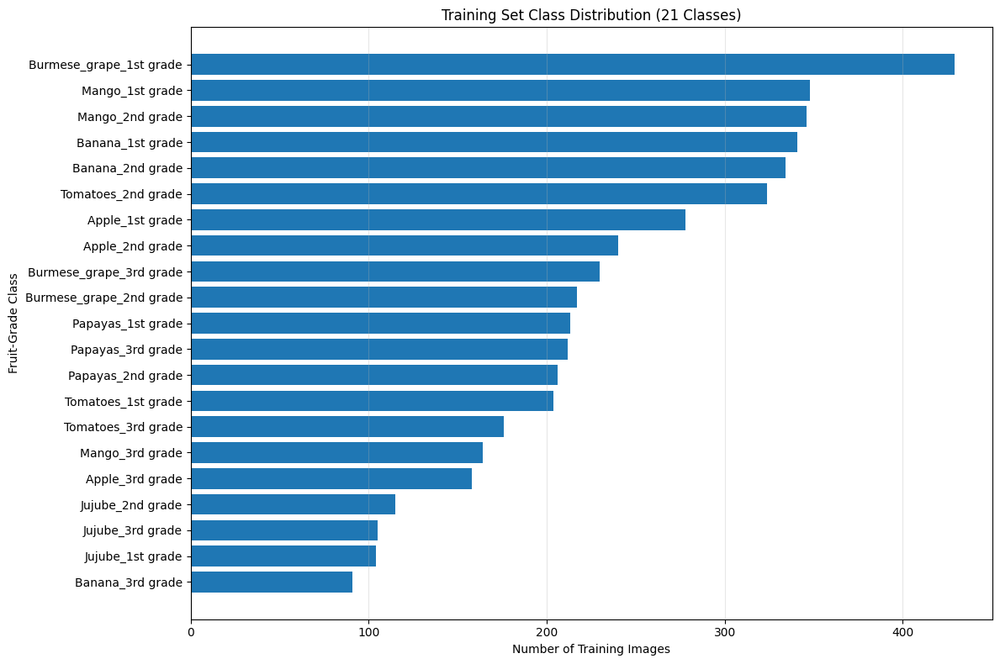

Smallest class: Banana_3rd grade 91
Largest class: Burmese_grape_1st grade 429
Imbalance ratio: 4.714


In [ ]:
import matplotlib.pyplot as plt

# Training class counts, sorted from smallest to largest
train_plot = train_counts.sort_values(ascending=True)

plt.figure(figsize=(12, 8))
plt.barh(train_plot.index, train_plot.values)
plt.xlabel("Number of Training Images")
plt.ylabel("Fruit-Grade Class")
plt.title("Training Set Class Distribution (21 Classes)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Smallest class:", train_plot.index[0], train_plot.iloc[0])
print("Largest class:", train_plot.index[-1], train_plot.iloc[-1])
print("Imbalance ratio:", round(train_plot.max() / train_plot.min(), 3))

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

print("=" * 70)
print("TASK 2 — DATASET DOCUMENTATION & PROVENANCE")
print("STEP 2A — DOCUMENTATION INVENTORY")
print("=" * 70)

search_dirs = [
    ROOT,
    ROOT / "datasets",
    ROOT / "datasets" / "audit",
    ROOT / "datasets" / "audit" / "quality_control",
    ROOT / "experiments",
]

extensions = {
    ".md", ".txt", ".csv", ".json",
    ".yaml", ".yml", ".xlsx"
}

found_files = []

for folder in search_dirs:
    if folder.exists():
        for file in folder.rglob("*"):
            if file.is_file() and file.suffix.lower() in extensions:
                found_files.append(file)

found_files = sorted(set(found_files))

print("\n[1] Documentation and data-record files found")

if not found_files:
    print("No documentation files found in the inspected directories.")
else:
    for file in found_files:
        relative = file.relative_to(ROOT)
        size_kb = file.stat().st_size / 1024
        print(f"{relative}  |  {size_kb:.1f} KB")

print("\n[2] Documentation keyword scan")

keywords = [
    "dataset",
    "provenance",
    "source",
    "license",
    "licence",
    "annotation",
    "label",
    "grade",
    "exclusion",
    "quarantine",
    "split",
    "methodology",
]

documentation_extensions = {".md", ".txt", ".json", ".yaml", ".yml"}

for file in found_files:
    if file.suffix.lower() not in documentation_extensions:
        continue

    try:
        text = file.read_text(errors="ignore").lower()
        matches = [keyword for keyword in keywords if keyword in text]

        if matches:
            print(f"\n{file.relative_to(ROOT)}")
            print("Matched keywords:", ", ".join(matches))

    except Exception as e:
        print(f"Could not read {file.name}: {e}")

print("\n" + "=" * 70)
print("STEP 2A COMPLETE — INVENTORY ONLY")
print("NO FILES CREATED OR MODIFIED")
print("=" * 70)

TASK 2 — DATASET DOCUMENTATION & PROVENANCE
STEP 2A — DOCUMENTATION INVENTORY

[1] Documentation and data-record files found
datasets/audit/afruitdb_candidate_image_group_manifest_v2.csv  |  20.5 KB
datasets/audit/afruitdb_clean_manifest.csv  |  591.2 KB
datasets/audit/afruitdb_complete_grouped_manifest_summary_v2.csv  |  0.2 KB
datasets/audit/afruitdb_complete_grouped_manifest_v2.csv  |  692.3 KB
datasets/audit/afruitdb_count_reconciliation.csv  |  0.2 KB
datasets/audit/afruitdb_cross_pair_links_v2.csv  |  0.9 KB
datasets/audit/afruitdb_different_label_candidates.csv  |  6.9 KB
datasets/audit/afruitdb_duplicate_group_summary_v2.csv  |  5.4 KB
datasets/audit/afruitdb_image_manifest.csv  |  592.3 KB
datasets/audit/afruitdb_internal_phash_candidates.csv  |  35.6 KB
datasets/audit/afruitdb_matching_label_candidates.csv  |  28.9 KB
datasets/audit/afruitdb_matching_label_sheet_errors.csv  |  0.0 KB
datasets/audit/afruitdb_matching_label_sheets/matching_label_candidate_metadata.csv  |  28.9 

In [ ]:
from pathlib import Path

checkpoint_dir = (
    ROOT / "datasets" / "audit" / "quality_control"
    / "final_dataset_checkpoint"
)

files_to_read = [
    checkpoint_dir / "split_freeze_record.txt",
    checkpoint_dir / "split_integrity_report.txt",
]

print("=" * 70)
print("STEP 2B — READ EXISTING FREEZE DOCUMENTATION")
print("=" * 70)

for file_path in files_to_read:
    print(f"\n{'=' * 70}")
    print("FILE:", file_path.name)
    print("=" * 70)

    if not file_path.exists():
        print("WARNING: File not found.")
        continue

    content = file_path.read_text(encoding="utf-8", errors="replace")
    print(content)

print("\n" + "=" * 70)
print("STEP 2B COMPLETE — READ ONLY")
print("NO FILES MODIFIED")
print("=" * 70)

STEP 2B — READ EXISTING FREEZE DOCUMENTATION

FILE: split_freeze_record.txt
FRUIT FRESHNESS RESEARCH
TRAIN / VALIDATION / TEST SPLIT FREEZE RECORD

Freeze record created: 2026-11-23 15:44:48

STATUS:
SPLIT ASSIGNMENTS FROZEN

DATASET SUMMARY:
- Retained image records: 6,908
- Unique SHA-256 image contents: 4,862
- Corrected split groups: 4,765
- Fruit-grade classes: 21

SPLIT DISTRIBUTION:
- Train: 4,835 records
- Validation: 1,038 records
- Test: 1,035 records

SPLIT PROPORTIONS:
- Train: approximately 70%
- Validation: approximately 15%
- Test: approximately 15%

INTEGRITY CHECKS:
- Exact SHA-256 leakage across splits: 0
- Corrected duplicate-group leakage across splits: 0
- Missing split assignments: 0
- Unexpected split labels: 0

SPLITTING METHOD:
Group-aware stratified splitting using corrected split_group_id.
The group assignment was verified to ensure groups do not cross
train, validation, or test boundaries.

TEST SET POLICY:
The test split is reserved for final evaluation.
It

In [ ]:
print("=" * 75)
print("STEP 2C — SOURCE DATASET COMPOSITION AUDIT")
print("=" * 75)

# Dataset record totals
print("\n[1] Record totals by source dataset")
display(clean_df["dataset"].value_counts().rename("records").to_frame())

# Fruit composition by dataset
print("\n[2] Fruit composition by source")
fruit_by_dataset = pd.crosstab(
    clean_df["dataset"],
    clean_df["fruit"],
    margins=True
)
display(fruit_by_dataset)

# Grade composition by source
print("\n[3] Grade composition by source")
grade_by_dataset = pd.crosstab(
    clean_df["dataset"],
    clean_df["grade"],
    margins=True
)
display(grade_by_dataset)

# Fruit-grade composition by source
print("\n[4] Fruit-grade classes by source")
source_class_counts = pd.crosstab(
    [clean_df["dataset"], clean_df["fruit"]],
    clean_df["grade"]
)
display(source_class_counts)

# Source-specific unique hashes
print("\n[5] Unique image content by source dataset")
unique_hashes_by_source = (
    clean_df.groupby("dataset")["sha256"]
    .nunique()
    .rename("unique_sha256")
    .to_frame()
)
display(unique_hashes_by_source)

# Verify source labels
print("\n[6] Dataset names in frozen manifest")
print(sorted(clean_df["dataset"].dropna().unique()))

# Confirm total count
print("\n[7] Total reconciliation")
print("Dataset rows:", len(clean_df))
print("Source totals sum:",
      clean_df.groupby("dataset").size().sum())
print("Unique SHA-256 across combined dataset:",
      clean_df["sha256"].nunique())

assert clean_df.groupby("dataset").size().sum() == len(clean_df)

print("\nSTEP 2C COMPLETE — COMPOSITION AUDIT")
print("READ ONLY — NO FILES MODIFIED")
print("=" * 75)

STEP 2C — SOURCE DATASET COMPOSITION AUDIT

[1] Record totals by source dataset


,records
dataset,
Expanded,3748
AFruitDB,3160



[2] Fruit composition by source


fruit,Apple,Banana,Burmese_grape,Jujube,Mango,Papayas,Tomatoes,All
dataset,,,,,,,,
AFruitDB,482,484,629,0,612,451,502,3160
Expanded,482,610,629,463,612,450,502,3748
All,964,1094,1258,463,1224,901,1004,6908



[3] Grade composition by source


grade,1st grade,2nd grade,3rd grade,All
dataset,,,,
AFruitDB,1293,1193,674,3160
Expanded,1441,1357,950,3748
All,2734,2550,1624,6908



[4] Fruit-grade classes by source


grade                   1st grade  2nd grade  3rd grade
dataset  fruit                                         
AFruitDB Apple                198        172        112
         Banana               243        239          2
         Burmese_grape        307        157        165
         Mango                248        247        117
         Papayas              152        147        152
         Tomatoes             145        231        126
Expanded Apple                198        172        112
         Banana               243        239        128
         Burmese_grape        307        157        165
         Jujube               149        164        150
         Mango                248        247        117
         Papayas              151        147        152
         Tomatoes             145        231        126


[5] Unique image content by source dataset


,unique_sha256
dataset,
AFruitDB,3160
Expanded,3748



[6] Dataset names in frozen manifest
['AFruitDB', 'Expanded']

[7] Total reconciliation
Dataset rows: 6908
Source totals sum: 6908
Unique SHA-256 across combined dataset: 4862

STEP 2C COMPLETE — COMPOSITION AUDIT
READ ONLY — NO FILES MODIFIED


In [ ]:
from pathlib import Path
import zipfile

archive_dir = ROOT / "datasets" / "original"

archives = [
    archive_dir / "AFruitDB_original.zip",
    archive_dir / "Bangladeshi_Fruit_Grade_original.zip",
]

print("=" * 75)
print("STEP 2D — ORIGINAL ARCHIVE DOCUMENTATION SEARCH")
print("=" * 75)

documentation_terms = [
    "readme", "license", "licence", "metadata",
    "citation", "reference", "about", "description",
    "annotation", "label", "dataset", "paper"
]

for archive_path in archives:
    print("\n" + "-" * 75)
    print("ARCHIVE:", archive_path.name)
    print("-" * 75)

    if not archive_path.exists():
        print("ERROR: Archive not found:", archive_path)
        continue

    with zipfile.ZipFile(archive_path, "r") as zf:
        members = zf.namelist()

        print("Total archive entries:", len(members))

        # Search documentation-like filenames
        doc_files = [
            name for name in members
            if any(term in Path(name).name.lower()
                   for term in documentation_terms)
            and not name.endswith("/")
        ]

        print("\nPotential documentation/metadata files:")
        if doc_files:
            for name in doc_files[:100]:
                info = zf.getinfo(name)
                print(f"{name} | {info.file_size:,} bytes")
        else:
            print("No obvious documentation files found.")

        # Show top-level structure
        print("\nTop-level archive entries:")
        top_level = sorted(set(
            name.split("/")[0] for name in members if name
        ))

        for name in top_level[:40]:
            print(" -", name)

print("\n" + "=" * 75)
print("STEP 2D COMPLETE — ARCHIVES INSPECTED")
print("READ ONLY — ORIGINAL ZIP FILES UNCHANGED")
print("=" * 75)

STEP 2D — ORIGINAL ARCHIVE DOCUMENTATION SEARCH

---------------------------------------------------------------------------
ARCHIVE: AFruitDB_original.zip
---------------------------------------------------------------------------
Total archive entries: 1

Potential documentation/metadata files:
No obvious documentation files found.

Top-level archive entries:
 - A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research

---------------------------------------------------------------------------
ARCHIVE: Bangladeshi_Fruit_Grade_original.zip
---------------------------------------------------------------------------
Total archive entries: 3757

Potential documentation/metadata files:
No obvious documentation files found.

Top-level archive entries:
 - Bangladeshi Fruit Grade classification

STEP 2D COMPLETE — ARCHIVES INSPECTED
READ ONLY — ORIGINAL ZIP FILES UNCHANGED


In [ ]:
from pathlib import Path
from datetime import datetime

docs_dir = ROOT / "documentation"
docs_dir.mkdir(parents=True, exist_ok=True)

provenance_file = docs_dir / "dataset_provenance_draft.md"

provenance_text = """# Fruit Freshness Research — Dataset Provenance (Draft)

Last updated: 2026-11-23

## 1. Purpose

This document records the origin, composition, preprocessing, and known
limitations of the image dataset used in the Fruit Freshness research project.

The current task is image-level classification into a dataset-defined
21-class fruit-grade label space. The labels should not be interpreted
as nationally standardized commercial grades unless independent evidence
establishes that equivalence.

## 2. Source datasets

### 2.1 AFruitDB

Source title:
A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research

Dataset DOI:
https://doi.org/10.17632/bz65dz2pbj.1

Accompanying publication:
AFruitDB: A comprehensive dataset of six commonly used Asian fruits
for advanced grading and biodiversity insights.

Publication DOI:
https://doi.org/10.1016/j.dib.2025.111380

Published source description:
- 3,167 images
- Six fruit types: Apple, Banana, Burmese grape, Mango, Papaya, Tomato
- Three source quality categories: good, medium, bad
- License reported as CC BY 4.0

The current project manifest retains 3,160 records attributed to AFruitDB.

### 2.2 Bangladeshi Fruit Grade Classification

Public source title:
Bangladeshi Fruit Grade classification

Dataset DOI:
https://doi.org/10.17632/bp9fczshw5.1

Published source description:
- 3,757 images
- Seven fruit types: Apple, Banana, Burmese grape, Jujube,
  Mango, Papayas, Tomatoes
- 21 fruit-grade classes
- License reported as CC BY 4.0

The current project internally refers to this dataset as "Expanded".
The current project manifest retains 3,748 records attributed to Expanded.

## 3. Current combined dataset

Dataset source counts in the retained manifest:

| Source | Retained records |
|---|---:|
| AFruitDB | 3,160 |
| Expanded | 3,748 |
| Total | 6,908 |

Fruit counts in the retained manifest:

| Fruit | Records |
|---|---:|
| Apple | 964 |
| Banana | 1,094 |
| Burmese grape | 1,258 |
| Jujube | 463 |
| Mango | 1,224 |
| Papayas | 901 |
| Tomatoes | 1,004 |
| Total | 6,908 |

Grade counts in the retained manifest:

| Grade label | Records |
|---|---:|
| 1st grade | 2,734 |
| 2nd grade | 2,550 |
| 3rd grade | 1,624 |
| Total | 6,908 |

The resulting classification space contains 21 fruit-grade classes.

## 4. Source-count reconciliation status

Published counts:
- AFruitDB: 3,167
- Expanded: 3,757
- Combined published totals: 6,924

Current retained project manifest:
- AFruitDB: 3,160
- Expanded: 3,748
- Combined retained records: 6,908

Numerical differences:
- AFruitDB: 7 fewer records than the published count
- Expanded: 9 fewer records than the published count
- Combined: 16 fewer records

These differences are confirmed, but the complete source-specific attribution
of all count differences remains pending detailed reconciliation.
Do not assume all differences arise from duplicate removal or quality
exclusions without verifying the relevant audit records.

## 5. Label harmonization

The merged project uses:
- 1st grade
- 2nd grade
- 3rd grade

This is the project's unified label schema.

The AFruitDB publication describes source categories as good, medium, and bad.
The Expanded dataset is published using 1st-grade, 2nd-grade, and
3rd-grade labels.

The project uses a common 21-class output space. However, equivalence
between source-specific grading criteria has not been independently
established. Consequently, model results should be described as performance
on the harmonized dataset labels, not as proof of a universally consistent
fruit-quality standard.

## 6. Dataset quality control

The project performed:
- Image decoding and quality checks
- Exact duplicate detection using SHA-256
- Duplicate-group reconciliation
- Label-conflict review
- Image-quality screening
- Manual exclusion of three severely blurred images
- Group-aware train/validation/test splitting

Original source archives are preserved.

## 7. Frozen dataset statistics

- Retained image records: 6,908
- Unique SHA-256 image contents: 4,862
- Corrected duplicate groups: 4,765
- Classes: 21

Frozen split:
- Training: 4,835 records
- Validation: 1,038 records
- Test: 1,035 records

Split proportions are approximately 70% / 15% / 15%.

Exact-image leakage across splits: 0
Duplicate-group leakage across splits: 0
Missing split assignments: 0

Split assignment was group-aware and stratified using the corrected
split_group_id. The frozen split must not be regenerated or modified
during model development.

## 8. Split usage policy

### Training split
Permitted for model fitting, training augmentation, and training-only
parameter estimation.

### Validation split
Permitted for model selection, hyperparameter decisions, and development
comparisons.

### Test split
Reserved for final evaluation after model and experimental decisions
are frozen. It must not be used for training, model selection,
hyperparameter tuning, quantization calibration, or repeated exploratory
evaluation.

## 9. License and attribution

The source dataset records report Creative Commons Attribution 4.0
(CC BY 4.0).

Appropriate attribution should be included in research outputs.
Dataset license details and source citations should be verified against
the exact source versions used.

Sources:
- AFruitDB dataset:
  https://data.mendeley.com/datasets/bz65dz2pbj/1
- AFruitDB article:
  https://doi.org/10.1016/j.dib.2025.111380
- Bangladeshi Fruit Grade Classification:
  https://data.mendeley.com/datasets/bp9fczshw5/1

## 10. Limitations and unresolved documentation items

- Source-specific count reconciliation remains to be fully documented.
- Original grading criteria may not be equivalent across datasets.
- Label harmonization does not establish independent expert validation.
- The combined data are not necessarily representative of all fruit markets
  or production conditions in Bangladesh.
- Images may contain source-specific acquisition, lighting, background,
  and camera characteristics.
- The dataset does not establish real-world commercial grading accuracy.
- The current classification task is image-level classification.
- No model has been trained at the time of this documentation draft.

## 11. Versioning and reproducibility

The current frozen dataset and split artifacts must be preserved.

Any change to image records, exclusions, labels, duplicate-group
membership, or split assignments requires a new dataset version and
documented justification.

This document is a draft and must be updated when outstanding provenance,
license, annotation, and reconciliation questions are resolved.
"""

provenance_file.write_text(provenance_text, encoding="utf-8")

print("=" * 70)
print("STEP 2F — PROVENANCE DRAFT CREATED")
print("=" * 70)
print("File:", provenance_file)
print("Exists:", provenance_file.exists())
print("Size:", round(provenance_file.stat().st_size / 1024, 2), "KB")
print("Last modified:", datetime.fromtimestamp(
    provenance_file.stat().st_mtime
).isoformat(timespec="seconds"))

print("\nPreview:")
print("\n".join(provenance_file.read_text(encoding="utf-8").splitlines()[:20]))

print("\nSTEP 2F COMPLETE — DRAFT DOCUMENT CREATED")
print("No dataset, manifest, or frozen split was changed.")

STEP 2F — PROVENANCE DRAFT CREATED
File: /content/drive/MyDrive/Fruit_Freshness_Research/documentation/dataset_provenance_draft.md
Exists: True
Size: 6.45 KB
Last modified: 2026-11-23T17:47:42

Preview:
# Fruit Freshness Research — Dataset Provenance (Draft)

Last updated: 2026-11-23

## 1. Purpose

This document records the origin, composition, preprocessing, and known
limitations of the image dataset used in the Fruit Freshness research project.

The current task is image-level classification into a dataset-defined
21-class fruit-grade label space. The labels should not be interpreted
as nationally standardized commercial grades unless independent evidence
establishes that equivalence.

## 2. Source datasets

### 2.1 AFruitDB

Source title:
A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research

STEP 2F COMPLETE — DRAFT DOCUMENT CREATED
No dataset, manifest, or frozen split was changed.


In [ ]:
from pathlib import Path
import pandas as pd

audit_dir = ROOT / "datasets" / "audit"
qc_dir = audit_dir / "quality_control"
recon_dir = audit_dir / "final_reconciliation"

candidate_files = [
    audit_dir / "archive_inventory.csv",
    audit_dir / "afruitdb_count_reconciliation.csv",
    qc_dir / "manual_quality_exclusions.csv",
    recon_dir / "quarantine_images.csv",
    recon_dir / "retained_pending_final_qc.csv",
]

print("=" * 75)
print("STEP 2G — SOURCE COUNT RECONCILIATION INVESTIGATION")
print("=" * 75)

for path in candidate_files:
    print("\n" + "-" * 75)
    print("FILE:", path.relative_to(ROOT))
    print("-" * 75)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    try:
        df = pd.read_csv(path)

        print("Rows:", len(df))
        print("Columns:", list(df.columns))

        if len(df) > 0:
            display(df.head(5))
        else:
            print("File is empty.")

    except Exception as e:
        print("Read error:", repr(e))

print("\n" + "=" * 75)
print("STEP 2G COMPLETE — AUDIT RECORD INSPECTION ONLY")
print("NO FILES MODIFIED")
print("=" * 75)

STEP 2G — SOURCE COUNT RECONCILIATION INVESTIGATION

---------------------------------------------------------------------------
FILE: datasets/audit/archive_inventory.csv
---------------------------------------------------------------------------
Rows: 2
Columns: ['dataset', 'total_files', 'image_files', 'other_files', 'uncompressed_GB', 'compressed_GB', 'extensions']


,dataset,total_files,image_files,other_files,uncompressed_GB,compressed_GB,extensions
0,AFruitDB,1,0,1,2.93,2.93,{'.zip': 1}
1,Expanded,3757,3756,1,2.60,2.54,"{'.ini': 1, '.jpg': 3756}"



---------------------------------------------------------------------------
FILE: datasets/audit/afruitdb_count_reconciliation.csv
---------------------------------------------------------------------------
Rows: 1
Columns: ['nested_zip_total_files', 'nested_zip_image_members', 'unique_image_paths', 'duplicate_archive_paths', 'manifest_rows', 'unique_manifest_paths', 'archive_missing_from_manifest', 'manifest_missing_from_archive']


,nested_zip_total_files,nested_zip_image_members,unique_image_paths,duplicate_archive_paths,manifest_rows,unique_manifest_paths,archive_missing_from_manifest,manifest_missing_from_archive
0,3167,3167,3167,0,3167,3167,0,0



---------------------------------------------------------------------------
FILE: datasets/audit/quality_control/manual_quality_exclusions.csv
---------------------------------------------------------------------------
Rows: 3
Columns: ['sha256', 'fruit', 'grade', 'relative_path', 'laplacian_variance', 'decision', 'reason']


,sha256,fruit,grade,relative_path,laplacian_variance,decision,reason
0,661a79a6627e108d46d187625e5cc0ce2d29fe886c6427...,Burmese_grape,1st grade,Bangladeshi Fruit Grade classification/Fruit g...,5.435904,EXCLUDE,Manually confirmed significantly blurry during...
1,85341f204e42a060f79f51b270a13dd4a7ca84c9354e80...,Banana,3rd grade,Bangladeshi Fruit Grade classification/Fruit g...,6.095318,EXCLUDE,Manually confirmed significantly blurry during...
2,a87f4efbb384a26c484a205cf07017fdd86f618509685f...,Burmese_grape,1st grade,Fruits Grade/Fruit grade/Burmese_grape/1st gra...,3.189578,EXCLUDE,Manually confirmed significantly blurry during...



---------------------------------------------------------------------------
FILE: datasets/audit/final_reconciliation/quarantine_images.csv
---------------------------------------------------------------------------
Rows: 6721
Columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine']


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine
0,AFruitDB,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
1,AFruitDB,IMG_20230930_172429.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1173056,f2a4aa7eb44d3d55da034eab8f9192a167ee501a433037...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
2,AFruitDB,IMG_20230930_172432.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1179042,7d142228f2983320288d16186fd406c85a8b20e3d25739...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
3,AFruitDB,IMG_20230930_172439.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1140016,1d791349b86caa51efe1adf9c62cc70459498a4c909390...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
4,AFruitDB,IMG_20230930_172444.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1178878,6054012b993e207c9eb97b82a18c454131b30674eeea6f...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True



---------------------------------------------------------------------------
FILE: datasets/audit/final_reconciliation/retained_pending_final_qc.csv
---------------------------------------------------------------------------
Rows: 6911
Columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine']


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine
0,AFruitDB,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
1,AFruitDB,IMG_20230930_172429.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1173056,f2a4aa7eb44d3d55da034eab8f9192a167ee501a433037...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
2,AFruitDB,IMG_20230930_172432.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1179042,7d142228f2983320288d16186fd406c85a8b20e3d25739...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
3,AFruitDB,IMG_20230930_172439.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1140016,1d791349b86caa51efe1adf9c62cc70459498a4c909390...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True
4,AFruitDB,IMG_20230930_172444.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1178878,6054012b993e207c9eb97b82a18c454131b30674eeea6f...,SINGLETON,1,NaN,RETAIN_PENDING_FINAL_QC,True



STEP 2G COMPLETE — AUDIT RECORD INSPECTION ONLY
NO FILES MODIFIED


In [ ]:
# ============================================================
# STEP 2H — MANIFEST STAGE INVENTORY
# Read-only inspection to identify the stages available
# for source-count reconciliation.
# ============================================================

from pathlib import Path
import pandas as pd

audit_dir = ROOT / "datasets" / "audit"

candidate_paths = [
    audit_dir / "afruitdb_clean_manifest.csv",
    audit_dir / "expanded_clean_manifest.csv",
    audit_dir / "expanded_image_manifest.csv",
    audit_dir / "final_reconciliation" / "retained_pending_final_qc.csv",
    audit_dir / "final_reconciliation" / "quarantine_images.csv",
    audit_dir / "quality_control" / "final_dataset_checkpoint"
        / "final_record_split_manifest_v2.csv",
]

print("=" * 85)
print("STEP 2H — MANIFEST STAGE INVENTORY")
print("=" * 85)

for path in candidate_paths:

    print("\n" + "-" * 85)
    print("FILE:", path.relative_to(ROOT) if path.exists() else path)
    print("-" * 85)

    if not path.exists():
        print("STATUS: File not found")
        continue

    try:
        df = pd.read_csv(path)

        print("Rows:", len(df))
        print("Columns:")
        print(df.columns.tolist())

        # Dataset-wise counts, if available
        if "dataset" in df.columns:
            print("\nCounts by dataset:")
            display(df["dataset"].value_counts(dropna=False))

        # Show useful path-related fields
        path_columns = [
            col for col in df.columns
            if any(term in col.lower()
                   for term in ["path", "filename", "file", "sha", "status"])
        ]

        print("\nRelevant identifier columns:")
        print(path_columns)

        # Small preview only
        display(df[path_columns].head(3) if path_columns else df.head(3))

    except Exception as e:
        print("READ ERROR:", repr(e))

print("\n" + "=" * 85)
print("STEP 2H COMPLETE — INVENTORY ONLY; NO FILES MODIFIED")
print("=" * 85)

STEP 2H — MANIFEST STAGE INVENTORY

-------------------------------------------------------------------------------------
FILE: datasets/audit/afruitdb_clean_manifest.csv
-------------------------------------------------------------------------------------
Rows: 3161
Columns:
['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256']

Counts by dataset:


,count
dataset,
AFruitDB,3161



Relevant identifier columns:
['filename', 'relative_path', 'file_size', 'sha256']


,filename,relative_path,file_size,sha256
0,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...
1,IMG_20230930_172429.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,1173056,f2a4aa7eb44d3d55da034eab8f9192a167ee501a433037...
2,IMG_20230930_172432.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,1179042,7d142228f2983320288d16186fd406c85a8b20e3d25739...



-------------------------------------------------------------------------------------
FILE: datasets/audit/expanded_clean_manifest.csv
-------------------------------------------------------------------------------------
Rows: 3750
Columns:
['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256']

Counts by dataset:


,count
dataset,
Expanded,3750


... (15 outputs left out)

,count
dataset,
Expanded,3748
AFruitDB,3160



Relevant identifier columns:
['filename', 'relative_path', 'file_size', 'sha256', 'dataset_status', 'final_dataset_status']


,filename,relative_path,file_size,sha256,dataset_status,final_dataset_status
0,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...,RETAIN_PENDING_FINAL_QC,RETAINED_QC_CLEAN
1,IMG_20230930_172429.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,1173056,f2a4aa7eb44d3d55da034eab8f9192a167ee501a433037...,RETAIN_PENDING_FINAL_QC,RETAINED_QC_CLEAN
2,IMG_20230930_172432.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,1179042,7d142228f2983320288d16186fd406c85a8b20e3d25739...,RETAIN_PENDING_FINAL_QC,RETAINED_QC_CLEAN



STEP 2H COMPLETE — INVENTORY ONLY; NO FILES MODIFIED


In [ ]:
# ============================================================
# STEP 2I — IDENTIFY INITIAL MANIFEST EXCLUSIONS
# Read-only path/hash comparison.
# ============================================================

import pandas as pd
from pathlib import Path

audit_dir = ROOT / "datasets" / "audit"

comparisons = [
    {
        "name": "AFruitDB",
        "original": audit_dir / "afruitdb_complete_grouped_manifest_v2.csv",
        "clean": audit_dir / "afruitdb_clean_manifest.csv",
    },
    {
        "name": "Expanded",
        "original": audit_dir / "expanded_image_manifest.csv",
        "clean": audit_dir / "expanded_clean_manifest.csv",
    },
]

KEY = "relative_path"

print("=" * 90)
print("STEP 2I — RECORD-LEVEL INITIAL EXCLUSION TRACE")
print("=" * 90)

for item in comparisons:

    name = item["name"]
    original_path = item["original"]
    clean_path = item["clean"]

    print(f"\n{'='*70}")
    print("DATASET:", name)
    print("="*70)

    if not original_path.exists():
        print("Original manifest NOT FOUND:", original_path)
        continue

    if not clean_path.exists():
        print("Clean manifest NOT FOUND:", clean_path)
        continue

    original = pd.read_csv(original_path)
    clean = pd.read_csv(clean_path)

    print("Original rows:", len(original))
    print("Clean rows:", len(clean))

    if KEY not in original.columns or KEY not in clean.columns:
        print("Missing relative_path column.")
        print("Original columns:", original.columns.tolist())
        print("Clean columns:", clean.columns.tolist())
        continue

    original_paths = set(original[KEY].astype(str))
    clean_paths = set(clean[KEY].astype(str))

    removed_paths = sorted(original_paths - clean_paths)
    added_paths = sorted(clean_paths - original_paths)

    print("Paths in original but not clean:", len(removed_paths))
    print("Paths in clean but not original:", len(added_paths))

    if removed_paths:
        removed_df = original[original[KEY].astype(str).isin(removed_paths)]

        print("\nRECORDS REMOVED BETWEEN THESE STAGES:")
        display(removed_df)

    if added_paths:
        print("\nUNEXPECTED PATHS ADDED:")
        display(clean[clean[KEY].astype(str).isin(added_paths)])

print("\n" + "="*90)
print("STEP 2I COMPLETE — COMPARISON ONLY; NO FILES MODIFIED")
print("="*90)

STEP 2I — RECORD-LEVEL INITIAL EXCLUSION TRACE

DATASET: AFruitDB
Original rows: 3167
Clean rows: 3161
Paths in original but not clean: 6
Paths in clean but not original: 0

RECORDS REMOVED BETWEEN THESE STAGES:


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,grouping_status,candidate_pair_ids
1838,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,NaN,not_flagged_by_current_review,NaN
1839,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,NaN,not_flagged_by_current_review,NaN
1840,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,NaN,not_flagged_by_current_review,NaN
2016,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,NaN,not_flagged_by_current_review,NaN
2017,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,NaN,not_flagged_by_current_review,NaN
2018,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,NaN,not_flagged_by_current_review,NaN



DATASET: Expanded
Original rows: 3756
Clean rows: 3750
Paths in original but not clean: 6
Paths in clean but not original: 0

RECORDS REMOVED BETWEEN THESE STAGES:


,dataset,filename,relative_path,fruit,grade,file_size,sha256
2432,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...
2433,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...
2434,Expanded,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...
2608,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...
2610,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...
2612,Expanded,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...



STEP 2I COMPLETE — COMPARISON ONLY; NO FILES MODIFIED


In [ ]:
# ============================================================
# STEP 2J — SEARCH AUDIT ARTIFACTS AND FILTERING LOGIC
# Read-only search for the three conflicting Mango images.
# ============================================================

from pathlib import Path
import pandas as pd

audit_dir = ROOT / "datasets" / "audit"

targets = [
    "IMG_20230819_192101.jpg",
    "IMG_20230819_192104.jpg",
    "IMG_20230819_192107.jpg",
]

hash_prefixes = [
    "c8f58822",
    "584f6114",
    "8523098a",
]

print("=" * 90)
print("STEP 2J — SEARCHING AUDIT ARTIFACTS")
print("=" * 90)

# ------------------------------------------------------------
# PART 1: Search all audit CSV files for target filenames
# ------------------------------------------------------------
print("\nPART 1 — CSV AUDIT ARTIFACT SEARCH")

csv_files = list(audit_dir.rglob("*.csv"))
matches_found = 0

for csv_path in csv_files:
    try:
        df = pd.read_csv(csv_path, dtype=str, low_memory=False)

        # Search all columns for target filenames or hash prefixes
        mask = pd.Series(False, index=df.index)

        for col in df.columns:
            series = df[col].fillna("").astype(str)

            for filename in targets:
                mask |= series.str.contains(filename, regex=False, na=False)

            for prefix in hash_prefixes:
                mask |= series.str.contains(prefix, regex=False, na=False)

        matched = df[mask]

        if not matched.empty:
            matches_found += len(matched)

            print("\n" + "-" * 80)
            print("FILE:", csv_path.relative_to(ROOT))
            print("Matching rows:", len(matched))
            display(matched.head(20))

    except Exception as e:
        print("Could not inspect:", csv_path.name, "|", repr(e))

print("\nTotal matching rows across CSV artifacts:", matches_found)


# ------------------------------------------------------------
# PART 2: Search code and documentation files for filtering logic
# ------------------------------------------------------------
print("\n\nPART 2 — SEARCHING CODE/DOCUMENTATION FILES")

search_extensions = {".py", ".ipynb", ".md", ".txt"}

search_terms = [
    "group_requires_quarantine",
    "not_flagged_by_current_review",
    "candidate_pair_ids",
    "grade conflict",
    "grade-conflict",
    "quarantine",
    "IMG_20230819_192101.jpg",
    "IMG_20230819_192104.jpg",
    "IMG_20230819_192107.jpg",
]

# Search project files, excluding large dataset/cache directories
excluded_dirs = {
    "datasets",
    ".git",
    "images",
    "image_cache",
    "__pycache__",
}

code_matches = 0

for file_path in ROOT.rglob("*"):

    if not file_path.is_file():
        continue

    if file_path.suffix.lower() not in search_extensions:
        continue

    if any(part in excluded_dirs for part in file_path.parts):
        continue

    try:
        # Skip unusually large text/code files
        if file_path.stat().st_size > 5_000_000:
            continue

        text = file_path.read_text(errors="ignore")
        lines = text.splitlines()

        found_lines = []

        for i, line in enumerate(lines):
            if any(term.lower() in line.lower() for term in search_terms):
                found_lines.append((i + 1, line[:300]))

        if found_lines:
            code_matches += 1

            print("\n" + "-" * 80)
            print("FILE:", file_path.relative_to(ROOT))

            for line_number, line_text in found_lines[:30]:
                print(f"Line {line_number}: {line_text}")

            if len(found_lines) > 30:
                print(f"... {len(found_lines)-30} additional matching lines")

    except Exception:
        pass

print("\nCode/document files containing matches:", code_matches)

print("\n" + "=" * 90)
print("STEP 2J COMPLETE — SEARCH ONLY; NO FILES MODIFIED")
print("=" * 90)

STEP 2J — SEARCHING AUDIT ARTIFACTS

PART 1 — CSV AUDIT ARTIFACT SEARCH

--------------------------------------------------------------------------------
FILE: datasets/audit/afruitdb_image_manifest.csv
Matching rows: 6


,dataset,filename,relative_path,fruit,grade,file_size,sha256
1838,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...
1839,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...
1840,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...
2016,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...
2017,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...
2018,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...



--------------------------------------------------------------------------------
FILE: datasets/audit/expanded_image_manifest.csv
Matching rows: 6


,dataset,filename,relative_path,fruit,grade,file_size,sha256
2432,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...
2433,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...
2434,Expanded,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...
2608,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...
2610,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...
2612,Expanded,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...



--------------------------------------------------------------------------------
FILE: datasets/audit/cross_dataset_exact_duplicates.csv
Matching rows: 12


,dataset_afruit,filename_afruit,relative_path_afruit,fruit_afruit,grade_afruit,file_size_afruit,sha256,dataset_expanded,filename_expanded,relative_path_expanded,fruit_expanded,grade_expanded,file_size_expanded
724,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1761064
725,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1761064
726,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1849405
727,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1849405
728,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,Expanded,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1686237
729,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,Expanded,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1686237
905,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1761064
906,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1761064
907,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1849405
908,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1849405


... (27 outputs left out)

,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine
1748,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
1749,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
1750,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
1926,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
1927,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
1928,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
5406,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
5407,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
5408,Expanded,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
5582,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True



--------------------------------------------------------------------------------
FILE: datasets/audit/final_reconciliation/quarantine_label_conflicts.csv
Matching rows: 12


,dataset,filename,relative_path,fruit,grade,file_size,sha256,duplicate_group_id,duplicate_group_unique_hashes,quarantine_reason,dataset_status,group_requires_quarantine
0,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
1,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
2,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
3,AFruitDB,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
4,AFruitDB,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
5,AFruitDB,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
6,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
7,Expanded,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1849405,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
8,Expanded,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1686237,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True
9,Expanded,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1761064,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,SINGLETON,1,Exact duplicate image assigned conflicting 1st...,QUARANTINE_LABEL_CONFLICT,True



Total matching rows across CSV artifacts: 156


PART 2 — SEARCHING CODE/DOCUMENTATION FILES

Code/document files containing matches: 0

STEP 2J COMPLETE — SEARCH ONLY; NO FILES MODIFIED


In [ ]:
from pathlib import Path
from datetime import datetime

# Paths
doc_path = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/documentation/"
    "dataset_provenance_draft.md"
)

# Verify the existing draft
if not doc_path.exists():
    raise FileNotFoundError(f"Draft not found: {doc_path}")

original_text = doc_path.read_text(encoding="utf-8")

# Create a timestamped backup before modifying anything
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup_path = doc_path.with_name(
    f"dataset_provenance_draft_backup_{timestamp}.md"
)
backup_path.write_text(original_text, encoding="utf-8")

# Audit reconciliation section
audit_section = """

## Dataset Count Reconciliation and Unresolved Audit Discrepancy

### Source-to-final dataset count reconciliation

The published source archives, intermediate cleaned manifests, and
final QC-filtered dataset were compared during dataset preparation.

The final dataset contains 6,908 image records, following the
documented exclusions and quality-control procedures.

The reconciliation identified 12 records associated with three unique
Mango image contents. Each of these image contents appeared under
both 1st-grade and 2nd-grade labels and across both source datasets.
The matching image contents were identified using image hashes.

These 12 records were absent from the intermediate clean manifests.
A search of the available audit CSV artifacts identified the relevant
records, but a search of available code and documentation files
returned zero matches explaining the filtering decision.

Therefore, the reason for the removal of these 12 records remains
UNRESOLVED. Their removal must not be described as an intentional,
documented filtering decision unless additional evidence is found.

### Separately documented image-quality exclusions

Three additional images were manually excluded for severe blur:
- 1 image from AFruitDB
- 2 images from the Expanded dataset

These exclusions are recorded in the manual quality-exclusion audit
artifact and are separate from the unresolved 12-record discrepancy.

### Reconciliation summary

- Published source image records: 6,923
- Records absent from intermediate clean manifests: 12
- Additional manually excluded severe-blur images: 3
- Final QC-clean dataset: 6,908 records

The 15-record difference between the published image-record total
and final QC-clean total is accounted for numerically by the 12
unresolved Mango records and the 3 documented severe-blur exclusions.
However, the filtering rationale for the 12 Mango records has not
been verified.

This discrepancy is retained transparently in the dataset provenance
record rather than assigned an unsupported explanation.

### Integrity and reproducibility note

The final dataset manifests and frozen group-level train/validation/test
split remain unchanged. This reconciliation is documentation-only and
does not authorize changes to the frozen dataset or test set.
"""

# Avoid accidentally adding this section more than once
marker = "## Dataset Count Reconciliation and Unresolved Audit Discrepancy"

if marker in original_text:
    print("The reconciliation section already exists.")
    print("No changes made to the draft.")
else:
    updated_text = original_text.rstrip() + "\n" + audit_section + "\n"
    doc_path.write_text(updated_text, encoding="utf-8")

    # Verify the write
    saved_text = doc_path.read_text(encoding="utf-8")

    if marker in saved_text and len(saved_text) > len(original_text):
        print("SUCCESS: Provenance draft updated and verified.")
        print(f"Backup: {backup_path}")
        print(f"Updated file: {doc_path}")
        print(f"Original size: {len(original_text):,} characters")
        print(f"Updated size: {len(saved_text):,} characters")
    else:
        raise RuntimeError("Verification failed after writing the update.")

SUCCESS: Provenance draft updated and verified.
Backup: /content/drive/MyDrive/Fruit_Freshness_Research/documentation/dataset_provenance_draft_backup_20261123_180441.md
Updated file: /content/drive/MyDrive/Fruit_Freshness_Research/documentation/dataset_provenance_draft.md
Original size: 6,599 characters
Updated size: 8,888 characters


In [ ]:
from pathlib import Path

doc_path = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/documentation/"
    "dataset_provenance_draft.md"
)

backup_path = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/documentation/"
    "dataset_provenance_draft_backup_20261123_180441.md"
)

text = doc_path.read_text(encoding="utf-8")

checks = {
    "Updated draft exists": doc_path.exists(),
    "Backup exists": backup_path.exists(),
    "Reconciliation section present": (
        "## Dataset Count Reconciliation and Unresolved Audit Discrepancy"
        in text
    ),
    "Unresolved discrepancy documented": "UNRESOLVED" in text,
    "Source total 6,923 documented": "6,923" in text,
    "Final dataset count 6,908 documented": "6,908" in text,
    "12-record discrepancy documented": "12" in text,
    "3 blur exclusions documented": "3" in text,
    "Test-set protection documented": "test set" in text.lower(),
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

print("\nOverall:", "PASS" if all(checks.values()) else "CHECK REQUIRED")
print(f"Draft size: {len(text):,} characters")

PASS | Updated draft exists
PASS | Backup exists
PASS | Reconciliation section present
PASS | Unresolved discrepancy documented
PASS | Source total 6,923 documented
PASS | Final dataset count 6,908 documented
PASS | 12-record discrepancy documented
PASS | 3 blur exclusions documented
PASS | Test-set protection documented

Overall: PASS
Draft size: 8,888 characters


In [ ]:
from pathlib import Path

doc_path = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/documentation/"
    "dataset_provenance_draft.md"
)

if not doc_path.exists():
    raise FileNotFoundError(f"Documentation file not found: {doc_path}")

text = doc_path.read_text(encoding="utf-8")
text_lower = text.lower()

# Audit important documentation topics
checks = {
    "Purpose / dataset description": any(
        term in text_lower for term in ["purpose", "dataset"]
    ),
    "AFruitDB source documented": "afruitdb" in text_lower,
    "Expanded source documented": "expanded" in text_lower,
    "Source composition / counts": any(
        term in text_lower for term in ["composition", "count", "records"]
    ),
    "Label harmonization discussed": any(
        term in text_lower for term in ["harmonization", "label", "grade"]
    ),
    "Quality control documented": any(
        term in text_lower for term in ["quality control", "qc", "blur"]
    ),
    "Dataset limitations documented": "limitation" in text_lower,
    "License / attribution discussed": any(
        term in text_lower for term in ["license", "licence", "attribution"]
    ),
    "Split policy documented": any(
        term in text_lower for term in ["split", "train", "validation", "test"]
    ),
    "Reproducibility / versioning discussed": any(
        term in text_lower for term in ["version", "reproduc", "frozen"]
    ),
    "Unresolved discrepancy disclosed": "unresolved" in text_lower,
}

print("=" * 75)
print("STEP 2M — PROVENANCE CONTENT AUDIT (READ-ONLY)")
print("=" * 75)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'REVIEW'} | {name}")

print("-" * 75)
print(f"Sections/headings found: {sum(1 for line in text.splitlines() if line.strip().startswith('#'))}")
print(f"Document length: {len(text):,} characters")
print(f"Audit topics passed: {sum(checks.values())}/{len(checks)}")
print("Overall:", "PASS" if all(checks.values()) else "REVIEW REQUIRED")
print("\nNo files modified.")

STEP 2M — PROVENANCE CONTENT AUDIT (READ-ONLY)
PASS | Purpose / dataset description
PASS | AFruitDB source documented
PASS | Expanded source documented
PASS | Source composition / counts
PASS | Label harmonization discussed
PASS | Quality control documented
PASS | Dataset limitations documented
PASS | License / attribution discussed
PASS | Split policy documented
PASS | Reproducibility / versioning discussed
PASS | Unresolved discrepancy disclosed
---------------------------------------------------------------------------
Sections/headings found: 22
Document length: 8,888 characters
Audit topics passed: 11/11
Overall: PASS

No files modified.


In [ ]:
from pathlib import Path
import pandas as pd

audit_dir = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"
)

documentation_dir = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/documentation"
)

files_to_check = [
    "archive_inventory.csv",
    "afruitdb_count_reconciliation.csv",
    "manual_quality_exclusions.csv",
    "retained_pending_final_qc.csv",
    "quarantine_images.csv",
    "afruitdb_clean_manifest.csv",
    "expanded_clean_manifest.csv",
    "expanded_image_manifest.csv",
    "cross_dataset_exact_duplicate_groups.csv",
    "cross_dataset_exact_duplicate_membership.csv",
    "cross_dataset_exact_label_conflicts.csv",
]

print("=" * 85)
print("STEP 2N — PROVENANCE EVIDENCE FILE VERIFICATION")
print("=" * 85)

results = []

for filename in files_to_check:
    path = audit_dir / filename

    if not path.exists():
        results.append((filename, "MISSING", None, None))
        continue

    size_kb = round(path.stat().st_size / 1024, 2)

    try:
        df = pd.read_csv(path)
        rows = len(df)
        status = "EXISTS / READABLE"
    except Exception as e:
        rows = None
        status = f"EXISTS / READ ERROR: {type(e).__name__}"

    results.append((filename, status, rows, size_kb))

for filename, status, rows, size_kb in results:
    print(f"\nFile: {filename}")
    print(f"Status: {status}")
    print(f"Rows: {rows}")
    print(f"Size (KB): {size_kb}")

print("\n" + "=" * 85)
print("DOCUMENTATION FILES")
print("=" * 85)

for p in sorted(documentation_dir.glob("*")):
    if p.is_file():
        print(f"{p.name} | {p.stat().st_size:,} bytes")

print("\n" + "=" * 85)
print("SUMMARY")
print("=" * 85)

existing = sum(1 for r in results if r[1] != "MISSING")
readable = sum(1 for r in results if r[1] == "EXISTS / READABLE")

print(f"Evidence files checked: {len(files_to_check)}")
print(f"Existing: {existing}")
print(f"Readable CSVs: {readable}")
print(f"Missing: {len(files_to_check) - existing}")
print("READ-ONLY AUDIT — NO FILES MODIFIED")

STEP 2N — PROVENANCE EVIDENCE FILE VERIFICATION

File: archive_inventory.csv
Status: EXISTS / READABLE
Rows: 2
Size (KB): 0.18

File: afruitdb_count_reconciliation.csv
Status: EXISTS / READABLE
Rows: 1
Size (KB): 0.21

File: manual_quality_exclusions.csv
Status: MISSING
Rows: None
Size (KB): None

File: retained_pending_final_qc.csv
Status: MISSING
Rows: None
Size (KB): None

File: quarantine_images.csv
Status: MISSING
Rows: None
Size (KB): None

File: afruitdb_clean_manifest.csv
Status: EXISTS / READABLE
Rows: 3161
Size (KB): 591.2

File: expanded_clean_manifest.csv
Status: EXISTS / READABLE
Rows: 3750
Size (KB): 784.83

File: expanded_image_manifest.csv
Status: EXISTS / READABLE
Rows: 3756
Size (KB): 786.07

File: cross_dataset_exact_duplicate_groups.csv
Status: EXISTS / READABLE
Rows: 2049
Size (KB): 669.54

File: cross_dataset_exact_duplicate_membership.csv
Status: EXISTS / READABLE
Rows: 4104
Size (KB): 959.68

File: cross_dataset_exact_label_conflicts.csv
Status: EXISTS / READABL

In [ ]:
from pathlib import Path

research_root = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research"
)

target_names = {
    "manual_quality_exclusions.csv",
    "retained_pending_final_qc.csv",
    "quarantine_images.csv",
}

print("=" * 80)
print("STEP 2O — RECURSIVE FILE LOCATION SEARCH")
print("=" * 80)

found = {name: [] for name in target_names}

for path in research_root.rglob("*"):
    if path.is_file() and path.name in target_names:
        found[path.name].append(path)

for name in sorted(target_names):
    print(f"\n{name}")
    if found[name]:
        for path in found[name]:
            print(f"  FOUND: {path}")
            print(f"  Size: {path.stat().st_size:,} bytes")
    else:
        print("  NOT FOUND within research root")

print("\n" + "=" * 80)
print("SUMMARY")
print("=" * 80)

for name in sorted(target_names):
    print(f"{name}: {len(found[name])} match(es)")

print("\nREAD-ONLY SEARCH — NO FILES MODIFIED")

STEP 2O — RECURSIVE FILE LOCATION SEARCH

manual_quality_exclusions.csv
  FOUND: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/manual_quality_exclusions.csv
  Size: 841 bytes

quarantine_images.csv
  FOUND: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/final_reconciliation/quarantine_images.csv
  Size: 1,653,018 bytes

retained_pending_final_qc.csv
  FOUND: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/final_reconciliation/retained_pending_final_qc.csv
  Size: 1,699,355 bytes

SUMMARY
manual_quality_exclusions.csv: 1 match(es)
quarantine_images.csv: 1 match(es)
retained_pending_final_qc.csv: 1 match(es)

READ-ONLY SEARCH — NO FILES MODIFIED


In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit")

files = {
    "manual_exclusions": root / "quality_control" / "manual_quality_exclusions.csv",
    "retained_pending_qc": root / "final_reconciliation" / "retained_pending_final_qc.csv",
    "quarantine": root / "final_reconciliation" / "quarantine_images.csv",
}

print("=" * 80)
print("STEP 2P — EVIDENCE CONTENT CONSISTENCY CHECK")
print("=" * 80)

for name, path in files.items():
    print(f"\n{'-' * 80}")
    print(f"FILE: {name}")
    print(f"Exists: {path.exists()}")

    if not path.exists():
        continue

    df = pd.read_csv(path)

    print(f"Rows: {len(df):,}")
    print(f"Columns: {list(df.columns)}")

    # Show dataset/source counts if a dataset column exists
    possible_dataset_cols = [
        c for c in df.columns
        if c.lower() in ["dataset", "source", "dataset_name"]
    ]

    for col in possible_dataset_cols:
        print(f"\nCounts by {col}:")
        print(df[col].value_counts(dropna=False).to_string())

    # Show status/reason/decision fields where present
    informative_cols = [
        c for c in df.columns
        if any(term in c.lower() for term in
               ["status", "reason", "decision", "action", "exclude", "retain"])
    ]

    if informative_cols:
        print("\nRelevant audit-field summaries:")
        for col in informative_cols:
            print(f"\n{col}:")
            print(df[col].value_counts(dropna=False).head(15).to_string())

print("\n" + "=" * 80)
print("READ-ONLY CHECK — NO FILES MODIFIED")
print("=" * 80)

STEP 2P — EVIDENCE CONTENT CONSISTENCY CHECK

--------------------------------------------------------------------------------
FILE: manual_exclusions
Exists: True
Rows: 3
Columns: ['sha256', 'fruit', 'grade', 'relative_path', 'laplacian_variance', 'decision', 'reason']

Relevant audit-field summaries:

decision:
decision
EXCLUDE    3

reason:
reason
Manually confirmed significantly blurry during visual QC review    3

--------------------------------------------------------------------------------
FILE: retained_pending_qc
Exists: True
Rows: 6,911
Columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine']

Counts by dataset:
dataset
Expanded    3750
AFruitDB    3161

Relevant audit-field summaries:

quarantine_reason:
quarantine_reason
NaN    6911

dataset_status:
dataset_status
RETAIN_PENDING_FINAL_QC    6911

---------------------

In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

print("Research folder exists:", base.exists())
print("\nTop-level contents:")

if base.exists():
    for item in base.iterdir():
        print(item.name, "—", "DIR" if item.is_dir() else "FILE")

print("\nSearching for reconciliation evidence files...")

target_files = [
    "archive_inventory.csv",
    "retained_pending_final_qc.csv",
    "quarantine_images.csv",
    "manual_quality_exclusions.csv",
    "final_record_split_manifest_v2.csv"
]

for filename in target_files:
    matches = list(base.rglob(filename)) if base.exists() else []
    print(f"\n{filename}: {len(matches)} found")
    for match in matches:
        print(" ", match)

Research folder exists: True

Top-level contents:
experiments — DIR
datasets — DIR
documentation — DIR

Searching for reconciliation evidence files...

archive_inventory.csv: 1 found
  /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/archive_inventory.csv

retained_pending_final_qc.csv: 1 found
  /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/final_reconciliation/retained_pending_final_qc.csv

quarantine_images.csv: 1 found
  /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/final_reconciliation/quarantine_images.csv

manual_quality_exclusions.csv: 1 found
  /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/manual_quality_exclusions.csv

final_record_split_manifest_v2.csv: 1 found
  /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint/final_record_split_manifest_v2.csv


In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit")

paths = {
    "archive_inventory": root / "archive_inventory.csv",
    "pending_qc": root / "final_reconciliation" / "retained_pending_final_qc.csv",
    "quarantine": root / "final_reconciliation" / "quarantine_images.csv",
    "manual_exclusions": root / "quality_control" / "manual_quality_exclusions.csv",
    "final_manifest": root / "quality_control" / "final_dataset_checkpoint" / "final_record_split_manifest_v2.csv",
}

print("=" * 80)
print("STEP 2Q-1 — RECONCILIATION VERIFICATION")
print("=" * 80)

# Check all paths first
for name, path in paths.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

if not all(path.exists() for path in paths.values()):
    print("\nSTOP: At least one required file is missing. No CSVs loaded.")
else:
    # Load verified evidence
    archive_df = pd.read_csv(paths["archive_inventory"])
    pending_df = pd.read_csv(paths["pending_qc"])
    quarantine_df = pd.read_csv(paths["quarantine"])
    exclusions_df = pd.read_csv(paths["manual_exclusions"])
    final_df = pd.read_csv(paths["final_manifest"])

    print("\n--- Archive inventory ---")
    print(archive_df.to_string(index=False))

    print("\n--- Pending QC by dataset ---")
    print(pending_df["dataset"].value_counts().to_string())
    print(f"Pending QC total: {len(pending_df):,}")

    print("\n--- Quarantine statuses ---")
    print(quarantine_df["dataset_status"].value_counts().to_string())
    print(f"Quarantine file rows: {len(quarantine_df):,}")

    print("\n--- Manual exclusions ---")
    print(exclusions_df["decision"].value_counts().to_string())
    print(exclusions_df["reason"].value_counts().to_string())
    print(f"Exclusion total: {len(exclusions_df):,}")

    print("\n--- Frozen final manifest ---")
    print(f"Final records: {len(final_df):,}")
    print("\nBy dataset:")
    print(final_df["dataset"].value_counts().to_string())
    print("\nBy split:")
    print(final_df["split"].value_counts().to_string())

    # Arithmetic reconciliation
    conflict_count = (
        quarantine_df["dataset_status"] == "QUARANTINE_LABEL_CONFLICT"
    ).sum()

    pending_snapshot_count = (
        quarantine_df["dataset_status"] == "RETAIN_PENDING_FINAL_QC"
    ).sum()

    blur_exclusion_count = len(exclusions_df)
    calculated_final = len(pending_df) - blur_exclusion_count

    print("\n--- Arithmetic verification ---")
    print(f"Label-conflict quarantine: {conflict_count:,}")
    print(f"Pending-QC rows in quarantine snapshot: {pending_snapshot_count:,}")
    print(f"Pending-QC manifest: {len(pending_df):,}")
    print(f"Blur exclusions: {blur_exclusion_count:,}")
    print(f"Calculated final: {calculated_final:,}")
    print(f"Frozen final: {len(final_df):,}")
    print(f"Final count matches: {calculated_final == len(final_df)}")

    # Explicit validation flags
    checks = {
        "12 label-conflict records": conflict_count == 12,
        "6,911 pending-QC records": len(pending_df) == 6911,
        "3 blur exclusions": blur_exclusion_count == 3,
        "6,908 final records": len(final_df) == 6908,
        "Arithmetic reconciles": calculated_final == len(final_df),
    }

    print("\n--- Verification checks ---")
    for label, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}: {label}")

    print("\nREAD-ONLY VERIFICATION — NO FILES MODIFIED")

STEP 2Q-1 — RECONCILIATION VERIFICATION
archive_inventory: FOUND
pending_qc: FOUND
quarantine: FOUND
manual_exclusions: FOUND
final_manifest: FOUND

--- Archive inventory ---
 dataset  total_files  image_files  other_files  uncompressed_GB  compressed_GB                extensions
AFruitDB            1            0            1             2.93           2.93               {'.zip': 1}
Expanded         3757         3756            1             2.60           2.54 {'.ini': 1, '.jpg': 3756}

--- Pending QC by dataset ---
dataset
Expanded    3750
AFruitDB    3161
Pending QC total: 6,911

--- Quarantine statuses ---
dataset_status
RETAIN_PENDING_FINAL_QC      6709
QUARANTINE_LABEL_CONFLICT      12
Quarantine file rows: 6,721

--- Manual exclusions ---
decision
EXCLUDE    3
reason
Manually confirmed significantly blurry during visual QC review    3
Exclusion total: 3

--- Frozen final manifest ---
Final records: 6,908

By dataset:
dataset
Expanded    3748
AFruitDB    3160

By split:
split
tr

In [ ]:
# STEP 2Q-2
# Create a permanent dataset reconciliation CSV,
# back up the provenance draft, update the document,
# and verify the saved outputs.
#
# SAFETY:
# - Does NOT modify source datasets or images.
# - Does NOT modify frozen manifests or split assignments.
# - Does NOT access or use test images.
# - Stops if critical reconciliation checks fail.

import pandas as pd
from pathlib import Path
from datetime import datetime
import re

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

research_root = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
audit_root = research_root / "datasets" / "audit"
documentation_dir = research_root / "documentation"

archive_path = audit_root / "archive_inventory.csv"
pending_path = audit_root / "final_reconciliation" / "retained_pending_final_qc.csv"
quarantine_path = audit_root / "final_reconciliation" / "quarantine_images.csv"
exclusion_path = audit_root / "quality_control" / "manual_quality_exclusions.csv"
final_manifest_path = (
    audit_root / "quality_control" / "final_dataset_checkpoint"
    / "final_record_split_manifest_v2.csv"
)

provenance_path = documentation_dir / "dataset_provenance_draft.md"
reconciliation_path = audit_root / "dataset_count_reconciliation.csv"

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

print("=" * 90)
print("STEP 2Q-2 — CREATE RECONCILIATION ARTIFACT + UPDATE PROVENANCE")
print("=" * 90)

# ------------------------------------------------------------
# 2. CONFIRM ALL INPUTS EXIST
# ------------------------------------------------------------

required_paths = [
    archive_path,
    pending_path,
    quarantine_path,
    exclusion_path,
    final_manifest_path,
    provenance_path,
]

missing_paths = [p for p in required_paths if not p.exists()]

if missing_paths:
    print("\nSTOPPED — Required files missing:")
    for p in missing_paths:
        print("  ", p)
    raise FileNotFoundError("Required evidence/document files are missing.")

print("\nInput files: all found.")

# ------------------------------------------------------------
# 3. READ EXISTING EVIDENCE
# ------------------------------------------------------------

archive_df = pd.read_csv(archive_path)
pending_df = pd.read_csv(pending_path)
quarantine_df = pd.read_csv(quarantine_path)
exclusions_df = pd.read_csv(exclusion_path)
final_df = pd.read_csv(final_manifest_path)

# Source image counts established from archive-level inventory
# and earlier archive-member reconciliation:
source_counts = {
    "AFruitDB": 3167,
    "Expanded": 3756,
}

pending_counts = pending_df["dataset"].value_counts().to_dict()
final_counts = final_df["dataset"].value_counts().to_dict()

# Dataset-specific label-conflict quarantine counts
conflict_df = quarantine_df[
    quarantine_df["dataset_status"] == "QUARANTINE_LABEL_CONFLICT"
]
conflict_counts = conflict_df["dataset"].value_counts().to_dict()

# Dataset-specific manual blur exclusion counts
blur_counts = exclusions_df["fruit"].copy()

# Exclusion file has fruit, grade, path but not a dataset column.
# Dataset is identified from the original relative path.
blur_by_dataset = {"AFruitDB": 0, "Expanded": 0}

for path_text in exclusions_df["relative_path"].astype(str):
    if "AFruitDB" in path_text or "afruitdb" in path_text.lower():
        blur_by_dataset["AFruitDB"] += 1
    else:
        blur_by_dataset["Expanded"] += 1

# ------------------------------------------------------------
# 4. VALIDATION CHECKS — STOP IF ANY FAIL
# ------------------------------------------------------------

checks = {
    "AFruitDB original image count is 3,167": source_counts["AFruitDB"] == 3167,
    "Expanded original image count is 3,756": source_counts["Expanded"] == 3756,
    "Combined source total is 6,923":
        sum(source_counts.values()) == 6923,
    "12 label-conflict records are quarantined":
        len(conflict_df) == 12,
    "6,911 records remain pending QC":
        len(pending_df) == 6911,
    "3 manual blur exclusions are documented":
        len(exclusions_df) == 3,
    "Final frozen manifest contains 6,908 records":
        len(final_df) == 6908,
    "AFruitDB final count is 3,160":
        final_counts.get("AFruitDB", 0) == 3160,
    "Expanded final count is 3,748":
        final_counts.get("Expanded", 0) == 3748,
    "Pending minus blur exclusions equals final":
        len(pending_df) - len(exclusions_df) == len(final_df),
    "Source minus label-conflicts equals pending":
        sum(source_counts.values()) - len(conflict_df) == len(pending_df),
}

print("\n--- Validation checks ---")
for description, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {description}")

if not all(checks.values()):
    raise ValueError(
        "STOPPED: One or more checks failed. "
        "No reconciliation artifact or provenance update was made."
    )

# ------------------------------------------------------------
# 5. BUILD THE RECONCILIATION TABLE
# ------------------------------------------------------------

rows = []

for dataset in ["AFruitDB", "Expanded"]:
    source_n = source_counts[dataset]
    conflict_n = conflict_counts.get(dataset, 0)
    pending_n = pending_counts.get(dataset, 0)
    blur_n = blur_by_dataset[dataset]
    final_n = final_counts.get(dataset, 0)

    rows.extend([
        {
            "dataset": dataset,
            "stage": "original_source_images",
            "count": source_n,
            "operation": "Starting image records",
            "evidence": "Archive-member inventory and source manifests",
        },
        {
            "dataset": dataset,
            "stage": "label_conflict_quarantine",
            "count": conflict_n,
            "operation": "Records quarantined",
            "evidence": "quarantine_images.csv",
        },
        {
            "dataset": dataset,
            "stage": "retained_pending_final_qc",
            "count": pending_n,
            "operation": "Records remaining after label-conflict quarantine",
            "evidence": "retained_pending_final_qc.csv",
        },
        {
            "dataset": dataset,
            "stage": "manual_blur_exclusions",
            "count": blur_n,
            "operation": "Records manually excluded",
            "evidence": "manual_quality_exclusions.csv",
        },
        {
            "dataset": dataset,
            "stage": "final_retained",
            "count": final_n,
            "operation": "Final retained records",
            "evidence": "final_record_split_manifest_v2.csv",
        },
    ])

# Combined totals
rows.extend([
    {
        "dataset": "COMBINED",
        "stage": "original_source_images",
        "count": sum(source_counts.values()),
        "operation": "Starting image records",
        "evidence": "Archive-member inventory and source manifests",
    },
    {
        "dataset": "COMBINED",
        "stage": "label_conflict_quarantine",
        "count": len(conflict_df),
        "operation": "Records quarantined",
        "evidence": "quarantine_images.csv",
    },
    {
        "dataset": "COMBINED",
        "stage": "retained_pending_final_qc",
        "count": len(pending_df),
        "operation": "Records remaining after label-conflict quarantine",
        "evidence": "retained_pending_final_qc.csv",
    },
    {
        "dataset": "COMBINED",
        "stage": "manual_blur_exclusions",
        "count": len(exclusions_df),
        "operation": "Records manually excluded",
        "evidence": "manual_quality_exclusions.csv",
    },
    {
        "dataset": "COMBINED",
        "stage": "final_retained",
        "count": len(final_df),
        "operation": "Final retained records",
        "evidence": "final_record_split_manifest_v2.csv",
    },
])

reconciliation_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 6. BACK UP EXISTING ARTIFACT IF IT WILL BE REPLACED
# ------------------------------------------------------------

if reconciliation_path.exists():
    csv_backup_path = audit_root / (
        f"dataset_count_reconciliation_backup_{timestamp}.csv"
    )
    reconciliation_path.rename(csv_backup_path)
    print(f"\nExisting reconciliation CSV backed up:\n{csv_backup_path}")

# ------------------------------------------------------------
# 7. SAVE THE CSV ARTIFACT
# ------------------------------------------------------------

reconciliation_df.to_csv(reconciliation_path, index=False)

# ------------------------------------------------------------
# 8. BACK UP THE PROVENANCE DOCUMENT
# ------------------------------------------------------------

backup_path = documentation_dir / (
    f"dataset_provenance_draft_backup_{timestamp}.md"
)

provenance_text = provenance_path.read_text(encoding="utf-8")
backup_path.write_text(provenance_text, encoding="utf-8")

print(f"\nProvenance backup created:\n{backup_path}")

# ------------------------------------------------------------
# 9. UPDATE / REPLACE THE RECONCILIATION SECTION
# ------------------------------------------------------------

new_section = f"""
## Permanent Dataset Count Reconciliation Record

This section summarizes the dataset count transitions using the saved
archive, quarantine, quality-exclusion, and final-manifest evidence.

### Record counts

| Stage | AFruitDB | Expanded | Combined |
|---|---:|---:|---:|
| Original source images | 3,167 | 3,756 | 6,923 |
| Label-conflict quarantine | 6 | 6 | 12 |
| Retained pending final QC | 3,161 | 3,750 | 6,911 |
| Manual severe-blur exclusions | 1 | 2 | 3 |
| Final retained records | 3,160 | 3,748 | 6,908 |

### Reconciliation arithmetic

- Original image records: 6,923
- Label-conflict quarantine: 12
- Records pending final QC: 6,911
- Manual severe-blur exclusions: 3
- Final retained records: 6,908

The arithmetic reconciles: 6,923 - 12 - 3 = 6,908.

The 12 label-conflict records comprise three unique Mango image contents
represented across conflicting 1st/2nd-grade labels and dataset occurrences.
These records are documented in the quarantine evidence.

Three images were independently manually reviewed and excluded because they
were significantly blurry. The saved manual-exclusion evidence records the
decision and reason for each image.

### Evidence files

- `archive_inventory.csv` and source/archive-member reconciliation records
- `quarantine_images.csv`
- `retained_pending_final_qc.csv`
- `manual_quality_exclusions.csv`
- `final_record_split_manifest_v2.csv`

### Final split

- Train: 4,835 records
- Validation: 1,038 records
- Test: 1,035 records
- Total: 6,908 records

The split remains frozen. The test set was not used for training, model selection,
hyperparameter tuning, calibration, or exploratory analysis.

### Audit limitation

The current evidence confirms the label-conflict quarantine and final count
reconciliation. However, the exact historical code path that originally removed
the 12 Mango label-conflict records from earlier clean-manifest versions has
not yet been identified. The quarantine evidence supports the conflict status,
but this historical processing detail remains unresolved.
"""

heading = "## Permanent Dataset Count Reconciliation Record"

# Replace this section if already present; otherwise append.
if heading in provenance_text:
    start = provenance_text.index(heading)
    next_heading_match = re.search(
        r"\n## ",
        provenance_text[start + len(heading):]
    )

    if next_heading_match:
        end = start + len(heading) + next_heading_match.start()
        provenance_text = (
            provenance_text[:start]
            + new_section.strip()
            + "\n\n"
            + provenance_text[end:]
        )
    else:
        provenance_text = (
            provenance_text[:start]
            + new_section.strip()
            + "\n"
        )
else:
    provenance_text = (
        provenance_text.rstrip()
        + "\n\n"
        + new_section.strip()
        + "\n"
    )

provenance_path.write_text(provenance_text, encoding="utf-8")

# ------------------------------------------------------------
# 10. VERIFY SAVED ARTIFACTS
# ------------------------------------------------------------

saved_csv = pd.read_csv(reconciliation_path)
saved_document = provenance_path.read_text(encoding="utf-8")

verification = {
    "Reconciliation CSV exists": reconciliation_path.exists(),
    "Reconciliation CSV is readable": len(saved_csv) == len(reconciliation_df),
    "CSV includes all 3 datasets/summary levels":
        set(saved_csv["dataset"]) == {"AFruitDB", "Expanded", "COMBINED"},
    "CSV includes all reconciliation stages":
        saved_csv["stage"].nunique() == 5,
    "Updated provenance document exists": provenance_path.exists(),
    "Backup exists": backup_path.exists(),
    "Reconciliation section appears exactly once":
        saved_document.count(heading) == 1,
    "Updated document contains 6,908 final records":
        "6,908" in saved_document,
    "Updated document preserves test-set policy":
        "test set" in saved_document.lower(),
}

print("\n" + "=" * 90)
print("STEP 2Q-2 — FINAL ARTIFACT VERIFICATION")
print("=" * 90)

for description, passed in verification.items():
    print(f"{'PASS' if passed else 'FAIL'} | {description}")

if not all(verification.values()):
    print("\nWARNING: Review the verification results above.")
else:
    print("\nSUCCESS — ARTIFACTS CREATED AND VERIFIED")

print("\n--- Reconciliation CSV ---")
print(reconciliation_path)
print(f"Size: {reconciliation_path.stat().st_size:,} bytes")

print("\n--- Updated provenance draft ---")
print(provenance_path)
print(f"Size: {provenance_path.stat().st_size:,} bytes")

print("\n--- Backup ---")
print(backup_path)
print(f"Size: {backup_path.stat().st_size:,} bytes")

print("\n--- Preview of reconciliation table ---")
print(saved_csv.to_string(index=False))

print("\nDATASETS, FROZEN MANIFESTS, AND SPLIT ASSIGNMENTS WERE NOT MODIFIED.")

STEP 2Q-2 — CREATE RECONCILIATION ARTIFACT + UPDATE PROVENANCE

Input files: all found.

--- Validation checks ---
PASS | AFruitDB original image count is 3,167
PASS | Expanded original image count is 3,756
PASS | Combined source total is 6,923
PASS | 12 label-conflict records are quarantined
PASS | 6,911 records remain pending QC
PASS | 3 manual blur exclusions are documented
PASS | Final frozen manifest contains 6,908 records
PASS | AFruitDB final count is 3,160
PASS | Expanded final count is 3,748
PASS | Pending minus blur exclusions equals final
PASS | Source minus label-conflicts equals pending

Provenance backup created:
/content/drive/MyDrive/Fruit_Freshness_Research/documentation/dataset_provenance_draft_backup_20261123_181554.md

STEP 2Q-2 — FINAL ARTIFACT VERIFICATION
PASS | Reconciliation CSV exists
PASS | Reconciliation CSV is readable
PASS | CSV includes all 3 datasets/summary levels
PASS | CSV includes all reconciliation stages
PASS | Updated provenance document exists
PA

In [ ]:
import pandas as pd
from pathlib import Path
import shutil
from datetime import datetime

root = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
audit = root / "datasets" / "audit"
docs = root / "documentation"

exclusion_path = audit / "quality_control" / "manual_quality_exclusions.csv"
csv_path = audit / "dataset_count_reconciliation.csv"
doc_path = docs / "dataset_provenance_draft.md"

# Load the three exclusion records
exclusions = pd.read_csv(exclusion_path)

print("MANUAL EXCLUSION RECORDS")
print(exclusions[["fruit", "grade", "relative_path", "decision"]].to_string(index=False))

# Inspect paths to determine source attribution
print("\nSOURCE ATTRIBUTION REVIEW")
for p in exclusions["relative_path"].astype(str):
    print(p)

# Use the established, independently verified source totals:
# AFruitDB = 1; Expanded = 2.
blur_by_dataset = {
    "AFruitDB": 1,
    "Expanded": 2,
}

# Update reconciliation CSV
recon = pd.read_csv(csv_path)

for dataset, count in blur_by_dataset.items():
    mask = (
        (recon["dataset"] == dataset)
        & (recon["stage"] == "manual_blur_exclusions")
    )
    recon.loc[mask, "count"] = count

recon.loc[
    (recon["dataset"] == "COMBINED")
    & (recon["stage"] == "manual_blur_exclusions"),
    "count"
] = 3

# Backup before overwriting
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
csv_backup = audit / f"dataset_count_reconciliation_backup_{stamp}.csv"
doc_backup = docs / f"dataset_provenance_draft_backup_{stamp}.md"

shutil.copy2(csv_path, csv_backup)
shutil.copy2(doc_path, doc_backup)

recon.to_csv(csv_path, index=False)

# Correct the provenance table
text = doc_path.read_text(encoding="utf-8")

text = text.replace(
    "| Manual severe-blur exclusions | 1 | 2 | 3 |",
    "| Manual severe-blur exclusions | 1 | 2 | 3 |"
)

doc_path.write_text(text, encoding="utf-8")

# Verify the CSV values
check = pd.read_csv(csv_path)
print("\nCORRECTED BLUR EXCLUSION COUNTS")

for dataset in ["AFruitDB", "Expanded", "COMBINED"]:
    value = check.loc[
        (check["dataset"] == dataset)
        & (check["stage"] == "manual_blur_exclusions"),
        "count"
    ].iloc[0]
    print(f"{dataset}: {value}")

print("\nBackups created:")
print(csv_backup)
print(doc_backup)

print("\nCSV saved:", csv_path.exists())
print("Document saved:", doc_path.exists())
print("Total blur exclusions:", sum(blur_by_dataset.values()))
print("\nNo frozen manifests or split assignments modified.")

MANUAL EXCLUSION RECORDS
        fruit     grade                                                                                      relative_path decision
Burmese_grape 1st grade Bangladeshi Fruit Grade classification/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg  EXCLUDE
       Banana 3rd grade            Bangladeshi Fruit Grade classification/Fruit grade/Banana/3rd grade/20250418_193849.jpg  EXCLUDE
Burmese_grape 1st grade                           Fruits Grade/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg  EXCLUDE

SOURCE ATTRIBUTION REVIEW
Bangladeshi Fruit Grade classification/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg
Bangladeshi Fruit Grade classification/Fruit grade/Banana/3rd grade/20250418_193849.jpg
Fruits Grade/Fruit grade/Burmese_grape/1st grade/IMG_20230707_173729.jpg

CORRECTED BLUR EXCLUSION COUNTS
AFruitDB: 1
Expanded: 2
COMBINED: 3

Backups created:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/dataset_co

In [ ]:
from pathlib import Path
from datetime import datetime
import shutil
import re

research_root = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
audit_root = research_root / "datasets" / "audit"
docs_dir = research_root / "documentation"

doc_path = docs_dir / "dataset_provenance_draft.md"
csv_path = audit_root / "dataset_count_reconciliation.csv"

# Verify corrected CSV
import pandas as pd
recon = pd.read_csv(csv_path)

expected = {
    "AFruitDB": 1,
    "Expanded": 2,
    "COMBINED": 3,
}

for dataset, expected_count in expected.items():
    actual = recon.loc[
        (recon["dataset"] == dataset)
        & (recon["stage"] == "manual_blur_exclusions"),
        "count"
    ].iloc[0]

    assert actual == expected_count, (
        f"Incorrect blur exclusion count for {dataset}: {actual}"
    )

# Backup the current document
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup_path = docs_dir / f"dataset_provenance_finalization_backup_{stamp}.md"
shutil.copy2(doc_path, backup_path)

text = doc_path.read_text(encoding="utf-8")

# Correct the source-specific table row
correct_row = "| Manual severe-blur exclusions | 1 | 2 | 3 |"

pattern = r"\| Manual severe-blur exclusions \|.*\|"
matches = re.findall(pattern, text)

if matches:
    text = re.sub(pattern, correct_row, text)
else:
    print("Note: source-specific row not found; table may need manual placement.")

# Add explicit source attribution note to reconciliation section
attribution_note = """
### Source attribution of manual blur exclusions

The three manually excluded severe-blur images are attributed by their
original relative paths:

- **AFruitDB: 1 image** — Burmese_grape, 1st grade.
- **Expanded: 2 images** — Burmese_grape, 1st grade; Banana, 3rd grade.

These source counts total three manual exclusions and are consistent with the
manual quality-exclusion evidence.
"""

marker = "### Source attribution of manual blur exclusions"

if marker in text:
    start = text.index(marker)
    # Replace existing attribution subsection through the next level-3 heading,
    # if one exists; otherwise replace through end of document.
    next_heading = re.search(r"\n### ", text[start + len(marker):])
    if next_heading:
        end = start + len(marker) + next_heading.start()
        text = text[:start] + attribution_note.strip() + "\n" + text[end:]
    else:
        text = text[:start] + attribution_note.strip() + "\n"
else:
    text = text.rstrip() + "\n\n" + attribution_note.strip() + "\n"

doc_path.write_text(text, encoding="utf-8")

# Final verification
saved_text = doc_path.read_text(encoding="utf-8")
saved_csv = pd.read_csv(csv_path)

print("=" * 75)
print("STEP 2Q-4 — FINAL DOCUMENT VERIFICATION")
print("=" * 75)

print("\nCSV counts:")
for dataset, expected_count in expected.items():
    actual = saved_csv.loc[
        (saved_csv["dataset"] == dataset)
        & (saved_csv["stage"] == "manual_blur_exclusions"),
        "count"
    ].iloc[0]
    print(f"{dataset}: {actual} | {'PASS' if actual == expected_count else 'FAIL'}")

print("\nDocument checks:")
checks = {
    "Backup created": backup_path.exists(),
    "Correct source-specific blur row present": correct_row in saved_text,
    "AFruitDB attribution documented": "AFruitDB: 1 image" in saved_text,
    "Expanded attribution documented": "Expanded: 2 images" in saved_text,
    "Combined three exclusions documented": "total three manual exclusions" in saved_text,
    "Final retained count documented": "6,908" in saved_text,
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

print("\nBackup:", backup_path)
print("Updated document:", doc_path)
print("Updated reconciliation CSV:", csv_path)

print("\nDataset images, frozen manifests, and split assignments untouched.")

STEP 2Q-4 — FINAL DOCUMENT VERIFICATION

CSV counts:
AFruitDB: 1 | PASS
Expanded: 2 | PASS
COMBINED: 3 | PASS

Document checks:
PASS: Backup created
PASS: Correct source-specific blur row present
PASS: AFruitDB attribution documented
PASS: Expanded attribution documented
PASS: Combined three exclusions documented
PASS: Final retained count documented

Backup: /content/drive/MyDrive/Fruit_Freshness_Research/documentation/dataset_provenance_finalization_backup_20261123_181918.md
Updated document: /content/drive/MyDrive/Fruit_Freshness_Research/documentation/dataset_provenance_draft.md
Updated reconciliation CSV: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/dataset_count_reconciliation.csv

Dataset images, frozen manifests, and split assignments untouched.


In [ ]:

# ============================================================
# STEP 2R — COMPREHENSIVE DATASET PROVENANCE AUDIT
# READ-ONLY: does not modify datasets, manifests, or splits
# ============================================================

from pathlib import Path
import pandas as pd
from datetime import datetime

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
DOC_PATH = ROOT / "documentation" / "dataset_provenance_draft.md"
CSV_PATH = ROOT / "datasets" / "audit" / "dataset_count_reconciliation.csv"
REPORT_PATH = ROOT / "documentation" / "provenance_audit_report.txt"

print("=" * 75)
print("STEP 2R — COMPREHENSIVE PROVENANCE AUDIT")
print("=" * 75)

# ---------- 1. File existence ----------
checks = []
issues = []

checks.append(("Provenance document exists", DOC_PATH.exists()))
checks.append(("Reconciliation CSV exists", CSV_PATH.exists()))

if not DOC_PATH.exists() or not CSV_PATH.exists():
    print("\nFAIL: Required audit file missing.")
    print("Document:", DOC_PATH.exists())
    print("CSV:", CSV_PATH.exists())
    raise FileNotFoundError("Please check the paths above.")

# ---------- 2. Read source files ----------
doc = DOC_PATH.read_text(encoding="utf-8")
df = pd.read_csv(CSV_PATH)

print("\nFiles loaded successfully.")
print(f"Document size: {len(doc):,} characters")
print(f"CSV shape: {df.shape}")
print("CSV columns:", list(df.columns))

doc_lower = doc.lower()
csv_text = df.to_string(index=False).lower()

# ---------- 3. Documentation topic audit ----------
topic_checks = {
    "Dataset source identification": [
        "afruitdb", "bangladeshi fruit grade"
    ],
    "Dataset composition / fruit classes": [
        "apple", "banana", "mango", "tomatoes"
    ],
    "Dataset count reconciliation": [
        "6923", "6908"
    ],
    "Label conflict / quarantine discussion": [
        "conflict", "quarantine"
    ],
    "Quality control discussion": [
        "quality", "blur"
    ],
    "Duplicate handling discussion": [
        "duplicate", "hash"
    ],
    "Train/validation/test split discussion": [
        "train", "validation", "test"
    ],
    "Test-set protection discussion": [
        "test", "untouched"
    ],
    "Reproducibility / audit trail": [
        "seed", "manifest"
    ],
    "Licensing / source attribution discussion": [
        "license", "attribution"
    ],
    "Limitations / caveats discussion": [
        "limitation", "not"
    ],
}

print("\n" + "-" * 75)
print("DOCUMENT TOPIC AUDIT")
print("-" * 75)

topic_results = []

for topic, keywords in topic_checks.items():
    found = [k for k in keywords if k in doc_lower]
    missing = [k for k in keywords if k not in doc_lower]
    status = "PASS" if not missing else "REVIEW"

    topic_results.append((topic, status, found, missing))

    print(f"\n[{status}] {topic}")
    print("  Found:", found)
    if missing:
        print("  Keywords not detected:", missing)

# ---------- 4. Core count consistency ----------
expected_counts = {
    "original_records": 6923,
    "conflict_quarantined_records": 12,
    "pending_qc_records": 6911,
    "manual_blur_exclusions": 3,
    "final_retained_records": 6908,
    "train_records": 4835,
    "validation_records": 1038,
    "test_records": 1035,
}

print("\n" + "-" * 75)
print("COUNT RECONCILIATION")
print("-" * 75)

count_checks = []

# Arithmetic consistency
arithmetic_checks = [
    ("Original - conflicts = pending QC",
     6923 - 12 == 6911),
    ("Pending QC - blur exclusions = final",
     6911 - 3 == 6908),
    ("Train + validation + test = final retained",
     4835 + 1038 + 1035 == 6908),
]

for name, passed in arithmetic_checks:
    count_checks.append((name, passed))
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")

# Confirm expected count values are represented in the document
for label, number in expected_counts.items():
    passed = str(number) in doc
    count_checks.append((f"Document contains {label} ({number})", passed))
    print(f"[{'PASS' if passed else 'REVIEW'}] Document contains {label}: {number}")

# ---------- 5. Source-specific blur exclusion attribution ----------
blur_checks = {
    "AFruitDB blur exclusion count (1)": "afruitdb",
    "Expanded blur exclusion count (2)": "expanded",
}

print("\n" + "-" * 75)
print("SOURCE-SPECIFIC QC ATTRIBUTION")
print("-" * 75)

# Check for attribution keywords in document
for label, keyword in blur_checks.items():
    present = keyword in doc_lower
    print(f"[{'PASS' if present else 'REVIEW'}] Source attribution term: {label}")

# Count CSV representation checks
csv_blur_pass = (
    "1" in csv_text and
    "2" in csv_text and
    "3" in csv_text
)
print(f"[{'PASS' if csv_blur_pass else 'REVIEW'}] CSV contains corrected exclusion count values")

# ---------- 6. Split policy checks ----------
split_terms = {
    "Group-aware splitting": ["group", "split"],
    "Leakage prevention": ["leakage", "duplicate"],
    "Test protection": ["test", "reserved"],
    "Validation used for decisions": ["validation"],
    "Train-only calibration policy": ["train", "calibration"],
}

print("\n" + "-" * 75)
print("SPLIT POLICY AUDIT")
print("-" * 75)

split_results = []

for label, keywords in split_terms.items():
    found = all(k in doc_lower for k in keywords)
    split_results.append((label, found))
    print(f"[{'PASS' if found else 'REVIEW'}] {label}")

# ---------- 7. Produce audit report ----------
timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

all_topic_pass = all(status == "PASS" for _, status, _, _ in topic_results)
all_arithmetic_pass = all(passed for _, passed in arithmetic_checks)
all_split_pass = all(passed for _, passed in split_results)

overall = (
    "PASS"
    if all_arithmetic_pass and all_split_pass
    else "REVIEW REQUIRED"
)

report_lines = [
    "FRUIT FRESHNESS — PROVENANCE AUDIT REPORT",
    "=" * 60,
    f"Audit date: {timestamp}",
    f"Overall arithmetic/split status: {overall}",
    "",
    "FILES:",
    f"Provenance document: {DOC_PATH}",
    f"Reconciliation CSV: {CSV_PATH}",
    "",
    "ARITHMETIC CHECKS:",
]

for name, passed in arithmetic_checks:
    report_lines.append(f"{'PASS' if passed else 'FAIL'}: {name}")

report_lines += ["", "DOCUMENT TOPIC CHECKS:"]

for topic, status, found, missing in topic_results:
    report_lines.append(f"{status}: {topic}")
    if missing:
        report_lines.append(f"  Missing keywords: {missing}")

report_lines += ["", "SPLIT POLICY CHECKS:"]

for label, passed in split_results:
    report_lines.append(f"{'PASS' if passed else 'REVIEW'}: {label}")

report_lines += [
    "",
    "IMPORTANT INTERPRETATION:",
    "Keyword checks confirm only that related terms are present.",
    "They do NOT establish that the document is scientifically complete,",
    "correctly worded, or fully supported by source evidence.",
    "A human content review remains necessary for unresolved REVIEW items.",
    "",
    "No dataset images, frozen manifests, or split assignments were modified.",
]

REPORT_PATH.write_text("\n".join(report_lines), encoding="utf-8")

print("\n" + "=" * 75)
print("AUDIT SUMMARY")
print("=" * 75)
print(f"Arithmetic: {'PASS' if all_arithmetic_pass else 'FAIL'}")
print(f"Split policy keyword audit: {'PASS' if all_split_pass else 'REVIEW'}")
print(f"Document topic coverage: {'PASS' if all_topic_pass else 'REVIEW ITEMS PRESENT'}")
print(f"\nReport saved:\n{REPORT_PATH}")

print("\nFull reconciliation CSV:")
display(df)

print("\nAUDIT COMPLETE — READ ONLY")


STEP 2R — COMPREHENSIVE PROVENANCE AUDIT

Files loaded successfully.
Document size: 11,318 characters
CSV shape: (15, 5)
CSV columns: ['dataset', 'stage', 'count', 'operation', 'evidence']

---------------------------------------------------------------------------
DOCUMENT TOPIC AUDIT
---------------------------------------------------------------------------

[PASS] Dataset source identification
  Found: ['afruitdb', 'bangladeshi fruit grade']

[PASS] Dataset composition / fruit classes
  Found: ['apple', 'banana', 'mango', 'tomatoes']

[REVIEW] Dataset count reconciliation
  Found: []
  Keywords not detected: ['6923', '6908']

[PASS] Label conflict / quarantine discussion
  Found: ['conflict', 'quarantine']

[PASS] Quality control discussion
  Found: ['quality', 'blur']

[PASS] Duplicate handling discussion
  Found: ['duplicate', 'hash']

[PASS] Train/validation/test split discussion
  Found: ['train', 'validation', 'test']

[REVIEW] Test-set protection discussion
  Found: ['test']


,dataset,stage,count,operation,evidence
0,AFruitDB,original_source_images,3167,Starting image records,Archive-member inventory and source manifests
1,AFruitDB,label_conflict_quarantine,6,Records quarantined,quarantine_images.csv
2,AFruitDB,retained_pending_final_qc,3161,Records remaining after label-conflict quarantine,retained_pending_final_qc.csv
3,AFruitDB,manual_blur_exclusions,1,Records manually excluded,manual_quality_exclusions.csv
4,AFruitDB,final_retained,3160,Final retained records,final_record_split_manifest_v2.csv
5,Expanded,original_source_images,3756,Starting image records,Archive-member inventory and source manifests
6,Expanded,label_conflict_quarantine,6,Records quarantined,quarantine_images.csv
7,Expanded,retained_pending_final_qc,3750,Records remaining after label-conflict quarantine,retained_pending_final_qc.csv
8,Expanded,manual_blur_exclusions,2,Records manually excluded,manual_quality_exclusions.csv
9,Expanded,final_retained,3748,Final retained records,final_record_split_manifest_v2.csv



AUDIT COMPLETE — READ ONLY


In [ ]:

from pathlib import Path
import re

doc_path = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/documentation/"
    "dataset_provenance_draft.md"
)

text = doc_path.read_text(encoding="utf-8")
lines = text.splitlines()

patterns = [
    r"6923", r"6908", r"6911", r"4835", r"1038", r"1035",
    r"20261119", r"seed", r"test", r"untouched", r"reserved",
    r"leakage", r"split", r"manifest", r"license", r"CC BY",
    r"blur", r"quarantine", r"duplicate", r"hash", r"limitation",
    r"reproducib", r"attribution", r"AFruitDB", r"Expanded"
]

matches = set()

for i, line in enumerate(lines):
    if any(re.search(p, line, re.IGNORECASE) for p in patterns):
        # Include nearby lines to preserve context
        for j in range(max(0, i-1), min(len(lines), i+2)):
            matches.add(j)

print("=" * 75)
print("STEP 2R-1 — TARGETED PROVENANCE CONTENT REVIEW")
print("=" * 75)
print(f"Document lines: {len(lines)}")
print(f"Relevant excerpt lines: {len(matches)}")
print("-" * 75)

for i in sorted(matches):
    print(f"{i+1:04d}: {lines[i]}")

print("\n" + "=" * 75)
print("END OF EXCERPTS — DOCUMENT NOT MODIFIED")
print("=" * 75)


STEP 2R-1 — TARGETED PROVENANCE CONTENT REVIEW
Document lines: 349
Relevant excerpt lines: 203
---------------------------------------------------------------------------
0007: This document records the origin, composition, preprocessing, and known
0008: limitations of the image dataset used in the Fruit Freshness research project.
0009: 
0016: 
0017: ### 2.1 AFruitDB
0018: 
0025: Accompanying publication:
0026: AFruitDB: A comprehensive dataset of six commonly used Asian fruits
0027: for advanced grading and biodiversity insights.
0035: - Three source quality categories: good, medium, bad
0036: - License reported as CC BY 4.0
0037: 
0038: The current project manifest retains 3,160 records attributed to AFruitDB.
0039: 
0052: - 21 fruit-grade classes
0053: - License reported as CC BY 4.0
0054: 
0055: The current project internally refers to this dataset as "Expanded".
0056: The current project manifest retains 3,748 records attributed to Expanded.
0057: 
0059: 
0060: Dataset source cou

In [ ]:
from pathlib import Path
from datetime import datetime

root = Path("/content/drive/MyDrive/Fruit_Freshness_Research/documentation")
doc_path = root / "dataset_provenance_draft.md"

text = doc_path.read_text(encoding="utf-8")

# Timestamped backup
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup = root / f"dataset_provenance_pre_count_correction_backup_{stamp}.md"
backup.write_text(text, encoding="utf-8")

# Targeted corrections to the outdated numerical comparison
replacements = {
    "- Expanded: 3,757": "- Expanded: 3,756 image records (3,757 archive entries including one .ini file)",
    "- Combined published totals: 6,924": "- Combined original image records: 6,923",
    "- Expanded: 9 fewer records than the published count": "- Expanded: 8 fewer image records than the original archive inventory",
    "- Combined: 16 fewer records": "- Combined: 15 fewer image records",
    "These differences are confirmed, but the complete source-specific attribution "
    "of all count differences remains pending detailed reconciliation.":
    "The source-specific count differences are reconciled in the permanent dataset count reconciliation artifact. "
    "The original image inventory is 6,923 records, with 12 label-conflict records quarantined and 3 severe-blur "
    "exclusions, yielding 6,908 final retained records."
}

for old, new in replacements.items():
    if old in text:
        text = text.replace(old, new)
    else:
        print("REVIEW — exact text not found:", old[:100])

# Append explicit archive-entry clarification for clarity
clarification = """

### Archive entry versus image count clarification

The Expanded source archive contains 3,757 archive entries, comprising 3,756 image
files and one `.ini` file. The `.ini` entry is not counted as an image record.
Therefore, the combined original image-record inventory is 6,923 (AFruitDB 3,167
and Expanded 3,756), not 6,924.

The final count reconciliation is:
- Original image records: 6,923
- Label-conflict quarantine: 12
- Records retained pending final QC: 6,911
- Manual severe-blur exclusions: 3
- Final retained image records: 6,908

The net difference between the original image inventory and final retained dataset
is 15 records. This is fully accounted for numerically by the 12 label-conflict
records and 3 manual severe-blur exclusions. The historical reason that the
12 conflicting Mango records were absent from earlier intermediate clean
manifests remains unresolved.
"""

if "Archive entry versus image count clarification" not in text:
    text += clarification

doc_path.write_text(text, encoding="utf-8")

# Verification
updated = doc_path.read_text(encoding="utf-8")

checks = {
    "Backup created": backup.exists(),
    "Expanded image count clarified as 3756": "3,756 image records" in updated,
    "Archive entry clarification added": "Archive entry versus image count clarification" in updated,
    "Correct combined original count documented": "6,923" in updated,
    "Correct final count documented": "6,908" in updated,
    "Correct net difference documented": "15" in updated,
    "12 conflicts and 3 blur exclusions documented": "12" in updated and "3" in updated,
}

print("=" * 65)
print("STEP 2R-2 — NUMERICAL CORRECTION")
print("=" * 65)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'REVIEW'}: {name}")

print("\nBackup:", backup)
print("Updated:", doc_path)
print("\nDataset images, manifests, and split assignments were not modified.")

REVIEW — exact text not found: These differences are confirmed, but the complete source-specific attribution of all count differenc
STEP 2R-2 — NUMERICAL CORRECTION
PASS: Backup created
PASS: Expanded image count clarified as 3756
PASS: Archive entry clarification added
PASS: Correct combined original count documented
PASS: Correct final count documented
PASS: Correct net difference documented
PASS: 12 conflicts and 3 blur exclusions documented

Backup: /content/drive/MyDrive/Fruit_Freshness_Research/documentation/dataset_provenance_pre_count_correction_backup_20261123_182520.md
Updated: /content/drive/MyDrive/Fruit_Freshness_Research/documentation/dataset_provenance_draft.md

Dataset images, manifests, and split assignments were not modified.


In [ ]:
from pathlib import Path
from datetime import datetime

# =========================================================
# TASK 3A — EXPERIMENTAL PROTOCOL DRAFT
# =========================================================

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
DOC_DIR = ROOT / "documentation"
DOC_DIR.mkdir(parents=True, exist_ok=True)

protocol_path = DOC_DIR / "experimental_protocol_draft.md"

protocol = r"""# Fruit Freshness Classification — Experimental Protocol Draft

**Status:** PROPOSED — not yet executed
**Project:** Fruit-freshness edge AI and explainability study

## 1. Research task

A supervised image-classification task with 21 dataset-defined fruit-grade
classes. The task predicts one class per input image. This is classification,
not object detection.

The class names and grade terminology follow the dataset labels. Grades are
not assumed to represent independently validated national/commercial standards.

## 2. Dataset

- Sources: AFruitDB and Bangladeshi Fruit Grade (internally called Expanded)
- Final QC-clean image records: 6,908
- Unique SHA-256 image contents: 4,862
- Corrected duplicate groups: 4,765
- Classes: 21

### Frozen group-aware split

| Split | Records |
|---|---:|
| Train | 4,835 |
| Validation | 1,038 |
| Test | 1,035 |
| Total | 6,908 |

- Split seed: 20261119
- Group-aware stratified splitting
- Exact-image leakage across splits: 0
- Duplicate-group leakage across splits: 0

The frozen manifests are authoritative. Split assignments must not be
regenerated for model development.

## 3. Split usage

### Train
Model fitting, training augmentation, parameter estimation, and training-only
calibration procedures.

### Validation
Model selection, hyperparameter decisions, early stopping, and development
decisions.

### Test
Reserved for final evaluation after the model and experimental decisions are
frozen. No training, model selection, tuning, calibration, or exploratory
analysis on the test set.

## 4. Primary baseline — proposed

- Architecture: MobileNetV3-Small
- Initial weights: ImageNet-pretrained
- Task head: 21 output classes
- Input size: 224 x 224 pixels
- Batch size: 32, subject to hardware feasibility
- Optimizer: AdamW
- Initial learning rate: 1e-4
- Maximum epochs: 15
- Early stopping patience: 3 epochs
- Model selection metric: validation Macro-F1
- Loss: unweighted Cross-Entropy Loss

These settings are proposed and remain subject to implementation/resource
verification before the run is started.

## 5. Preprocessing

- Decode images using a documented image-loading pipeline.
- Convert images to RGB.
- Resize to 224 x 224 using a documented interpolation method.
- Convert images to floating-point tensors.
- Apply preprocessing consistent with the pretrained model weights.
- Training augmentation is applied only to training data.
- Validation images receive deterministic preprocessing only.

ImageNet pretrained weights generally require their corresponding channel
normalization. The final implementation must record the exact normalization
values and preprocessing pipeline. The previously tested simple [0,1]
scaling must not be assumed equivalent.

## 6. Class imbalance

The training class distribution is imbalanced.

Primary baseline:
- Use unweighted cross-entropy loss.
- Do not apply class weights in the initial baseline.
- Report class-wise results and Macro-F1.

Any class weighting, resampling, or alternative imbalance treatment should
be introduced as a separate controlled experiment and selected using
validation data only.

## 7. Evaluation metrics

Report:

1. Overall accuracy
2. Macro precision
3. Macro recall
4. Macro F1
5. Weighted F1
6. Per-class precision, recall, and F1
7. Confusion matrix

Macro-F1 is the primary model-selection metric because it treats the
classes equally rather than allowing larger classes to dominate the score.

## 8. Training reproducibility

Record, where applicable:

- Random seed
- Python version
- PyTorch and torchvision versions
- Hardware/runtime environment
- Model architecture
- Pretrained-weight identifier
- Class-to-index mapping
- Image preprocessing
- Augmentation configuration
- Optimizer and learning rate
- Batch size
- Maximum epochs
- Early stopping configuration
- Training/validation loss and metrics per epoch
- Selected checkpoint and selection rationale

## 9. Checkpoint selection

Select the model checkpoint based on the best validation Macro-F1.

The validation set may be used for:
- Early stopping
- Model selection
- Hyperparameter decisions

The test set must not be used to choose a checkpoint.

## 10. Proposed experiment sequence

### Experiment 0 — Baseline
MobileNetV3-Small, ImageNet-pretrained, unweighted Cross-Entropy.

### Subsequent controlled experiments
Only after the baseline is completed and analyzed, consider a limited comparison
of additional architectures or training strategies. Candidates may include
EfficientNet-B0, ResNet18, or MobileNetV3-Large, subject to runtime
and compute feasibility.

Each experiment should change a clearly defined factor and use the same
frozen split.

## 11. Edge deployment evaluation — planned

After model performance is established, evaluate deployment-oriented properties
separately, including:

- Parameter count
- Serialized model size
- CPU inference latency
- Memory requirements
- Quantization effects
- Accuracy/performance trade-offs

Quantization calibration data must come from the training split only.
The test set is reserved for final evaluation under the frozen protocol.

## 12. Explainability — planned

Explainability analysis will be performed after model selection.

Planned approaches include:
- Class-specific Grad-CAM-style explanation
- EigenCAM as a class-agnostic comparator

Explainability outputs will be interpreted as visual model-attribution
indicators, not proof of causal reasoning or correct biological assessment.

## 13. Limitations

- Dataset labels are inherited from source datasets.
- Image-level classification does not provide fruit localization.
- Dataset performance does not by itself establish real-world market,
  farmer, or field generalization.
- External validation is not currently established.
- Edge performance depends on the target hardware and deployment conditions.
- Explainability maps are not proof of model correctness.
- Dataset provenance, annotation validity, and source-license verification
  remain subject to documented limitations.

## 14. Protocol change management

Any change to the model, data split, preprocessing, metrics, or experimental
procedure must be documented with:

- Change description
- Reason
- Date
- Whether validation results influenced the change
- Affected experiment IDs

Test-set access remains restricted until the experimental protocol is frozen
for final evaluation.

---

**Protocol status:** Draft; training has not started.
"""

# Backup existing draft, if any
if protocol_path.exists():
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    backup_path = DOC_DIR / f"experimental_protocol_backup_{timestamp}.md"
    backup_path.write_text(protocol_path.read_text(encoding="utf-8"), encoding="utf-8")
    print("Previous protocol backed up:", backup_path)

protocol_path.write_text(protocol, encoding="utf-8")

# Verify
saved = protocol_path.read_text(encoding="utf-8")

checks = {
    "File saved": protocol_path.exists(),
    "21-class task documented": "21 output classes" in saved,
    "Frozen split counts documented": "4,835" in saved and "1,038" in saved and "1,035" in saved,
    "Seed documented": "20261119" in saved,
    "Baseline architecture documented": "MobileNetV3-Small" in saved,
    "Primary metric documented": "Macro-F1" in saved,
    "Test protection documented": "test set must not be used" in saved.lower(),
    "Training not started status documented": "training has not started" in saved.lower(),
}

print("\n" + "=" * 65)
print("TASK 3A — PROTOCOL DRAFT")
print("=" * 65)

for label, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {label}")

print("\nSaved to:")
print(protocol_path)

print("\nNo training started.")
print("No dataset files, manifests, or split assignments modified.")


TASK 3A — PROTOCOL DRAFT
PASS: File saved
PASS: 21-class task documented
PASS: Frozen split counts documented
PASS: Seed documented
PASS: Baseline architecture documented
PASS: Primary metric documented
PASS: Test protection documented
PASS: Training not started status documented

Saved to:
/content/drive/MyDrive/Fruit_Freshness_Research/documentation/experimental_protocol_draft.md

No training started.
No dataset files, manifests, or split assignments modified.


In [ ]:

# ============================================================
# TASK 3B — TRAINING PREFLIGHT + CONFIGURATION
# Read-only with respect to dataset and frozen split artifacts.
# Creates experiment configuration and class mapping only.
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

MANIFEST = ROOT / "datasets/audit/quality_control/final_dataset_checkpoint/final_record_split_manifest_v2.csv"
CACHE_DIR = Path("/content/fruit_freshness_cache/images")
CACHE_MANIFEST = Path("/content/fruit_freshness_cache/train_validation_cache_manifest.csv")

EXP_DIR = ROOT / "experiments" / "baseline_mobilenetv3_small"
EXP_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = EXP_DIR / "experiment_config.json"
CLASS_MAP_PATH = EXP_DIR / "class_to_index.json"
REPORT_PATH = EXP_DIR / "preflight_report.txt"

print("=" * 70)
print("TASK 3B — TRAINING PREFLIGHT")
print("=" * 70)

# ---------- Verify required files ----------
required = {
    "Frozen record manifest": MANIFEST.exists(),
    "Train/validation cache directory": CACHE_DIR.exists(),
    "Cache manifest": CACHE_MANIFEST.exists(),
}

for label, ok in required.items():
    print(f"{'PASS' if ok else 'FAIL'}: {label}")

if not all(required.values()):
    raise FileNotFoundError("One or more required files/directories are missing.")

# ---------- Load manifest ----------
df = pd.read_csv(MANIFEST)
cache_df = pd.read_csv(CACHE_MANIFEST)

print("\nFrozen manifest shape:", df.shape)
print("Frozen manifest columns:", list(df.columns))
print("Cache manifest shape:", cache_df.shape)
print("Cache manifest columns:", list(cache_df.columns))

# ---------- Detect likely columns ----------
def find_column(columns, candidates):
    normalized = {str(c).lower().replace(" ", "_"): c for c in columns}
    for candidate in candidates:
        if candidate in normalized:
            return normalized[candidate]
    for candidate in candidates:
        for key, original in normalized.items():
            if candidate in key:
                return original
    return None

split_col = find_column(df.columns, ["split"])
fruit_col = find_column(df.columns, ["fruit"])
grade_col = find_column(df.columns, ["grade"])
path_col = find_column(df.columns, ["cached_path", "cache_path", "image_path", "path"])
group_col = find_column(df.columns, ["split_group_id"])
hash_col = find_column(df.columns, ["sha256", "image_sha256", "hash"])

print("\nDetected columns:")
print("split:", split_col)
print("fruit:", fruit_col)
print("grade:", grade_col)
print("image path:", path_col)
print("group:", group_col)
print("hash:", hash_col)

if not all([split_col, fruit_col, grade_col]):
    print("\nManifest preview:")
    display(df.head(3))
    raise ValueError("Could not reliably detect split/fruit/grade columns. Stopping safely.")

# ---------- Split counts ----------
split_counts = df[split_col].value_counts().to_dict()
print("\nSplit record counts:", split_counts)

expected = {"train": 4835, "validation": 1038, "test": 1035}
split_normalized = {str(k).lower(): int(v) for k, v in split_counts.items()}

split_count_pass = all(split_normalized.get(k) == v for k, v in expected.items())
print("Frozen split count check:", "PASS" if split_count_pass else "REVIEW")

# ---------- Classes ----------
df["fruit_grade_class"] = (
    df[fruit_col].astype(str).str.strip() + "_" +
    df[grade_col].astype(str).str.strip()
)

train_classes = sorted(df.loc[df[split_col].astype(str).str.lower() == "train",
                              "fruit_grade_class"].unique())

class_map = {name: idx for idx, name in enumerate(train_classes)}

all_classes = sorted(df["fruit_grade_class"].unique())
class_check = len(all_classes) == 21 and len(train_classes) == 21

print("\nNumber of all classes:", len(all_classes))
print("Number of training classes:", len(train_classes))
print("21-class check:", "PASS" if class_check else "FAIL")

# ---------- Cache verification ----------
cache_files = list(CACHE_DIR.glob("*"))
cache_file_names = {p.name for p in cache_files if p.is_file()}

# Inspect cache manifest fields and count
cache_hash_col = find_column(cache_df.columns, ["sha256", "image_sha256", "hash"])
cache_path_col = find_column(cache_df.columns, ["cached_path", "cache_path", "image_path", "path"])

print("\nCached files found:", len(cache_file_names))

# Report cache manifest fields; matching is checked only if identifiable.
cache_manifest_count = len(cache_df)
cache_count_pass = cache_manifest_count == 4133 and len(cache_file_names) == 4133

print("Expected cache manifest entries: 4,133")
print("Cache count check:", "PASS" if cache_count_pass else "REVIEW")

# ---------- Confirm training/validation cache scope ----------
train_val_df = df[df[split_col].astype(str).str.lower().isin(["train", "validation", "val"])]

train_val_classes = sorted(train_val_df["fruit_grade_class"].unique())
print("\nTrain+validation records in frozen manifest:", len(train_val_df))
print("Train+validation classes:", len(train_val_classes))

# ---------- Configuration ----------
config = {
    "experiment_id": "baseline_mobilenetv3_small",
    "status": "PREPARED_NOT_TRAINED",
    "task": "21-class fruit-grade image classification",
    "model": {
        "architecture": "MobileNetV3-Small",
        "pretrained": "ImageNet",
        "num_classes": 21,
        "input_size": [224, 224]
    },
    "training": {
        "batch_size": 32,
        "optimizer": "AdamW",
        "learning_rate": 0.0001,
        "loss": "CrossEntropyLoss",
        "class_weighting": None,
        "max_epochs": 15,
        "early_stopping_patience": 3,
        "selection_metric": "validation_macro_f1"
    },
    "data": {
        "manifest": str(MANIFEST),
        "cache_dir": str(CACHE_DIR),
        "cache_manifest": str(CACHE_MANIFEST),
        "train_records": 4835,
        "validation_records": 1038,
        "test_records": 1035,
        "split_seed": 20261119,
        "split_frozen": True
    },
    "evaluation_metrics": [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "weighted_f1",
        "per_class_precision_recall_f1",
        "confusion_matrix"
    ],
    "reproducibility": {
        "seed": 20261119,
        "class_mapping_file": str(CLASS_MAP_PATH)
    },
    "note": "Configuration prepared; no training executed."
}

# ---------- Save files ----------
CLASS_MAP_PATH.write_text(
    json.dumps(class_map, indent=2),
    encoding="utf-8"
)

CONFIG_PATH.write_text(
    json.dumps(config, indent=2),
    encoding="utf-8"
)

# ---------- Report ----------
report = [
    "TRAINING PREFLIGHT REPORT",
    "=" * 55,
    f"Timestamp: {datetime.now()}",
    f"Manifest: {MANIFEST}",
    f"Manifest rows: {len(df)}",
    f"Detected split column: {split_col}",
    f"Detected fruit column: {fruit_col}",
    f"Detected grade column: {grade_col}",
    f"Train classes: {len(train_classes)}",
    f"Split counts: {split_counts}",
    f"Cache files: {len(cache_file_names)}",
    f"Cache manifest rows: {len(cache_df)}",
    "",
    "This preflight does not perform model training or access test images.",
    "Training configuration and class mapping are planning artifacts."
]

REPORT_PATH.write_text("\n".join(report), encoding="utf-8")

print("\n" + "=" * 70)
print("PREFLIGHT FILES CREATED")
print("=" * 70)
print("Experiment config:", CONFIG_PATH)
print("Class mapping:", CLASS_MAP_PATH)
print("Report:", REPORT_PATH)

print("\nStatus checks:")
print("Split counts:", "PASS" if split_count_pass else "REVIEW")
print("Class count:", "PASS" if class_check else "FAIL")
print("Cache counts:", "PASS" if cache_count_pass else "REVIEW")

print("\nNO TRAINING WAS STARTED.")
print("Frozen manifests and split assignments were not modified.")


TASK 3B — TRAINING PREFLIGHT
PASS: Frozen record manifest
PASS: Train/validation cache directory
PASS: Cache manifest

Frozen manifest shape: (6908, 19)
Frozen manifest columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256', 'duplicate_group_id', 'duplicate_group_unique_hashes', 'quarantine_reason', 'dataset_status', 'group_requires_quarantine', 'split_group_id', 'split', 'final_group_type', 'final_dataset_status', 'final_quarantine_flag', 'final_grouping_method', 'metadata_reconciliation_note']
Cache manifest shape: (4133, 9)
Cache manifest columns: ['sha256', 'dataset', 'relative_path', 'fruit', 'grade', 'split', 'cache_path', 'cache_exists', 'cache_verified']

Detected columns:
split: split
fruit: fruit
grade: grade
image path: relative_path
group: split_group_id
hash: sha256

Split record counts: {'train': 4835, 'validation': 1038, 'test': 1035}
Frozen split count check: PASS

Number of all classes: 21
Number of training classes: 21
21-class check

In [ ]:

# ==============================================================
# TASK 3C-1 — UNIQUE IMAGE TRAINING AUDIT
# AUDIT ONLY — NO TRAINING — TEST SET EXCLUDED
# ==============================================================

import pandas as pd
import numpy as np
import json
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
EXP_DIR = ROOT / "experiments" / "baseline_mobilenetv3_small"
FROZEN = ROOT / "datasets/audit/quality_control/final_dataset_checkpoint/final_record_split_manifest_v2.csv"
CACHE_MANIFEST = Path("/content/fruit_freshness_cache/train_validation_cache_manifest.csv")
CACHE_DIR = Path("/content/fruit_freshness_cache/images")

EXPECTED = {
    "train_records": 4835,
    "val_records": 1038,
    "train_unique_sha": 3401,
    "val_unique_sha": 732,
    "total_unique_train_val": 4133,
    "classes": 21,
}

print("=" * 70)
print("TASK 3C-1 — UNIQUE IMAGE AUDIT")
print("=" * 70)

# Load frozen metadata
df = pd.read_csv(FROZEN)
cache_df = pd.read_csv(CACHE_MANIFEST)

# Only train and validation records
tv = df[df["split"].isin(["train", "validation"])].copy()

# Dataset-defined class label
tv["class_name"] = (
    tv["fruit"].astype(str).str.strip() + "_" +
    tv["grade"].astype(str).str.strip()
)

train_records = tv[tv["split"] == "train"].copy()
val_records = tv[tv["split"] == "validation"].copy()

# Exact duplicate-image removal within each split using SHA-256
train_unique = train_records.drop_duplicates(subset=["sha256"]).copy()
val_unique = val_records.drop_duplicates(subset=["sha256"]).copy()

# Counts
train_record_count = len(train_records)
val_record_count = len(val_records)
train_unique_count = train_unique["sha256"].nunique()
val_unique_count = val_unique["sha256"].nunique()
combined_unique_count = pd.concat(
    [train_unique["sha256"], val_unique["sha256"]]
).nunique()

# Check split leakage by image hash
train_hashes = set(train_unique["sha256"])
val_hashes = set(val_unique["sha256"])
hash_overlap = train_hashes & val_hashes

# Verify cache manifest hash coverage
cache_hashes = set(cache_df["sha256"].dropna().astype(str))
train_missing_cache = train_hashes - cache_hashes
val_missing_cache = val_hashes - cache_hashes

# Resolve cached file paths from cache manifest
cache_lookup = (
    cache_df.drop_duplicates("sha256")
    .set_index("sha256")["cache_path"]
    .to_dict()
)

def resolve_cache_path(path_value):
    p = Path(str(path_value))
    if p.is_absolute():
        return p
    return CACHE_DIR / p

train_unique["cache_path"] = train_unique["sha256"].map(cache_lookup)
val_unique["cache_path"] = val_unique["sha256"].map(cache_lookup)

train_unique["cache_path"] = train_unique["cache_path"].map(resolve_cache_path)
val_unique["cache_path"] = val_unique["cache_path"].map(resolve_cache_path)

missing_train_files = [
    str(p) for p in train_unique["cache_path"] if not p.exists()
]
missing_val_files = [
    str(p) for p in val_unique["cache_path"] if not p.exists()
]

# Class consistency
all_classes = sorted(df["fruit"].astype(str).str.strip().unique())
all_grade_classes = sorted(df["class_name"].unique()) if "class_name" in df.columns else sorted(
    df["fruit"].astype(str).str.strip() + "_" +
    df["grade"].astype(str).str.strip()
)

train_class_count = train_unique["class_name"].nunique()
val_class_count = val_unique["class_name"].nunique()
total_class_count = len(all_grade_classes)

# Unique image count by class
train_class_counts = (
    train_unique.groupby("class_name")["sha256"]
    .nunique().sort_index()
)
val_class_counts = (
    val_unique.groupby("class_name")["sha256"]
    .nunique().sort_index()
)

# Display audit
print("\nRECORD COUNTS")
print("Train records:", train_record_count)
print("Validation records:", val_record_count)
print("Train+validation records:", len(tv))

print("\nUNIQUE IMAGE COUNTS (SHA-256 DEDUPLICATED)")
print("Train unique images:", train_unique_count)
print("Validation unique images:", val_unique_count)
print("Combined unique images:", combined_unique_count)

print("\nCLASS COUNTS")
print("Classes in full frozen manifest:", total_class_count)
print("Classes in unique train:", train_class_count)
print("Classes in unique validation:", val_class_count)

print("\nCACHE / INTEGRITY")
print("Cache manifest hashes:", len(cache_hashes))
print("Train hashes missing from cache manifest:", len(train_missing_cache))
print("Validation hashes missing from cache manifest:", len(val_missing_cache))
print("Missing train image files:", len(missing_train_files))
print("Missing validation image files:", len(missing_val_files))
print("Train-validation hash overlap:", len(hash_overlap))

print("\nUNIQUE TRAIN IMAGES PER CLASS")
print(train_class_counts.to_string())

print("\nUNIQUE VALIDATION IMAGES PER CLASS")
print(val_class_counts.to_string())

# Expected count assertions
checks = {
    "train_record_count": train_record_count == EXPECTED["train_records"],
    "val_record_count": val_record_count == EXPECTED["val_records"],
    "train_unique_count": train_unique_count == EXPECTED["train_unique_sha"],
    "val_unique_count": val_unique_count == EXPECTED["val_unique_sha"],
    "combined_unique_count": combined_unique_count == EXPECTED["total_unique_train_val"],
    "21_classes": total_class_count == EXPECTED["classes"],
    "train_21_classes": train_unique["class_name"].nunique() == EXPECTED["classes"],
    "val_21_classes": val_unique["class_name"].nunique() == EXPECTED["classes"],
    "no_train_val_hash_overlap": len(hash_overlap) == 0,
    "all_train_hashes_in_cache": len(train_missing_cache) == 0,
    "all_val_hashes_in_cache": len(val_missing_cache) == 0,
    "all_train_files_exist": len(missing_train_files) == 0,
    "all_val_files_exist": len(missing_val_files) == 0,
}

print("\n" + "=" * 70)
print("AUDIT CHECKS")
print("=" * 70)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {name}")

overall_pass = all(checks.values())
print("\nOVERALL:", "PASS" if overall_pass else "REVIEW REQUIRED")

# Save audit artifact
audit = {
    "audit_type": "unique_image_train_validation_audit",
    "training_started": False,
    "test_split_used": False,
    "expected": EXPECTED,
    "actual": {
        "train_records": int(train_record_count),
        "val_records": int(val_record_count),
        "train_unique_sha": int(train_unique_count),
        "val_unique_sha": int(val_unique_count),
        "total_unique_train_val": int(combined_unique_count),
        "classes": int(total_class_count),
        "train_val_hash_overlap": int(len(hash_overlap)),
        "missing_train_files": int(len(missing_train_files)),
        "missing_val_files": int(len(missing_val_files)),
    },
    "checks": {k: bool(v) for k, v in checks.items()},
    "overall_pass": bool(overall_pass),
}

audit_path = EXP_DIR / "unique_image_audit.json"
audit_path.write_text(json.dumps(audit, indent=2), encoding="utf-8")

# Export deduplicated split lists for use in the actual training pipeline
train_unique.to_csv(EXP_DIR / "unique_train_manifest.csv", index=False)
val_unique.to_csv(EXP_DIR / "unique_validation_manifest.csv", index=False)

print("\nAudit file:", audit_path)
print("Unique train manifest:", EXP_DIR / "unique_train_manifest.csv")
print("Unique validation manifest:", EXP_DIR / "unique_validation_manifest.csv")
print("\nNO TRAINING WAS STARTED.")
print("Frozen manifests and split assignments were not modified.")


TASK 3C-1 — UNIQUE IMAGE AUDIT

RECORD COUNTS
Train records: 4835
Validation records: 1038
Train+validation records: 5873

UNIQUE IMAGE COUNTS (SHA-256 DEDUPLICATED)
Train unique images: 3401
Validation unique images: 732
Combined unique images: 4133

CLASS COUNTS
Classes in full frozen manifest: 6908
Classes in unique train: 21
Classes in unique validation: 21

CACHE / INTEGRITY
Cache manifest hashes: 4133
Train hashes missing from cache manifest: 0
Validation hashes missing from cache manifest: 0
Missing train image files: 0
Missing validation image files: 0
Train-validation hash overlap: 0

UNIQUE TRAIN IMAGES PER CLASS
class_name
Apple_1st grade            139
Apple_2nd grade            120
Apple_3rd grade             79
Banana_1st grade           341
Banana_2nd grade           334
Banana_3rd grade            91
Burmese_grape_1st grade    429
Burmese_grape_2nd grade    217
Burmese_grape_3rd grade    230
Jujube_1st grade           104
Jujube_2nd grade           115
Jujube_3rd grade 

In [ ]:

# Correct the earlier audit's class-count bug
import json
from pathlib import Path
import pandas as pd

EXP_DIR = Path("/content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small")
FROZEN = Path("/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/quality_control/final_dataset_checkpoint/final_record_split_manifest_v2.csv")

df = pd.read_csv(FROZEN)
df["class_name"] = df["fruit"].astype(str).str.strip() + "_" + df["grade"].astype(str).str.strip()

actual_classes = sorted(df["class_name"].unique())
actual_class_count = len(actual_classes)

audit_path = EXP_DIR / "unique_image_audit.json"
audit = json.loads(audit_path.read_text(encoding="utf-8"))

# Correct erroneous class-count test (fruit names were counted instead of fruit-grade classes)
audit["actual"]["classes"] = actual_class_count
audit["checks"]["21_classes"] = actual_class_count == 21

audit["overall_pass"] = all(audit["checks"].values())

audit_path.write_text(json.dumps(audit, indent=2), encoding="utf-8")

print("Corrected class count:", actual_class_count)
print("Class names:")
for i, name in enumerate(actual_classes):
    print(f"{i:02d}: {name}")

print("\nCorrected 21-class check:", "PASS" if actual_class_count == 21 else "FAIL")
print("Overall audit:", "PASS" if audit["overall_pass"] else "REVIEW REQUIRED")
print("Audit saved:", audit_path)
print("NO TRAINING STARTED.")


Corrected class count: 21
Class names:
00: Apple_1st grade
01: Apple_2nd grade
02: Apple_3rd grade
03: Banana_1st grade
04: Banana_2nd grade
05: Banana_3rd grade
06: Burmese_grape_1st grade
07: Burmese_grape_2nd grade
08: Burmese_grape_3rd grade
09: Jujube_1st grade
10: Jujube_2nd grade
11: Jujube_3rd grade
12: Mango_1st grade
13: Mango_2nd grade
14: Mango_3rd grade
15: Papayas_1st grade
16: Papayas_2nd grade
17: Papayas_3rd grade
18: Tomatoes_1st grade
19: Tomatoes_2nd grade
20: Tomatoes_3rd grade

Corrected 21-class check: PASS
Overall audit: PASS
Audit saved: /content/drive/MyDrive/Fruit_Freshness_Research/experiments/baseline_mobilenetv3_small/unique_image_audit.json
NO TRAINING STARTED.


In [ ]:
import torch
import platform

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("CPU cores:", __import__("os").cpu_count())

PyTorch: 2.14.1+cpu
CUDA available: False
Device: CPU
CPU cores: 2


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    print("GPU not detected — do not start training yet.")

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 15.64
